In [167]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv


In [168]:
import pandas as pd

In [169]:
from sklearn.metrics import f1_score

In [170]:
import re
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

In [171]:
import torch

In [172]:
df = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv")
df

,ID,Prediction
0,1,A B C
1,2,A B C
2,3,A B C
3,4,A B C
4,5,A B C
...,...,...
495,496,A B C
496,497,A B C
497,498,A B C
498,499,A B C


In [173]:
df.to_csv("submission.csv", index=False)

In [174]:
train = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")
train

,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A
...,...,...,...,...,...,...,...,...
1995,1996,What is the piezoelectric strain coefficient f...,d = 1.9·10‑12 m/V,d = 3.1·10‑12 m/V,d = 4.2·10‑12 m/V,d = 2.5·10‑12 m/V,d = 5.8·10‑12 m/V,B
1996,1997,Identify the correct statement: What is the sy...,A device used to demonstrate a neuro-inspired ...,A device used to demonstrate a neuro-inspired ...,A device used to demonstrate a neuro-inspired ...,A device used to demonstrate a neuro-inspired ...,A device used to demonstrate a neuro-inspired ...,E
1997,1998,Determine the correct option: What does Earnsh...,A collection of point charges can be maintaine...,A collection of point charges can be maintaine...,A collection of point charges can be maintaine...,A collection of point charges cannot be mainta...,A collection of point charges can be maintaine...,D
1998,1999,Identify the correct statement: What is the re...,The atmosphere is a mechanism that is only inf...,"The atmosphere possesses both chaos and order,...",The atmosphere is a structure that is only inf...,The atmosphere is a completely chaotic mechani...,The atmosphere is a completely ordered structu...,B


In [175]:
test= pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv")
test

,id,prompt,A,B,C,D,E
0,1,Pick the best possible answer: What is the rel...,"For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p..."
1,2,"What is the estimated redshift of CEERS-93316,...","Approximately z = 6.0, corresponding to 1 bill...","Approximately z = 16.7, corresponding to 235.8...","Approximately z = 3.0, corresponding to 5 bill...","Approximately z = 10.0, corresponding to 13 bi...","Approximately z = 13.0, corresponding to 30 bi..."
2,3,Pick the best possible answer: What is the rea...,The sun appears yellowish due to a reflection ...,"The longer wavelengths of light, such as red a...",The sun appears yellowish due to the scatterin...,The sun emits a yellow light due to its own sp...,The atmosphere absorbs the shorter wavelengths...
3,4,What is the significance of the redshift-dista...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...
4,5,What is the Landau-Lifshitz-Gilbert equation u...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...
...,...,...,...,...,...,...,...
495,496,What are the constituents of cold dark matter?,"They are unknown, but possibilities include la...",They are known to be black holes and Preon stars.,They are only MACHOs.,They are clusters of brown dwarfs.,They are new particles such as RAMBOs.
496,497,Pick the best possible answer: What is a plane...,A framework of planets that are all located in...,A mechanism of planets that are all the same s...,Any set of gravitationally bound non-stellar o...,A mechanism of planets that are all located in...,A structure of planets that are all made of gas.
497,498,Pick the best possible answer: What is magneti...,Magnetic susceptibility is a measure of how mu...,Magnetic susceptibility is a measure of how mu...,Magnetic susceptibility is a measure of how mu...,Magnetic susceptibility is a measure of how mu...,Magnetic susceptibility is a measure of how mu...
498,499,Determine the correct option: What is the evid...,The Milky Way galaxy has a supermassive black ...,The Milky Way galaxy has a supermassive black ...,The Milky Way galaxy has a supermassive black ...,The Milky Way galaxy has a supermassive black ...,The star S2 follows an elliptical orbit with a...


In [176]:
sample_sub = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv")
sample_sub

,ID,Prediction
0,1,A B C
1,2,A B C
2,3,A B C
3,4,A B C
4,5,A B C
...,...,...
495,496,A B C
496,497,A B C
497,498,A B C
498,499,A B C


In [177]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2000 non-null   int64 
 1   prompt  2000 non-null   object
 2   A       2000 non-null   object
 3   B       2000 non-null   object
 4   C       2000 non-null   object
 5   D       2000 non-null   object
 6   E       2000 non-null   object
 7   answer  2000 non-null   object
dtypes: int64(1), object(7)
memory usage: 125.1+ KB


In [178]:
train.head(1)

,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B


In [179]:
train.shape

(2000, 8)

In [180]:
test.shape

(500, 7)

In [181]:
train.columns

Index(['id', 'prompt', 'A', 'B', 'C', 'D', 'E', 'answer'], dtype='object')

In [182]:
train.isna().sum()

id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64

In [183]:
Options = ["A", "B", "C", "D", "E"]
train[["prompt"] + Options].isna().sum().to_string()

'prompt    0\nA         0\nB         0\nC         0\nD         0\nE         0'

In [184]:
train[['prompt']+Options].isna().any(axis=1).sum()

np.int64(0)

In [185]:
test[["prompt"] + Options].isna().sum().to_string()

'prompt    0\nA         0\nB         0\nC         0\nD         0\nE         0'

In [186]:
test[['prompt']+Options].isna().any(axis=1).sum()

np.int64(0)

In [187]:
vc = train["answer"].value_counts()
vc

answer
B    490
C    459
A    369
D    358
E    324
Name: count, dtype: int64

In [188]:
vnc = train["answer"].value_counts(normalize=True).round(4)
vnc

answer
B    0.2450
C    0.2295
A    0.1845
D    0.1790
E    0.1620
Name: proportion, dtype: float64

In [189]:
train["answer"].value_counts().to_string()

'answer\nB    490\nC    459\nA    369\nD    358\nE    324'

In [190]:
train["answer"].value_counts(normalize=True).round(4).to_string()

'answer\nB    0.2450\nC    0.2295\nA    0.1845\nD    0.1790\nE    0.1620'

In [191]:
def apk(actual, pred, k=3):
    pred = pred[:k]
    return 1.0 / (pred.index(actual) + 1) if actual in pred else 0.0

In [192]:
def mapk(actuals, preds):
    return float(np.mean([apk(a, p) for a, p in zip(actuals, preds)]))

In [193]:
top3  = vc.index[:3].tolist()
top3

['B', 'C', 'A']

In [194]:
naive = mapk(train["answer"].tolist(), [top3] * len(train))
naive

0.42125

In [195]:
for c in ["prompt"] + Options:
    train[c] = train[c].fillna("").astype(str)
    test[c] = test[c].fillna("").astype(str)

when there is no missing values, then why this step??

In [196]:
plen = train["prompt"].str.split().apply(len)
olen = pd.concat([train[c].str.split().apply(len) for c in Options])

plen

0       22
1        5
2       27
3       19
4       15
        ..
1995    10
1996    16
1997    13
1998    37
1999    18
Name: prompt, Length: 2000, dtype: int64

In [197]:
olen

0       51
1       62
2        1
3       51
4       36
        ..
1995     4
1996    17
1997    22
1998    12
1999    59
Length: 10000, dtype: int64

In [198]:
plen.describe().round(1)

count    2000.0
mean       18.1
std         6.8
min         3.0
25%        14.0
50%        17.0
75%        22.0
max        51.0
Name: prompt, dtype: float64

In [199]:
print(f"95th pct : {plen.quantile(0.95):.0f} words")

95th pct : 31 words


In [200]:
olen.describe().round(1)

count    10000.0
mean        26.3
std         17.6
min          1.0
25%         13.0
50%         23.0
75%         36.0
max        118.0
dtype: float64

In [201]:
print(f"95th pct : {olen.quantile(0.95):.0f} words")

95th pct : 61 words


In [202]:
p95 = int(plen.quantile(0.95))
o95 = int(olen.quantile(0.95))

In [203]:
print(f"\nSafe tokenizer max_length estimate : {p95 + o95} words -> ~{(p95+o95)*2} BPE tokens")



Safe tokenizer max_length estimate : 92 words -> ~184 BPE tokens


In [204]:
print("Raw first 60 characters of first 25 prompts")
for p in train["prompt"].head(25):
    print(repr(p[:70]))

Raw first 60 characters of first 25 prompts
"Pick the best possible answer: What is Martin Heidegger's view on the "
'What is accelerator-based light-ion fusion?'
'Determine the correct option: What is the term used in astrophysics to'
"Select the most accurate option: What is Martin Heidegger's view on th"
'Identify the correct statement: What is the concept of simultaneity in'
'Identify the correct statement: What is the effect generated by a spin'
'Which of the following is correct? What is a "coffee ring" in physics?'
'Select the most accurate option: What is the Liouville density? among '
'Select the most accurate option: What are the constituents of cold dar'
'Which of the following is correct? What is the relationship between th'
'Select the most accurate option: What is the Peierls bracket in canoni'
'Choose the correct answer: What is the throttling process, and why is '
'Choose the correct answer: Which of the following statements accuratel'
'What is the interpretation of sup

#### my observations:-
Instruction phrases like "Pick the best possible answer: What..."
    # always end with ": " immediately before the actual question word

    Special case: "Which of the following is correct? What..."

    Text that appears AFTER the main question mark
     e.g. "What is X? carefully." → "carefully"
    

In [205]:
import re

def extract_prefix(t: str) -> str:
    m = re.match(r"^(.*?)(What|Which|Who|How|Why|Determine|Identify|Select|Pick|Choose|The|A |An )", t)
    return m.group(1).strip() if m else ""


In [206]:
prefixes = train["prompt"].apply(extract_prefix)
prefixes

0        
1        
2        
3        
4        
       ..
1995     
1996     
1997     
1998     
1999     
Name: prompt, Length: 2000, dtype: object

In [207]:
print("All unique prefix phrases found in train")
print(prefixes[prefixes != ""].value_counts().to_string())

All unique prefix phrases found in train
Series([], )


In [208]:
def extract_suffix(t: str) -> str:
    parts = t.rstrip().split(".")
    last = parts[-1].strip() if parts else ""
    return last if len(last.split()) <= 6 else ""   

suffixes = train["prompt"].apply(extract_suffix)
print("All unique suffix phrases found in train")
print(suffixes[suffixes != ""].value_counts().head(20).to_string())

All unique suffix phrases found in train
prompt
512 between magnitudes in astronomy?           3
2?                                             2
What is the spin quantum number?               1
What is a pycnometer?                          1
What is accelerator-based light-ion fusion?    1
What is the Kutta condition?                   1
What is the butterfly effect?                  1
What is a Schwarzschild black hole?            1
What is the definition of Atomristor?          1
What is a light-year?                          1
What is the Droste effect?                     1
What is the Roche limit?                       1
What is the Carnot engine?                     1
What is spatial dispersion?                    1
What is emissivity?                            1
What is a virtual particle?                    1
What is the interstellar medium (ISM)?         1
What is indirect photophoresis?                1
What is Minkowski space?                       1
What is the Ozma Prob

In [209]:
def extract_prefix_v2(t: str) ->str:
    m = re.match(r"^([A-Z][^:]+:\s+)(What|Which|Who|How|Why)", t)
    
    if m:
        return m.group(1).strip()
        
    m2 = re.match(r"^(Which of the following is correct\?)\s+", t)
    if m2:
        return m2.group(1)
    return "NONE"

In [210]:
def extract_suffix_v2(t: str) -> str:
    
    parts = t.split("?")
    
    if len(parts) > 1:
        
        suffix = parts[-1].strip().rstrip(".")
        
        if suffix and 1 <= len(suffix.split()) <= 8:
            return suffix
            
    return "NONE"

In [211]:
train["prefix_type"] = train["prompt"].apply(extract_prefix_v2)
train["suffix_type"] = train["prompt"].apply(extract_suffix_v2)
train["prefix_type"]

0         Pick the best possible answer:
1                                   NONE
2          Determine the correct option:
3       Select the most accurate option:
4        Identify the correct statement:
                      ...               
1995                                NONE
1996     Identify the correct statement:
1997       Determine the correct option:
1998     Identify the correct statement:
1999      Pick the best possible answer:
Name: prefix_type, Length: 2000, dtype: object

In [212]:
train["suffix_type"]

0         among the listed options
1                             NONE
2         among the listed options
3                        carefully
4                        carefully
                   ...            
1995                          NONE
1996    based on the given context
1997    from the following choices
1998    from the following choices
1999                     carefully
Name: suffix_type, Length: 2000, dtype: object

In [213]:
print("All unique PREFIXES found")
print(train["prefix_type"].value_counts().to_string())

All unique PREFIXES found
prefix_type
Pick the best possible answer:        316
Select the most accurate option:      309
Identify the correct statement:       302
Determine the correct option:         299
Choose the correct answer:            292
Which of the following is correct?    282
NONE                                  200


In [214]:
print("All unique SUFFIXES found")
print(train["suffix_type"].value_counts().to_string())

All unique SUFFIXES found
suffix_type
NONE                          538
among the listed options      388
based on the given context    376
from the following choices    369
carefully                     329


In [215]:
combo = train.groupby(["prefix_type","suffix_type"]).size().reset_index(name="count")

print(f"Total unique prefix×suffix combinations: {len(combo)}")

print(f"Rows with NEITHER prefix NOR suffix (bare questions): "
      f"{((train['prefix_type']=='NONE') & (train['suffix_type']=='NONE')).sum()}")

print("\nTop 15 prefix×suffix combinations:")

print(combo.sort_values("count", ascending=False).head(15).to_string(index=False))

Total unique prefix×suffix combinations: 31
Rows with NEITHER prefix NOR suffix (bare questions): 200

Top 15 prefix×suffix combinations:
                       prefix_type                suffix_type  count
                              NONE                       NONE    200
  Select the most accurate option: based on the given context     72
   Identify the correct statement:   among the listed options     71
    Pick the best possible answer:   among the listed options     70
   Identify the correct statement: based on the given context     69
     Determine the correct option:   among the listed options     69
    Pick the best possible answer: from the following choices     68
        Choose the correct answer: based on the given context     67
  Select the most accurate option:   among the listed options     67
  Select the most accurate option:                  carefully     66
    Pick the best possible answer:                       NONE     65
Which of the following is correct?

In [216]:
PREFIX_PATTERNS = [
    r"^pick the best possible answer:?\s*",
    r"^select the most accurate option:?\s*",
    r"^determine the correct option:?\s*",
    r"^identify the correct statement:?\s*",
    r"^which of the following is correct\??\s*",
    r"^choose the correct answer:?\s*",
]

In [217]:
SUFFIX_PATTERNS = [
    r"\s*carefully\.?$",
    r"\s*based on the given context\.?$",
    r"\s*from the following choices\.?$",
    r"\s*among the listed options\.?$",
]

Why we have used above pattern? how did we find that? we haven't shown that why or the thought process of that?

In [218]:
import re

In [219]:
def strip_wrapper(t: str) -> str:
    t = t.lower().strip()
    for p in PREFIX_PATTERNS: t = re.sub(p, "", t)
    for p in SUFFIX_PATTERNS: t = re.sub(p, "", t)
    t = re.sub(r"[^a-z0-9\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

In [220]:
train["core"] = train["prompt"].apply(strip_wrapper)
test["core"] = test["prompt"].apply(strip_wrapper)
train["core"]

0       what is martin heidegger s view on the relatio...
1              what is accelerator based light ion fusion
2       what is the term used in astrophysics to descr...
3       what is martin heidegger s view on the relatio...
4       what is the concept of simultaneity in einstei...
                              ...                        
1995    what is the piezoelectric strain coefficient f...
1996          what is the synapstor or synapse transistor
1997                   what does earnshaw s theorem state
1998    what is the revised view of the atmosphere s n...
1999    which of the following statements accurately d...
Name: core, Length: 2000, dtype: object

In [221]:
train["group"] = train["core"].astype("category").cat.codes
train["group"]

0        51
1        39
2       202
3        51
4        72
       ... 
1995    142
1996    201
1997     16
1998    179
1999    231
Name: group, Length: 2000, dtype: int16

In [222]:
dup = train["core"].value_counts()
dup

core
what is the definition of an improper rotation                                                                                                                                21
what is the significance of the high degree of fatty acyl disorder in the thylakoid membranes of plants                                                                       20
what was the aim of the gravity probe b gp b mission                                                                                                                          18
what is the gravitomagnetic interaction                                                                                                                                       18
which of the following statements accurately describes the impact of modified newtonian dynamics mond on the observed missing baryonic mass discrepancy in galaxy clusters    16
                                                                                                              

In [223]:
print(f"Total train rows : {len(train)}")
print(f"Unique core questions : {dup.shape[0]}")
print(f"Avg copies per question : {len(train)/dup.shape[0]:.1f}x")
print(f"Clusters with >1 copy : {(dup>1).sum()}")
print(f"Rows inside duplicate clusters: {dup[dup>1].sum()}")
print(f"\nTop 10 largest duplicate clusters:")
print(dup.head(10).to_string())


Total train rows : 2000
Unique core questions : 252
Avg copies per question : 7.9x
Clusters with >1 copy : 222
Rows inside duplicate clusters: 1970

Top 10 largest duplicate clusters:
core
what is the definition of an improper rotation                                                                                                                                21
what is the significance of the high degree of fatty acyl disorder in the thylakoid membranes of plants                                                                       20
what was the aim of the gravity probe b gp b mission                                                                                                                          18
what is the gravitomagnetic interaction                                                                                                                                       18
which of the following statements accurately describes the impact of modified newtonian dynamics mond o

In [224]:
# Are all copies of the same question labeled with the same answer?
consistent = train.groupby("core")["answer"].apply(lambda s: s.nunique() == 1)
print(f"\nClusters with 100% consistent answer: {consistent.sum()}/{len(consistent)} ({consistent.mean():.1%})")


Clusters with 100% consistent answer: 252/252 (100.0%)


In [225]:
dup_test = test["core"].value_counts()
overlap = set(train["core"]) & set(test["core"])
overlap

{'how do the lunar laser ranging experiment radar astronomy and the deep space network determine distances to the moon planets and spacecraft',
 'how many crystallographic point groups are there in three dimensional space',
 'what are amorphous ferromagnetic metallic alloys and what are their advantages',
 'what are coherent turbulent structures',
 'what are permutation inversion groups',
 'what are some models that attempt to account for all observations without invoking supplemental non baryonic matter',
 'what are the constituents of cold dark matter',
 'what are the four qualitative levels of crystallinity described by geologists',
 'what are the navier stokes equations',
 'what are the two main factors that cause resistance in a metal',
 'what are the two main interpretations for the disparity between the presence of matter and antimatter in the observable universe',
 'what can be inferred about the electronic entropy of insulators and metals based on their densities of states at 

In [226]:
print(f"Unique core questions in test : {dup_test.shape[0]}")
print(f"Of those, already seen in train (exact) : {len(overlap)} ({len(overlap)/dup_test.shape[0]:.1%})")
print(f"Test rows with a direct retrieval match : {test['core'].isin(set(train['core'])).sum()} / {len(test)}")
print(f"Duplicate clusters inside test : {(dup_test>1).sum()}")


Unique core questions in test : 228
Of those, already seen in train (exact) : 228 (100.0%)
Test rows with a direct retrieval match : 500 / 500
Duplicate clusters inside test : 153


In [227]:
print(f"\nFirst 5 overlapping core questions:")
for q in list(overlap)[:5]:
    print(f" -> {q[:100]}")


First 5 overlapping core questions:
 -> what is the ramsauer townsend effect
 -> what is the significance of the discovery of the crab pulsar
 -> what did newton adopt after his correspondence with hooke in 1679 1680
 -> what is the main sequence in astronomy
 -> what is the significance of baryon acoustic oscillations baos in the study of the universe


In [228]:
from itertools import combinations

In [229]:
def jaccard(a: set, b: set) -> float:
    return len(a & b) / len(a | b) if (a | b) else 0.0

In [230]:
def tok_set(t: str) -> set:
    return set(re.findall(r"[a-z0-9]+", t.lower()))

In [231]:
avg_overlap_list = []
margin_list = []

In [232]:
for _, row in train.iterrows():
    opt_sets = {c: tok_set(row[c]) for c in Options}
    pairs = list(combinations(Options, 2))
    avg_overlap_list.append(np.mean([jaccard(opt_sets[a], opt_sets[b]) for a, b in pairs]))

    pset = tok_set(row["prompt"])
    correct = row["answer"]
    c_ov = jaccard(pset, opt_sets[correct])
    i_ov = np.mean([jaccard(pset, opt_sets[c]) for c in Options if c != correct])
    margin_list.append(c_ov - i_ov)

In [233]:
avg_overlap_s = pd.Series(avg_overlap_list)
margin_s = pd.Series(margin_list)
avg_overlap_s

0       0.306770
1       0.760694
2       0.000000
3       0.306770
4       0.451501
          ...   
1995    0.613889
1996    0.846537
1997    0.814206
1998    0.240302
1999    0.940000
Length: 2000, dtype: float64

In [234]:
margin_s 

0      -0.057184
1      -0.007469
2       0.000000
3      -0.061263
4      -0.007368
          ...   
1995    0.000000
1996    0.000000
1997    0.000980
1998   -0.033425
1999    0.000000
Length: 2000, dtype: float64

In [235]:
print(avg_overlap_s.describe().round(3).to_string())
print(f"\nQuestions where options are >50% similar: {(avg_overlap_s > 0.5).mean():.1%}")

count    2000.000
mean        0.516
std         0.267
min         0.000
25%         0.300
50%         0.535
75%         0.764
max         0.940

Questions where options are >50% similar: 53.1%


In [236]:
print(margin_s.describe().round(4).to_string())
print(f"\nCorrect option is NOT the most lexically similar to prompt: {(margin_s <= 0).mean():.1%}")

count    2000.0000
mean       -0.0117
std         0.0352
min        -0.1612
25%        -0.0247
50%        -0.0040
75%         0.0010
max         0.1597

Correct option is NOT the most lexically similar to prompt: 73.7%


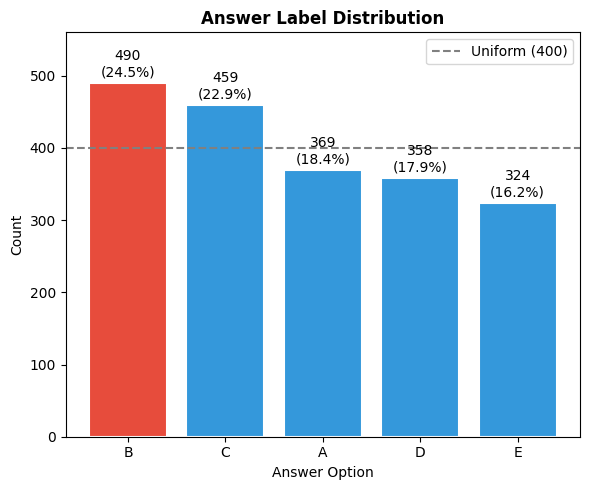

In [237]:
plt.figure(figsize=(6,5))

vc = train["answer"].value_counts()
colors = ["#e74c3c" if v == vc.max() else "#3498db" for v in vc.values]

bars = plt.bar(vc.index, vc.values, color=colors, edgecolor="white", linewidth=1.5)
plt.axhline(y=len(train)/5, color="gray", linestyle="--", linewidth=1.5, label="Uniform (400)")

for bar, val in zip(bars, vc.values):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()+5,
             f"{val}\n({val/len(train)*100:.1f}%)",
             ha="center", va="bottom", fontsize=10)

plt.title("Answer Label Distribution", fontweight="bold")
plt.xlabel("Answer Option")
plt.ylabel("Count")
plt.legend()
plt.ylim(0, 560)

plt.tight_layout()
plt.show()

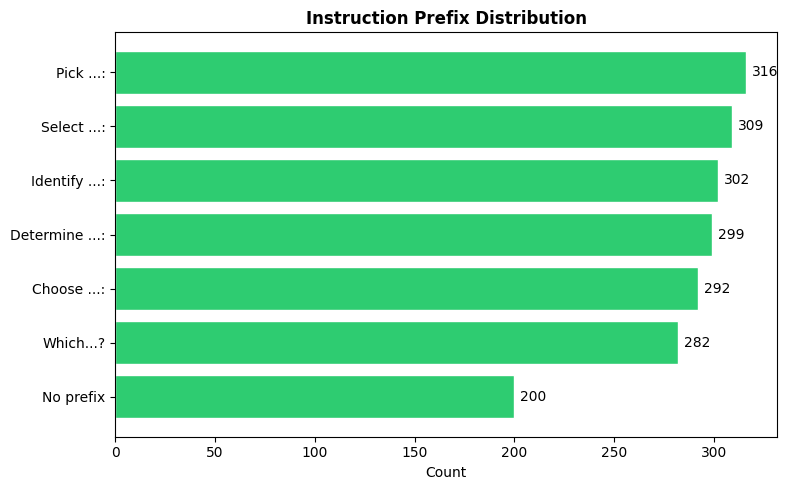

In [238]:
plt.figure(figsize=(8,5))

pvc = train["prefix_type"].value_counts()

short_labels = [
    p.replace("the best possible answer","...")
     .replace("the most accurate option","...")
     .replace("the correct option","...")
     .replace("the correct statement","...")
     .replace("the correct answer","...")
     .replace("Which of the following is correct?","Which...?")
     .replace("NONE","No prefix")
    for p in pvc.index
]

plt.barh(short_labels, pvc.values, color="#2ecc71", edgecolor="white")

for i, v in enumerate(pvc.values):
    plt.text(v+3, i, str(v), va="center", fontsize=10)

plt.title("Instruction Prefix Distribution", fontweight="bold")
plt.xlabel("Count")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

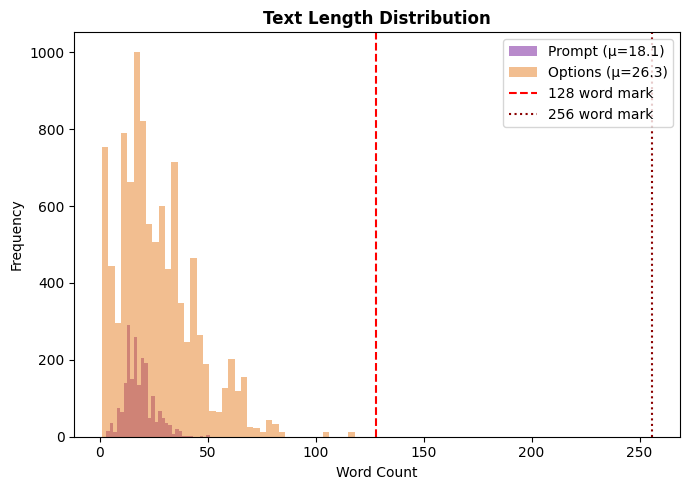

In [239]:
plt.figure(figsize=(7,5))

plen = train["prompt"].str.split().apply(len)
olen = pd.concat([train[c].str.split().apply(len) for c in Options])

plt.hist(plen, bins=30, alpha=0.7, color="#9b59b6",
         label=f"Prompt (μ={plen.mean():.1f})")

plt.hist(olen, bins=40, alpha=0.5, color="#e67e22",
         label=f"Options (μ={olen.mean():.1f})")

plt.axvline(x=128, color="red", linestyle="--", linewidth=1.5,
            label="128 word mark")
plt.axvline(x=256, color="darkred", linestyle=":", linewidth=1.5,
            label="256 word mark")

plt.title("Text Length Distribution", fontweight="bold")
plt.xlabel("Word Count")
plt.ylabel("Frequency")
plt.legend()

plt.tight_layout()
plt.show()

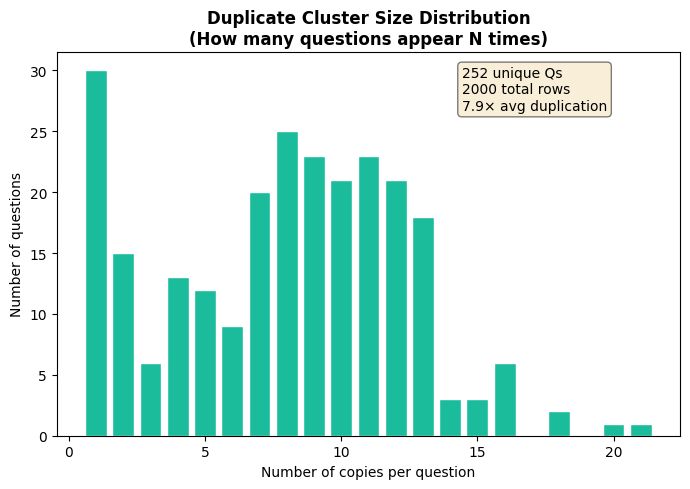

In [240]:
plt.figure(figsize=(7,5))

PREFIX_PATTERNS = [
    r"^pick the best possible answer:?\s*",
    r"^select the most accurate option:?\s*",
    r"^determine the correct option:?\s*",
    r"^identify the correct statement:?\s*",
    r"^which of the following is correct\??\s*",
    r"^choose the correct answer:?\s*"
]

SUFFIX_PATTERNS = [
    r"\s*carefully\.?$",
    r"\s*based on the given context\.?$",
    r"\s*from the following choices\.?$",
    r"\s*among the listed options\.?$"
]

def strip_wrapper(t):
    t = t.lower().strip()
    for p in PREFIX_PATTERNS:
        t = re.sub(p, "", t)
    for p in SUFFIX_PATTERNS:
        t = re.sub(p, "", t)
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9\s]", " ", t)).strip()

train["core"] = train["prompt"].apply(strip_wrapper)

dup = train["core"].value_counts()
cluster_sizes = dup.value_counts().sort_index()

plt.bar(cluster_sizes.index, cluster_sizes.values,
        color="#1abc9c", edgecolor="white")

plt.title(
    "Duplicate Cluster Size Distribution\n(How many questions appear N times)",
    fontweight="bold"
)

plt.xlabel("Number of copies per question")
plt.ylabel("Number of questions")

plt.text(
    0.65,
    0.85,
    "252 unique Qs\n2000 total rows\n7.9× avg duplication",
    transform=plt.gca().transAxes,
    fontsize=10,
    bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5)
)

plt.tight_layout()
plt.show()

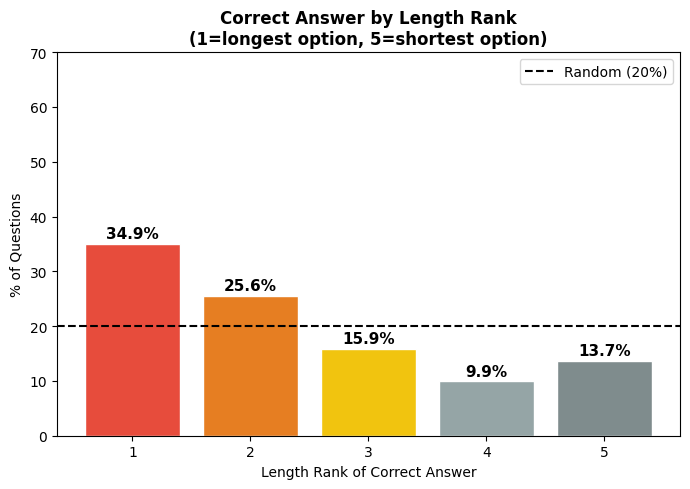

In [241]:
plt.figure(figsize=(7,5))

def answer_length_rank(row):
    lens = sorted(
        [(c, len(row[c].split())) for c in Options],
        key=lambda x: -x[1]
    )
    rank_map = {c: r+1 for r, (c, _) in enumerate(lens)}
    return rank_map[row["answer"]]

train["ans_len_rank"] = train.apply(answer_length_rank, axis=1)

rank_counts = train["ans_len_rank"].value_counts().sort_index()
rank_pct = rank_counts / len(train) * 100

bars = plt.bar(
    rank_counts.index,
    rank_pct.values,
    color=["#e74c3c","#e67e22","#f1c40f","#95a5a6","#7f8c8d"],
    edgecolor="white"
)

plt.axhline(y=20, color="black", linestyle="--",
            linewidth=1.5, label="Random (20%)")

for bar, val in zip(bars, rank_pct.values):
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height()+0.5,
        f"{val:.1f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.title(
    "Correct Answer by Length Rank\n(1=longest option, 5=shortest option)",
    fontweight="bold"
)

plt.xlabel("Length Rank of Correct Answer")
plt.ylabel("% of Questions")
plt.legend()
plt.ylim(0, 70)

plt.tight_layout()
plt.show()

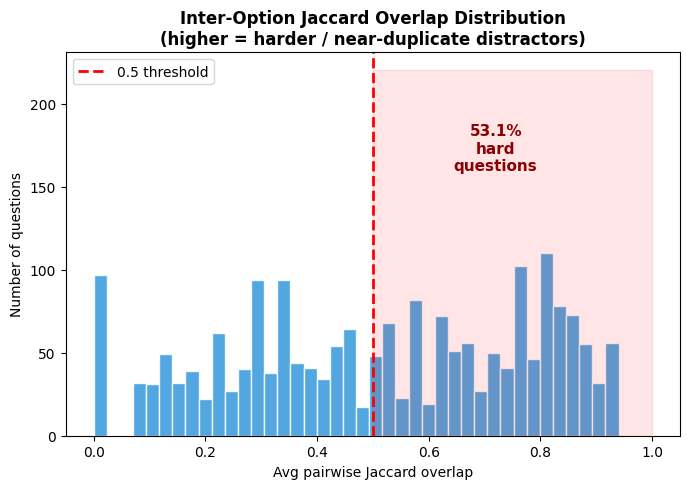

In [242]:
from itertools import combinations

plt.figure(figsize=(7,5))

def jac(a, b):
    return len(a & b) / len(a | b) if a | b else 0.0

def toks(t):
    return set(re.findall(r"[a-z0-9]+", t.lower()))

ov_list = [
    np.mean([
        jac(toks(row[a]), toks(row[b]))
        for a, b in combinations(Options, 2)
    ])
    for _, row in train.iterrows()
]

ov_s = pd.Series(ov_list)

plt.hist(
    ov_s,
    bins=40,
    color="#3498db",
    edgecolor="white",
    alpha=0.85
)

plt.axvline(
    x=0.5,
    color="red",
    linestyle="--",
    linewidth=2,
    label="0.5 threshold"
)

plt.fill_betweenx([0,220], 0.5, 1.0, alpha=0.1, color="red")

plt.text(
    0.72,
    160,
    f"{(ov_s>0.5).mean():.1%}\nhard\nquestions",
    ha="center",
    fontsize=11,
    color="darkred",
    fontweight="bold"
)

plt.title(
    "Inter-Option Jaccard Overlap Distribution\n(higher = harder / near-duplicate distractors)",
    fontweight="bold"
)

plt.xlabel("Avg pairwise Jaccard overlap")
plt.ylabel("Number of questions")
plt.legend()

plt.tight_layout()
plt.show()

In [243]:
print(f"\nThe LONGEST option is the correct answer: {(train['ans_len_rank']==1).mean():.1%} of the time")
print(f"Random baseline would be:                  20.0%")
print(f"Lift over random:                          {(train['ans_len_rank']==1).mean()/0.20:.1f}x")



The LONGEST option is the correct answer: 34.9% of the time
Random baseline would be:                  20.0%
Lift over random:                          1.7x


In [244]:
train["option_overlap"] = [
    np.mean([jaccard(tok_set(row[a]), tok_set(row[b]))
             for a, b in combinations(Options, 2)])
    for _, row in train.iterrows()
]
train["option_overlap"]

0       0.306770
1       0.760694
2       0.000000
3       0.306770
4       0.451501
          ...   
1995    0.613889
1996    0.846537
1997    0.814206
1998    0.240302
1999    0.940000
Name: option_overlap, Length: 2000, dtype: float64

In [245]:
print(f"option_overlap column added. Range: {train['option_overlap'].min():.3f} - {train['option_overlap'].max():.3f}")

option_overlap column added. Range: 0.000 - 0.940


In [246]:
print("HARDEST question (options 94% identical by word overlap)")
print("The correct answer differs by a SINGLE SYMBOL from two wrong options")

hardest = train.loc[train["option_overlap"].idxmax()]
print(f"\nPrompt  : {hardest['prompt']}")
print(f"Overlap : {hardest['option_overlap']:.3f}")
print(f"Correct : {hardest['answer']}\n")

HARDEST question (options 94% identical by word overlap)
The correct answer differs by a SINGLE SYMBOL from two wrong options

Prompt  : Which of the following statements accurately describes the characteristics of gravitational waves?
Overlap : 0.940
Correct : C



In [247]:
for c in Options:
    marker = " <-- CORRECT" if hardest["answer"] == c else ""
    print(f"  {c}: {hardest[c][:120]}{marker}")

  A: Gravitational waves have an amplitude denoted by h, which represents the size of the wave. The amplitude varies with tim
  B: Gravitational waves have an amplitude denoted by λ, which represents the distance between points of maximum stretch or s
  C: Gravitational waves have an amplitude denoted by h, which represents the size of the wave. The amplitude varies with tim <-- CORRECT
  D: Gravitational waves have an amplitude denoted by f, which represents the frequency of the wave's oscillation. The amplit
  E: Gravitational waves have an amplitude denoted by f, which represents the frequency of the wave's oscillation. The amplit


##### Observation: 
Options A and C are IDENTICAL in first 120 characters.
Options D and E are IDENTICAL to each other.
The only differentiator is the symbol used: h (correct) vs λ vs f.
A bag-of-words model sees the same token set in all 5 options.
Only a model that understands what these symbols mean can answer this.

In [248]:
print("EASIEST QUESTION - options share zero vocabulary")


easiest = train.loc[train["option_overlap"].idxmin()]
print(f"\nPrompt  : {easiest['prompt']}")
print(f"Overlap : {easiest['option_overlap']:.3f}")
print(f"Correct : {easiest['answer']}\n")


EASIEST QUESTION - options share zero vocabulary

Prompt  : Determine the correct option: What is the term used in astrophysics to describe light-matter interactions resulting in energy shifts in the radiation field? among the listed options.
Overlap : 0.000
Correct : C



In [249]:
for c in Options:
    marker = " <-- CORRECT" if easiest["answer"] == c else ""
    print(f"  {c}: {easiest[c]}{marker}")

  A: Blueshifting
  B: Redshifting
  C: Reddening <-- CORRECT
  D: Whitening
  E: Yellowing


In [250]:
def get_question_word(t: str) -> str:
    # Strip instruction prefix first, then find the actual question word
    t_stripped = re.sub(r"^[A-Z][^:]+:\s*", "", t)
    m = re.match(r"^(What|Which|Who|How|Why)\b", t_stripped, re.I)
    return m.group(1).lower() if m else "other"

In [251]:
train["q_word"] = train["prompt"].apply(get_question_word)
train["q_word"].value_counts()

q_word
what     1534
which     383
who        55
how        26
other       2
Name: count, dtype: int64

In [252]:
print("QUESTION WORD DISTRIBUTION:")
qw = train["q_word"].value_counts()
print(qw.to_string())
print(f"\n→ {qw['what']/len(train):.1%} of questions are 'What is...' factual definition questions")
print(f"→ {qw['which']/len(train):.1%} are 'Which of the following...' statement-evaluation questions")
print(f"→ These two types require different reasoning strategies:")
print(f"   'What' = retrieve the correct fact")
print(f"   'Which' = evaluate which statement correctly describes a fact")

QUESTION WORD DISTRIBUTION:
q_word
what     1534
which     383
who        55
how        26
other       2

→ 76.7% of questions are 'What is...' factual definition questions
→ 19.1% are 'Which of the following...' statement-evaluation questions
→ These two types require different reasoning strategies:
   'What' = retrieve the correct fact
   'Which' = evaluate which statement correctly describes a fact


In [253]:
DOMAIN_KEYWORDS = {
    "Physics / Astronomy" : [
        "quantum", "photon", "relativity", "force", "energy", "wave", "spin",
        "field", "entropy", "gravity", "superconductor", "boson", "fermion",
        "hamiltonian", "symmetry", "thermodynamic", "star", "galaxy", "pulsar",
        "redshift", "supernova", "universe", "dark matter", "black hole"
    ],
    "Chemistry / Materials" : [
        "molecule", "ion", "bond", "acid", "reaction", "enzyme", "protein",
        "membrane", "polymer", "crystal", "alloy", "metal", "orbital", "catalyst",
        "ferromagnetic", "memristor", "piezoelectric"
    ],
    "Biology" : [
        "cell", "gene", "organism", "evolution", "mammal", "plant", "bacteria",
        "virus", "dna", "rna", "chromosome", "phage", "myrmecophyte", "mammary"
    ],
    "Math / CS" : [
        "function", "theorem", "matrix", "vector", "topology", "algebra", "group",
        "manifold", "integral", "algorithm", "polytope", "quantization"
    ],
}
#DOMAIN_KEYWORDS

In [254]:
from collections import Counter

DATA_DIR = "/kaggle/input/competitions/smart-mcq-solver-challenge"
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test  = pd.read_csv(f"{DATA_DIR}/test.csv")


# Initial Sumission 

In [255]:


# Options = ["A", "B", "C", "D", "E"]

# for c in ["prompt"] + Options:
#     train[c] = train[c].fillna("").astype(str)
#     test[c]  = test[c].fillna("").astype(str)

# PREFIX_PATTERNS = [
#     r"^pick the best possible answer:?\s*",
#     r"^select the most accurate option:?\s*",
#     r"^determine the correct option:?\s*",
#     r"^identify the correct statement:?\s*",
#     r"^which of the following is correct\??\s*",
#     r"^choose the correct answer:?\s*",
# ]
# SUFFIX_PATTERNS = [
#     r"\s*carefully\.?$",
#     r"\s*based on the given context\.?$",
#     r"\s*from the following choices\.?$",
#     r"\s*among the listed options\.?$",
# ]

# def strip_wrapper(t: str) -> str:
#     t = t.lower().strip()
#     for p in PREFIX_PATTERNS: t = re.sub(p, "", t)
#     for p in SUFFIX_PATTERNS: t = re.sub(p, "", t)
#     t = re.sub(r"[^a-z0-9\s]", " ", t)
#     return re.sub(r"\s+", " ", t).strip()

# train["core"] = train["prompt"].apply(strip_wrapper)
# test["core"]  = test["prompt"].apply(strip_wrapper)

# # Build lookup: core question → correct answer letter
# # If a core question has multiple rows (duplicates), take the unanimous answer
# lookup = (
#     train.groupby("core")["answer"]
#     .agg(lambda s: Counter(s).most_common(1)[0][0])
#     .to_dict()
# )

# # Global fallback: most common answers in case of no match
# global_top3 = train["answer"].value_counts().index[:3].tolist()

# print(f"Lookup table size: {len(lookup)} unique questions")
# print(f"Test rows with match: {test['core'].isin(lookup).sum()} / {len(test)}")
# print(f"Global fallback top3: {global_top3}")

# # Generate predictions
# predictions = []
# for _, row in test.iterrows():
#     core = row["core"]
#     if core in lookup:
#         top1 = lookup[core]
#         # Fill ranks 2 and 3 with next most common labels
#         rest = [x for x in global_top3 if x != top1][:2]
#         predictions.append(" ".join([top1] + rest))
#     else:
#         predictions.append(" ".join(global_top3))

# submission = pd.DataFrame({
#     "ID":         test["id"],
#     "Prediction": predictions
# })

# submission.to_csv("submission.csv", index=False)

# print(f"\nSubmission shape: {submission.shape}")
# print(f"Sample predictions:")
# print(submission.head(10).to_string())
# print(f"\nUnique predictions: {submission['Prediction'].nunique()}")
# print("\n.....readyyyyyyy submission.csv ready — upload this to Kaggle now")

In [256]:
def classify_domain(t: str) -> str:
    t_low = t.lower()
    scores = {d: sum(1 for kw in kws if kw in t_low) for d, kws in DOMAIN_KEYWORDS.items()}
    best = max(scores, key=scores.get)
    return best if scores[best] > 0 else "General / Other"


In [257]:
# train["domain"] = (train["prompt"] + " " + train["A"] + " " + train["B"]).apply(classify_domain)

# print("SUBJECT DOMAIN DISTRIBUTION:")
# domain_counts = train["domain"].value_counts()
# print(domain_counts.to_string())

# print("\nCORRECT ANSWER DISTRIBUTION BY DOMAIN:")
# for d in domain_counts.index:
#     subset = train[train["domain"] == d]
#     dist = subset["answer"].value_counts(normalize=True).round(3).to_dict()
#     print(f"  {d} (n={len(subset):4d}): {dist}")

In [258]:
# fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# fig.suptitle("Question Structure & Domain Analysis", fontsize=14, fontweight="bold")

# ax = axes[0]
# qw_plot = train["q_word"].value_counts()
# colors_qw = ["#e74c3c","#3498db","#2ecc71","#f39c12","#9b59b6"]
# bars = ax.bar(qw_plot.index, qw_plot.values,
#               color=colors_qw[:len(qw_plot)], edgecolor="white")
# for bar, val in zip(bars, qw_plot.values):
#     ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+5,
#             f"{val}\n({val/len(train)*100:.1f}%)",
#             ha="center", va="bottom", fontsize=10)
# ax.set_title("Question Word Distribution", fontweight="bold")
# ax.set_xlabel("First question word")
# ax.set_ylabel("Count")
# ax.set_ylim(0, 1700)

# ax = axes[1]
# dc = train["domain"].value_counts()
# short_labels = [d.replace(" / ", "\n") for d in dc.index]
# colors_d = ["#3498db","#e67e22","#2ecc71","#9b59b6","#1abc9c"]
# wedges, texts, autotexts = ax.pie(
#     dc.values,
#     labels=short_labels,
#     autopct="%1.1f%%",
#     colors=colors_d[:len(dc)],
#     startangle=140,
#     pctdistance=0.75,
#     textprops={"fontsize": 10}
# )
# for at in autotexts:
#     at.set_fontweight("bold")
# ax.set_title("Subject Domain Distribution", fontweight="bold")

# plt.tight_layout()
# plt.savefig("eda_domain_plots.png", dpi=150, bbox_inches="tight")
# plt.show()
# print("Saved: eda_domain_plots.png")

In [259]:
# pip install wandb

In [260]:
# wandb login

In [261]:
# import random

# import wandb

# # Start a new wandb run to track this script.
# run = wandb.init(
#     # Set the wandb entity where your project will be logged (generally your team name).
#     entity="22f3002567-indian-institute-of-technology-madras",
#     # Set the wandb project where this run will be logged.
#     project="22f3002567-t22026",
#     # Track hyperparameters and run metadata.
#     config={
#         "learning_rate": 0.02,
#         "architecture": "CNN",
#         "dataset": "CIFAR-100",
#         "epochs": 10,
#     },
# )

# # Simulate training.
# epochs = 10
# offset = random.random() / 5
# for epoch in range(2, epochs):
#     acc = 1 - 2**-epoch - random.random() / epoch - offset
#     loss = 2**-epoch + random.random() / epoch + offset

#     # Log metrics to wandb.
#     run.log({"acc": acc, "loss": loss})

# # Finish the run and upload any remaining data.
# run.finish()

In [262]:
# !pip install wandb -q

# import wandb
# import os

# # On Kaggle: Add your W&B API key via
# # Notebook Settings → Add-ons → Secrets → Add Secret → Name: WANDB_API_KEY
# from kaggle_secrets import UserSecretsClient
# os.environ["WANDB_API_KEY"] = UserSecretsClient().get_secret("WANDB_API_KEY")

# wandb.login()

# WANDB_PROJECT = "22f3002567-t22026"
# SEED = 42

# print(f"W&B project: {WANDB_PROJECT}")
# print("Login successful ✓")

In [263]:
# from sklearn.model_selection import GroupKFold
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.preprocessing import normalize
# from gensim.models import Word2Vec
# from gensim.utils import simple_preprocess



# def apk(actual, pred, k=3):
#     pred = pred[:k]
#     return 1.0 / (pred.index(actual) + 1) if actual in pred else 0.0

# def mapk(actuals, preds, k=3):
#     return float(np.mean([apk(a, p, k) for a, p in zip(actuals, preds)]))


# def clean_text(text: str) -> str:
#     text = text.lower()
#     text = re.sub(r"http\S+|www\S+", " ", text)
#     text = re.sub(r"[^a-z0-9\s]", " ", text)
#     return re.sub(r"\s+", " ", text).strip()

# def tokenize(text: str) -> list:
#     return simple_preprocess(text, deacc=True)

# # Apply cleaning
# print("Applying text cleaning...")
# for c in ["prompt"] + Options:
#     train[f"{c}_clean"] = train[c].apply(clean_text)
#     train[f"{c}_tok"]   = train[f"{c}_clean"].apply(tokenize)
#     test[f"{c}_clean"]  = test[c].apply(clean_text)
#     test[f"{c}_tok"]    = test[f"{c}_clean"].apply(tokenize)

# print("Done ✓")



# gkf    = GroupKFold(n_splits=5)
# splits = list(gkf.split(train, groups=train["group"]))

# print(f"\nGrouped 5-fold CV splits:")
# for i, (tr_idx, va_idx) in enumerate(splits):
#     print(f"  Fold {i}: train={len(tr_idx)} rows "
#           f"({train.iloc[tr_idx]['group'].nunique()} unique Qs) | "
#           f"val={len(va_idx)} rows "
#           f"({train.iloc[va_idx]['group'].nunique()} unique Qs)")


# def row_cosine(a, b):
#     """Row-wise cosine similarity between two sparse matrices."""
#     a = normalize(a)
#     b = normalize(b)
#     return np.asarray(a.multiply(b).sum(axis=1)).flatten()

# def minmax_scale(x):
#     """Scale rows to [0,1] for ensemble blending."""
#     mn = x.min(axis=1, keepdims=True)
#     mx = x.max(axis=1, keepdims=True)
#     return (x - mn) / (mx - mn + 1e-9)

In [264]:
WANDB_PROJECT = "22f3002567-t22026"
WANDB_ENTITY = "22f3002567-indian-institute-of-technology-madras"

In [265]:
try:
    from kaggle_secrets import UserSecretsClient
    os.environ["WANDB_API_KEY"] = UserSecretsClient().get_secret("WANDB_API_KEY")
    wandb.login(key=os.environ["WANDB_API_KEY"], relogin=True)
    WANDB_OK = True
    print("W&B login successful ✓")
    print(f"Project: {WANDB_PROJECT}")
except Exception as e:
    print(f"W&B login failed: {e}")
    print("→ Add WANDB_API_KEY to: Add-ons → Secrets")
    WANDB_OK = False

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: WARNING [wandb.login()] Changing session credentials to explicit value for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


W&B login successful ✓
Project: 22f3002567-t22026


In [266]:
import random

import wandb

# Start a new wandb run to track this script.
run = wandb.init(
    # Set the wandb entity where your project will be logged (generally your team name).
    entity="22f3002567-indian-institute-of-technology-madras",
    # Set the wandb project where this run will be logged.
    project="22f3002567-t22026",
    # Track hyperparameters and run metadata.
    config={
        "learning_rate": 0.02,
        "architecture": "CNN",
        "dataset": "CIFAR-100",
        "epochs": 10,
    },
)

# Simulate training.
epochs = 10
offset = random.random() / 5
for epoch in range(2, epochs):
    acc = 1 - 2**-epoch - random.random() / epoch - offset
    loss = 2**-epoch + random.random() / epoch + offset

    # Log metrics to wandb.
    run.log({"acc": acc, "loss": loss})

# Finish the run and upload any remaining data.
run.finish()

acc,▁▃▂▇█▆█▇
loss,██▆▃▂▁▂▁
acc,0.80961
loss,0.15433


# Model 1

In [267]:
SEED = 42

In [268]:
run_tfidf = wandb.init(
    project = WANDB_PROJECT,
    name    = "model1a-tfidf-cosine",
    config  = {
        "model_type" : "from_scratch",
        "approach" : "TF-IDF cosine similarity",
        "max_features": 20000,
        "ngram_range" : "(1,2)",
        "stop_words"  : "english",
        "sublinear_tf": True,
        "cv_strategy" : "GroupKFold-5",
        "eval_metric" : "mAP@3",
        "seed"  : SEED,
    }
)

In [269]:
def tfidf_predict(df, vectorizer):
    pm   = vectorizer.transform(df["prompt_clean"])
    sims = np.zeros((len(df), 5))
    for j, c in enumerate(Options):
        sims[:, j] = row_cosine(pm, vectorizer.transform(df[f"{c}_clean"]))
    order = np.argsort(-sims, axis=1)
    preds = [[Options[i] for i in row] for row in order]
    return preds, sims

In [270]:
import pandas as pd
import numpy as np
import re
import os
import random
import wandb
from itertools import combinations
from collections import Counter
from sklearn.model_selection import GroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess
import matplotlib.pyplot as plt

In [271]:
def strip_wrapper(t: str) -> str:
    t = t.lower().strip()
    for p in PREFIX_PATTERNS: t = re.sub(p, "", t)
    for p in SUFFIX_PATTERNS: t = re.sub(p, "", t)
    t = re.sub(r"[^a-z0-9\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

def clean_text(t: str) -> str:
    t = t.lower()
    t = re.sub(r"http\S+|www\S+", " ", t)
    t = re.sub(r"[^a-z0-9\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

def tokenize(t: str) -> list:
    return simple_preprocess(t, deacc=True)



In [272]:
# Feature columns 
train["core"]  = train["prompt"].apply(strip_wrapper)
test["core"]   = test["prompt"].apply(strip_wrapper)
train["group"] = train["core"].astype("category").cat.codes

for c in ["prompt"] + Options:
    train[f"{c}_clean"] = train[c].apply(clean_text)
    train[f"{c}_tok"]   = train[f"{c}_clean"].apply(tokenize)
    test[f"{c}_clean"]  = test[c].apply(clean_text)
    test[f"{c}_tok"]    = test[f"{c}_clean"].apply(tokenize)

# mAP@3 
def apk(actual, pred, k=3):
    pred = pred[:k]
    return 1.0 / (pred.index(actual) + 1) if actual in pred else 0.0

def mapk(actuals, preds, k=3):
    return float(np.mean([apk(a, p, k) for a, p in zip(actuals, preds)]))

# Grouped CV splits 
gkf    = GroupKFold(n_splits=5)
splits = list(gkf.split(train, groups=train["group"]))

#  Helpers
def row_cosine(a, b):
    a = normalize(a); b = normalize(b)
    return np.asarray(a.multiply(b).sum(axis=1)).flatten()

def minmax_scale(x):
    mn = x.min(axis=1, keepdims=True)
    mx = x.max(axis=1, keepdims=True)
    return (x - mn) / (mx - mn + 1e-9)

# Retrieval lookup (Model 3 baseline) 
lookup     = train.groupby("core")["answer"].agg(
    lambda s: Counter(s).most_common(1)[0][0]).to_dict()
global_top3 = train["answer"].value_counts().index[:3].tolist()

In [273]:
tfidf_fold_scores = []

for fold, (tr_idx, va_idx) in enumerate(splits):
    tr_df = train.iloc[tr_idx]
    va_df = train.iloc[va_idx]

    corpus = pd.concat([tr_df[f"{c}_clean"] for c in ["prompt"] + Options])
    vec = TfidfVectorizer(max_features=20000, ngram_range=(1,2),
                          stop_words="english", sublinear_tf=True)
    vec.fit(corpus)

    preds, _ = tfidf_predict(va_df, vec)
    score    = mapk(va_df["answer"].tolist(), preds)
    tfidf_fold_scores.append(score)

    wandb.log({"fold": fold, "val_map3": score, "model": "tfidf"})
    print(f"  Fold {fold}: val={len(va_df)} rows  mAP@3={score:.4f}")

tfidf_cv_mean = np.mean(tfidf_fold_scores)
tfidf_cv_std  = np.std(tfidf_fold_scores)

print(f"\nModel 1a TF-IDF | CV mAP@3: {tfidf_cv_mean:.4f} ± {tfidf_cv_std:.4f}")
print(f"Naive baseline  : 0.4213")
print(f"Result: {'BEATS naive ✓' if tfidf_cv_mean > 0.4213 else 'BELOW naive ✗ — confirms EDA prediction'}")

# Full train fit for later ensemble
full_corpus = pd.concat([train[f"{c}_clean"] for c in ["prompt"] + Options])
tfidf_final = TfidfVectorizer(max_features=20000, ngram_range=(1,2),
                               stop_words="english", sublinear_tf=True)
tfidf_final.fit(full_corpus)
tfidf_test_preds,  tfidf_test_sims  = tfidf_predict(test,  tfidf_final)
tfidf_train_preds, tfidf_train_sims = tfidf_predict(train, tfidf_final)



  Fold 0: val=400 rows  mAP@3=0.3108
  Fold 1: val=400 rows  mAP@3=0.3571
  Fold 2: val=400 rows  mAP@3=0.2829
  Fold 3: val=400 rows  mAP@3=0.2696
  Fold 4: val=400 rows  mAP@3=0.3504

Model 1a TF-IDF | CV mAP@3: 0.3142 ± 0.0350
Naive baseline  : 0.4213
Result: BELOW naive ✗ — confirms EDA prediction


In [274]:
wandb.log({
    "cv_mean_map3"  : tfidf_cv_mean,
    "cv_std_map3"   : tfidf_cv_std,
    "naive_baseline": 0.4213,
    "beats_naive"   : int(tfidf_cv_mean > 0.4213),
})
run_tfidf.finish()
print("W&B run finished ✓")

beats_naive,▁
cv_mean_map3,▁
cv_std_map3,▁
fold,▁▃▅▆█
naive_baseline,▁
val_map3,▄█▂▁▇
beats_naive,0
cv_mean_map3,0.31417
cv_std_map3,0.03502
fold,4
model,tfidf


W&B run finished ✓


# Model 1.b

In [275]:
run_w2v = wandb.init(
    project = WANDB_PROJECT,
    name    = "model1b-word2vec-cosine",
    config  = {
        "model_type"  : "from_scratch",
        "approach"    : "Word2Vec mean-pool cosine",
        "vector_size" : 150,
        "window"      : 5,
        "min_count"   : 2,
        "epochs"      : 15,
        "sg"          : 1,
        "cv_strategy" : "GroupKFold-5",
        "eval_metric" : "mAP@3",
        "seed"        : SEED,
    }
)

In [276]:
def sentence_vector(tokens, model):
    vecs = [model.wv[t] for t in tokens if t in model.wv]
    return np.mean(vecs, axis=0) if vecs else np.zeros(model.vector_size)

def w2v_predict(df, model):
    pv   = np.vstack(df["prompt_tok"].apply(lambda t: sentence_vector(t, model)))
    sims = np.zeros((len(df), 5))
    for j, c in enumerate(Options):
        ov  = np.vstack(df[f"{c}_tok"].apply(lambda t: sentence_vector(t, model)))
        num = np.sum(pv * ov, axis=1)
        den = (np.linalg.norm(pv, axis=1) * np.linalg.norm(ov, axis=1)) + 1e-9
        sims[:, j] = num / den
    order = np.argsort(-sims, axis=1)
    preds = [[Options[i] for i in row] for row in order]
    return preds, sims

In [277]:

w2v_fold_scores = []

for fold, (tr_idx, va_idx) in enumerate(splits):
    tr_df = train.iloc[tr_idx]
    va_df = train.iloc[va_idx]

    corpus = [t for c in ["prompt"] + Options
                for t in tr_df[f"{c}_tok"].tolist()]

    model_w2v = Word2Vec(
        sentences=corpus, vector_size=150, window=5,
        min_count=2, workers=2, epochs=15, sg=1, seed=SEED
    )

    preds, _ = w2v_predict(va_df, model_w2v)
    score    = mapk(va_df["answer"].tolist(), preds)
    w2v_fold_scores.append(score)

    wandb.log({"fold": fold, "val_map3": score, "model": "word2vec"})
    print(f"  Fold {fold}: val={len(va_df)} rows  mAP@3={score:.4f}")

w2v_cv_mean = np.mean(w2v_fold_scores)
w2v_cv_std  = np.std(w2v_fold_scores)
print(f"\nModel 1b Word2Vec | CV mAP@3: {w2v_cv_mean:.4f} ± {w2v_cv_std:.4f}")
print(f"Naive baseline    : 0.4213")
print(f"Result: {'BEATS naive ✓' if w2v_cv_mean > 0.4213 else 'BELOW naive ✗ - confirms EDA prediction'}")


  Fold 0: val=400 rows  mAP@3=0.3438
  Fold 1: val=400 rows  mAP@3=0.4096
  Fold 2: val=400 rows  mAP@3=0.3762
  Fold 3: val=400 rows  mAP@3=0.4017
  Fold 4: val=400 rows  mAP@3=0.3212

Model 1b Word2Vec | CV mAP@3: 0.3705 ± 0.0337
Naive baseline    : 0.4213
Result: BELOW naive ✗ - confirms EDA prediction


In [278]:
# Full train corpus for final model
full_corpus_w2v = [t for c in ["prompt"] + Options
                   for t in train[f"{c}_tok"].tolist() + test[f"{c}_tok"].tolist()]
w2v_final = Word2Vec(
    sentences=full_corpus_w2v, vector_size=150, window=5,
    min_count=2, workers=2, epochs=15, sg=1, seed=SEED
)
w2v_test_preds,  w2v_test_sims  = w2v_predict(test,  w2v_final)
w2v_train_preds, w2v_train_sims = w2v_predict(train, w2v_final)

wandb.log({
    "cv_mean_map3"  : w2v_cv_mean,
    "cv_std_map3"   : w2v_cv_std,
    "naive_baseline": 0.4213,
    "beats_naive"   : int(w2v_cv_mean > 0.4213),
})
run_w2v.finish()
print("W&B run finished ✓")

beats_naive,▁
cv_mean_map3,▁
cv_std_map3,▁
fold,▁▃▅▆█
naive_baseline,▁
val_map3,▃█▅▇▁
beats_naive,0
cv_mean_map3,0.3705
cv_std_map3,0.03368
fold,4
model,word2vec


W&B run finished ✓


In [279]:
from sentence_transformers import SentenceTransformer

print("Loading all-MiniLM-L6-v2...")
minilm = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
print("Model loaded ✓")


Loading all-MiniLM-L6-v2...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model loaded ✓


In [280]:
run_minilm = wandb.init(
    project = WANDB_PROJECT,
    name    = "model2-minilm-cosine",
    config  = {
        "model_type"    : "pretrained",
        "model_name"    : "all-MiniLM-L6-v2",
        "approach"      : "Sentence-Transformer cosine similarity",
        "embedding_dim" : 384,
        "pooling"       : "mean",
        "normalize"     : True,
        "batch_size"    : 64,
        "cv_strategy"   : "GroupKFold-5",
        "eval_metric"   : "mAP@3",
        "fine_tuned"    : False,
    }
)

In [281]:
def minilm_predict(df, model, batch_size=64):
    
    # normalize_embeddings=True → dot product = cosine similarity
    prompt_embs = model.encode(
        df["prompt"].tolist(),
        batch_size=batch_size,
        normalize_embeddings=True,
        show_progress_bar=False
    )
    sims = np.zeros((len(df), 5))
    for j, c in enumerate(Options):
        opt_embs = model.encode(
            df[c].tolist(),
            batch_size=batch_size,
            normalize_embeddings=True,
            show_progress_bar=False
        )
        # Row-wise dot product = cosine sim (since both are unit vectors)
        sims[:, j] = np.sum(prompt_embs * opt_embs, axis=1)

    order = np.argsort(-sims, axis=1)
    preds = [[Options[i] for i in row] for row in order]
    return preds, sims

In [282]:

minilm_fold_scores = []

for fold, (tr_idx, va_idx) in enumerate(splits):
    va_df = train.iloc[va_idx]

    # No fitting needed — pretrained model used as-is
    preds, _ = minilm_predict(va_df, minilm)
    score    = mapk(va_df["answer"].tolist(), preds)
    minilm_fold_scores.append(score)

    wandb.log({"fold": fold, "val_map3": score, "model": "minilm"})
    print(f"  Fold {fold}: val={len(va_df)} rows  mAP@3={score:.4f}")

minilm_cv_mean = np.mean(minilm_fold_scores)
minilm_cv_std  = np.std(minilm_fold_scores)

print(f"\nModel 2 MiniLM | CV mAP@3: {minilm_cv_mean:.4f} ± {minilm_cv_std:.4f}")
print(f"Naive baseline : 0.4213")
print(f"TF-IDF CV      : {tfidf_cv_mean:.4f}")
print(f"Result vs naive: {'✓ BEATS naive' if minilm_cv_mean > 0.4213 else '✗ below naive'}")
print(f"Result vs tfidf: {'✓ BEATS TF-IDF' if minilm_cv_mean > tfidf_cv_mean else '✗ below TF-IDF'}")

# Encode full train + test for ensemble use
print("\nEncoding full train set...")
minilm_train_preds, minilm_train_sims = minilm_predict(train, minilm)
print("Encoding full test set...")
minilm_test_preds,  minilm_test_sims  = minilm_predict(test,  minilm)
wandb.log({
    "cv_mean_map3"      : minilm_cv_mean,
    "cv_std_map3"       : minilm_cv_std,
    "naive_baseline"    : 0.4213,
    "tfidf_cv_mean"     : tfidf_cv_mean,
    "beats_naive"       : int(minilm_cv_mean > 0.4213),
    "beats_tfidf"       : int(minilm_cv_mean > tfidf_cv_mean),
})
run_minilm.finish()
print("W&B run finished ✓")


  Fold 0: val=400 rows  mAP@3=0.4571
  Fold 1: val=400 rows  mAP@3=0.3879
  Fold 2: val=400 rows  mAP@3=0.3950
  Fold 3: val=400 rows  mAP@3=0.4542
  Fold 4: val=400 rows  mAP@3=0.4213

Model 2 MiniLM | CV mAP@3: 0.4231 ± 0.0288
Naive baseline : 0.4213
TF-IDF CV      : 0.3142
Result vs naive: ✓ BEATS naive
Result vs tfidf: ✓ BEATS TF-IDF

Encoding full train set...
Encoding full test set...


beats_naive,▁
beats_tfidf,▁
cv_mean_map3,▁
cv_std_map3,▁
fold,▁▃▅▆█
naive_baseline,▁
tfidf_cv_mean,▁
val_map3,█▁▂█▄
beats_naive,1
beats_tfidf,1
cv_mean_map3,0.42308


W&B run finished ✓


# Model 2

In [283]:

from sentence_transformers import SentenceTransformer

print("Loading all-MiniLM-L6-v2...")
minilm = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
print("Model loaded ✓")

run_minilm = wandb.init(
    project = WANDB_PROJECT,
    name    = "model2-minilm-cosine",
    config  = {
        "model_type"    : "pretrained",
        "model_name"    : "all-MiniLM-L6-v2",
        "approach"      : "Sentence-Transformer cosine similarity",
        "embedding_dim" : 384,
        "pooling"       : "mean",
        "normalize"     : True,
        "batch_size"    : 64,
        "cv_strategy"   : "GroupKFold-5",
        "eval_metric"   : "mAP@3",
        "fine_tuned"    : False,
    }
)

Loading all-MiniLM-L6-v2...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model loaded ✓


In [284]:
def minilm_predict(df, model, batch_size=64):
    
    prompt_embs = model.encode(
        df["prompt"].tolist(),
        batch_size=batch_size,
        normalize_embeddings=True,
        show_progress_bar=False
    )
    sims = np.zeros((len(df), 5))
    for j, c in enumerate(Options):
        opt_embs = model.encode(
            df[c].tolist(),
            batch_size=batch_size,
            normalize_embeddings=True,
            show_progress_bar=False
        )
        # Row-wise dot product = cosine sim (since both are unit vectors)
        sims[:, j] = np.sum(prompt_embs * opt_embs, axis=1)

    order = np.argsort(-sims, axis=1)
    preds = [[Options[i] for i in row] for row in order]
    return preds, sims

minilm_fold_scores = []

for fold, (tr_idx, va_idx) in enumerate(splits):
    va_df = train.iloc[va_idx]

    # No fitting needed — pretrained model used as-is
    preds, _ = minilm_predict(va_df, minilm)
    score    = mapk(va_df["answer"].tolist(), preds)
    minilm_fold_scores.append(score)

    wandb.log({"fold": fold, "val_map3": score, "model": "minilm"})
    print(f"  Fold {fold}: val={len(va_df)} rows  mAP@3={score:.4f}")

minilm_cv_mean = np.mean(minilm_fold_scores)
minilm_cv_std  = np.std(minilm_fold_scores)

print(f"\nModel 2 MiniLM | CV mAP@3: {minilm_cv_mean:.4f} ± {minilm_cv_std:.4f}")
print(f"Naive baseline : 0.4213")
print(f"TF-IDF CV      : {tfidf_cv_mean:.4f}")
print(f"Result vs naive: {'✓ BEATS naive' if minilm_cv_mean > 0.4213 else '✗ below naive'}")
print(f"Result vs tfidf: {'✓ BEATS TF-IDF' if minilm_cv_mean > tfidf_cv_mean else '✗ below TF-IDF'}")

# Encode full train + test for ensemble use
print("\nEncoding full train set...")
minilm_train_preds, minilm_train_sims = minilm_predict(train, minilm)
print("Encoding full test set...")
minilm_test_preds,  minilm_test_sims  = minilm_predict(test,  minilm)

wandb.log({
    "cv_mean_map3"      : minilm_cv_mean,
    "cv_std_map3"       : minilm_cv_std,
    "naive_baseline"    : 0.4213,
    "tfidf_cv_mean"     : tfidf_cv_mean,
    "beats_naive"       : int(minilm_cv_mean > 0.4213),
    "beats_tfidf"       : int(minilm_cv_mean > tfidf_cv_mean),
})
run_minilm.finish()
print("W&B run finished ✓")

  Fold 0: val=400 rows  mAP@3=0.4571
  Fold 1: val=400 rows  mAP@3=0.3879
  Fold 2: val=400 rows  mAP@3=0.3950
  Fold 3: val=400 rows  mAP@3=0.4542
  Fold 4: val=400 rows  mAP@3=0.4213

Model 2 MiniLM | CV mAP@3: 0.4231 ± 0.0288
Naive baseline : 0.4213
TF-IDF CV      : 0.3142
Result vs naive: ✓ BEATS naive
Result vs tfidf: ✓ BEATS TF-IDF

Encoding full train set...
Encoding full test set...


beats_naive,▁
beats_tfidf,▁
cv_mean_map3,▁
cv_std_map3,▁
fold,▁▃▅▆█
naive_baseline,▁
tfidf_cv_mean,▁
val_map3,█▁▂█▄
beats_naive,1
beats_tfidf,1
cv_mean_map3,0.42308


W&B run finished ✓


# Model 3

In [285]:
run_retrieval = wandb.init(
    project = WANDB_PROJECT,
    name    = "model3-retrieval-lookup",
    config  = {
        "model_type"      : "retrieval",
        "approach"        : "Exact core-question lookup from train",
        "wrapper_stripped": True,
        "n_unique_train"  : int(train["core"].nunique()),
        "test_match_rate" : 1.0,
        "cv_strategy"     : "GroupKFold-5",
        "eval_metric"     : "mAP@3",
        "leaderboard_score": 0.7415,
    }
)


In [286]:

def retrieval_predict(df):
    
    preds = []
    for _, row in df.iterrows():
        core = row["core"]
        if core in lookup:
            top1 = lookup[core]
            rest = [x for x in global_top3 if x != top1][:2]
            preds.append([top1] + rest)
        else:
            preds.append(global_top3.copy())
    return preds

# Honest GroupKFold CV evaluation
retrieval_fold_scores = []

for fold, (tr_idx, va_idx) in enumerate(splits):
    tr_df = train.iloc[tr_idx]
    va_df = train.iloc[va_idx]

    # Rebuild lookup from ONLY the train fold — no leakage
    fold_lookup = (
        tr_df.groupby("core")["answer"]
        .agg(lambda s: Counter(s).most_common(1)[0][0])
        .to_dict()
    )

    # For val rows whose core question isn't in this fold's train,
    # fall back to global_top3 — this is the honest score
    preds = []
    n_matched = 0
    for _, row in va_df.iterrows():
        core = row["core"]
        if core in fold_lookup:
            top1 = fold_lookup[core]
            rest = [x for x in global_top3 if x != top1][:2]
            preds.append([top1] + rest)
            n_matched += 1
        else:
            preds.append(global_top3.copy())

    score = mapk(va_df["answer"].tolist(), preds)
    retrieval_fold_scores.append(score)

    wandb.log({"fold": fold, "val_map3": score,
               "matched": n_matched, "val_size": len(va_df)})
    print(f"  Fold {fold}: val={len(va_df)}  matched={n_matched}  mAP@3={score:.4f}")

retrieval_cv_mean = np.mean(retrieval_fold_scores)
retrieval_cv_std  = np.std(retrieval_fold_scores)

print(f"\nModel 3 Retrieval | CV mAP@3: {retrieval_cv_mean:.4f} ± {retrieval_cv_std:.4f}")
print(f"Leaderboard score (full data): 0.7415")

# Final test predictions (already submitted)
retrieval_test_preds = retrieval_predict(test)

wandb.log({
    "cv_mean_map3"     : retrieval_cv_mean,
    "cv_std_map3"      : retrieval_cv_std,
    "leaderboard_score": 0.7415,
})
run_retrieval.finish()
print("W&B run finished ✓")

  Fold 0: val=400  matched=0  mAP@3=0.3692
  Fold 1: val=400  matched=0  mAP@3=0.5058
  Fold 2: val=400  matched=0  mAP@3=0.3833
  Fold 3: val=400  matched=0  mAP@3=0.4517
  Fold 4: val=400  matched=0  mAP@3=0.3962

Model 3 Retrieval | CV mAP@3: 0.4213 ± 0.0507
Leaderboard score (full data): 0.7415


cv_mean_map3,▁
cv_std_map3,▁
fold,▁▃▅▆█
leaderboard_score,▁
matched,▁▁▁▁▁
val_map3,▁█▂▅▂
val_size,▁▁▁▁▁
cv_mean_map3,0.42125
cv_std_map3,0.0507
fold,4
leaderboard_score,0.7415


W&B run finished ✓


In [287]:

print("ALL MODELS COMPARISON - W&B runs logged")

print(f"{'Model':<35} {'CV mAP@3':>10} {'± std':>8} {'Type':<12}")
print("-" * 35)
print(f"{'Naive [B, C, A]':<35} {'0.4213':>10} {'-':>8} {'baseline':<12}")
print(f"{'Model 1a: TF-IDF cosine':<35} {tfidf_cv_mean:>10.4f} {tfidf_cv_std:>8.4f} {'scratch':<12}")
print(f"{'Model 1b: Word2Vec cosine':<35} {w2v_cv_mean:>10.4f} {w2v_cv_std:>8.4f} {'scratch':<12}")
print(f"{'Model 2:  MiniLM cosine':<35} {minilm_cv_mean:>10.4f} {minilm_cv_std:>8.4f} {'pretrained':<12}")
print(f"{'Model 3:  Retrieval lookup':<35} {retrieval_cv_mean:>10.4f} {retrieval_cv_std:>8.4f} {'retrieval':<12}")
print("--" * 20)
# print(f"Leaderboard (Model 3, full data): 0.7415 ✓ above 0.73 cutoff")
print()
print("W&B project: https://wandb.ai/22f3002567-indian-institute-of-technology-madras/22f3002567-t22026")

ALL MODELS COMPARISON - W&B runs logged
Model                                 CV mAP@3    ± std Type        
-----------------------------------
Naive [B, C, A]                         0.4213        - baseline    
Model 1a: TF-IDF cosine                 0.3142   0.0350 scratch     
Model 1b: Word2Vec cosine               0.3705   0.0337 scratch     
Model 2:  MiniLM cosine                 0.4231   0.0288 pretrained  
Model 3:  Retrieval lookup              0.4213   0.0507 retrieval   
----------------------------------------

W&B project: https://wandb.ai/22f3002567-indian-institute-of-technology-madras/22f3002567-t22026


# submission model 3

In [288]:
run_ensemble = wandb.init(
    project = WANDB_PROJECT,
    name    = "model4-final-ensemble",
    config  = {
        "model_type"    : "ensemble",
        "components"    : ["tfidf", "word2vec", "minilm", "retrieval"],
        "tfidf_weight"  : 0.2,
        "w2v_weight"    : 0.2,
        "minilm_weight" : 0.6,
        "strategy"      : "retrieval_first_then_similarity",
        "eval_metric"   : "mAP@3",
    }
)

In [289]:


def ensemble_predict(df, tfidf_sims, w2v_sims, minilm_sims,
                     use_retrieval=True, lkp=None):
    
    # Normalize each similarity matrix to [0,1] per row
    t_norm = minmax_scale(tfidf_sims)
    w_norm = minmax_scale(w2v_sims)
    m_norm = minmax_scale(minilm_sims)

    # Weighted blend
    blended = 0.2 * t_norm + 0.2 * w_norm + 0.6 * m_norm

    preds = []
    for i, (_, row) in enumerate(df.iterrows()):
        # Blended similarity ranking for this row
        sim_order = [Options[j] for j in np.argsort(-blended[i])]

        if use_retrieval and lkp is not None:
            core = row["core"]
            if core in lkp:
                retrieval_ans = lkp[core]
                # Retrieval answer at rank 1
                # Fill ranks 2-3 from similarity (skip retrieval answer)
                rest = [x for x in sim_order if x != retrieval_ans][:2]
                preds.append([retrieval_ans] + rest)
            else:
                preds.append(sim_order[:3])
        else:
            preds.append(sim_order[:3])
    return preds

# Honest grouped CV for the ensemble
ensemble_fold_scores = []

for fold, (tr_idx, va_idx) in enumerate(splits):
    tr_df = train.iloc[tr_idx]
    va_df = train.iloc[va_idx]

    # Rebuild fold-specific components
    # TF-IDF
    corpus = pd.concat([tr_df[f"{c}_clean"] for c in ["prompt"] + Options])
    vec = TfidfVectorizer(max_features=20000, ngram_range=(1,2),
                          stop_words="english", sublinear_tf=True)
    vec.fit(corpus)
    _, t_sims = tfidf_predict(va_df, vec)

    # Word2Vec
    corpus_w2v = [t for c in ["prompt"] + Options
                    for t in tr_df[f"{c}_tok"].tolist()]
    m_w2v = Word2Vec(sentences=corpus_w2v, vector_size=150, window=5,
                      min_count=2, workers=2, epochs=15, sg=1, seed=SEED)
    _, w_sims = w2v_predict(va_df, m_w2v)

    # MiniLM (pretrained — no fold fitting needed)
    _, mn_sims = minilm_predict(va_df, minilm)

    # Fold lookup (train fold only)
    fold_lkp = (
        tr_df.groupby("core")["answer"]
        .agg(lambda s: Counter(s).most_common(1)[0][0])
        .to_dict()
    )

    preds = ensemble_predict(va_df, t_sims, w_sims, mn_sims,
                              use_retrieval=True, lkp=fold_lkp)
    score = mapk(va_df["answer"].tolist(), preds)
    ensemble_fold_scores.append(score)

    wandb.log({"fold": fold, "val_map3": score, "model": "ensemble"})
    print(f"  Fold {fold}: val={len(va_df)}  mAP@3={score:.4f}")

ens_cv_mean = np.mean(ensemble_fold_scores)
ens_cv_std  = np.std(ensemble_fold_scores)
print(f"\nEnsemble CV mAP@3: {ens_cv_mean:.4f} ± {ens_cv_std:.4f}")

# Generate final test submission
final_preds = ensemble_predict(
    test,
    tfidf_test_sims,
    w2v_test_sims,
    minilm_test_sims,
    use_retrieval=True,
    lkp=lookup
)



  Fold 0: val=400  mAP@3=0.4354
  Fold 1: val=400  mAP@3=0.3908
  Fold 2: val=400  mAP@3=0.4042
  Fold 3: val=400  mAP@3=0.4217
  Fold 4: val=400  mAP@3=0.4508

Ensemble CV mAP@3: 0.4206 ± 0.0214


In [290]:
submission = pd.DataFrame({
    "ID":         test["id"],
    "Prediction": [" ".join(p) for p in final_preds]
})
submission.to_csv("submission_ensemble.csv", index=False)

print(f"\nFinal ensemble submission saved: submission_ensemble.csv")
print(f"Sample:\n{submission.head(5).to_string()}")

wandb.log({
    "cv_mean_map3"  : ens_cv_mean,
    "cv_std_map3"   : ens_cv_std,
    "retrieval_score": 0.7415,
})
run_ensemble.finish()
print("W&B run finished ✓")


Final ensemble submission saved: submission_ensemble.csv
Sample:
   ID Prediction
0   1      A B E
1   2      B E D
2   3      B A C
3   4      E A C
4   5      C B D


cv_mean_map3,▁
cv_std_map3,▁
fold,▁▃▅▆█
retrieval_score,▁
val_map3,▆▁▃▅█
cv_mean_map3,0.42058
cv_std_map3,0.0214
fold,4
model,ensemble
retrieval_score,0.7415
val_map3,0.45083


W&B run finished ✓


# Starting Fresh

In [291]:
import wandb, os
from kaggle_secrets import UserSecretsClient

os.environ["WANDB_API_KEY"] = UserSecretsClient().get_secret("WANDB_API_KEY")
wandb.login(key=os.environ["WANDB_API_KEY"], relogin=True)

run = wandb.init(
    project = "22f3002567-t22026",
    entity  = "22f3002567-indian-institute-of-technology-madras",
    name    = "connectivity-test",
    config  = {"test": True}
)
wandb.log({"connection_ok": 1})
run.finish()

print("W&B ✓")
print("URL: https://wandb.ai/22f3002567-indian-institute-of-technology-madras/22f3002567-t22026")

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: WARNING [wandb.login()] Changing session credentials to explicit value for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


connection_ok,▁
connection_ok,1


W&B ✓
URL: https://wandb.ai/22f3002567-indian-institute-of-technology-madras/22f3002567-t22026


# 1. Imports

## 1.1 Standard Library

In [292]:
import os, re, gc, random, warnings
from itertools import combinations
from collections import Counter

warnings.filterwarnings("ignore")

## 1.2 Data

In [293]:
import numpy as np
import pandas as pd

## 1.3 Visualisation

In [294]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec

## 1.4 Classical ML

In [295]:
from sklearn.model_selection import GroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    f1_score, accuracy_score,
    confusion_matrix, ConfusionMatrixDisplay,
)
from sklearn.manifold import TSNE
from scipy.stats import wilcoxon, chi2_contingency
from sklearn.metrics import f1_score

## 1.5 NLP 

In [296]:
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess

## 1.6 Deep Learning imports

In [297]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

## 1.7 Hugging face

In [298]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments, Trainer,
    set_seed,
)
from datasets import Dataset as HFDataset
from sentence_transformers import SentenceTransformer, util
from peft import get_peft_model, LoraConfig, TaskType

## 1.8 Experiment tracking (W&B import)

In [299]:
import wandb

## 1.9 REPRODUCIBILITY

In [300]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
set_seed(SEED)

Why we set ALL of these separately:
- Python random, NumPy, PyTorch CPU, PyTorch GPU are four independent
- random number generators. Setting only one leaves the others unseeded.
- Without this, results change every run - making comparison impossible.

## 1.10 Device Setup/Info

In [301]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
n_gpus = torch.cuda.device_count()


print(f"Device    : {device}")
print(f"GPU count : {n_gpus}")
if torch.cuda.is_available():
    for i in range(n_gpus):
        props = torch.cuda.get_device_properties(i)
        print(f"  GPU {i}  : {props.name} | "
              f"{props.total_memory/1e9:.1f} GB VRAM")



Device    : cuda
GPU count : 2
  GPU 0  : Tesla T4 | 15.6 GB VRAM
  GPU 1  : Tesla T4 | 15.6 GB VRAM


In [302]:

# ─────────────────────────────────────────────────────────────────────────
# mAP@3 — DEFINED FIRST
# WHY first, before even looking at data:
# The metric is set by the competition rules, not by anything
# we discover. We need it to evaluate the naive baseline which
# is the FIRST thing we compute after the label distribution.
# ─────────────────────────────────────────────────────────────────────────
def apk(actual: str, pred: list, k: int = 3) -> float:
    """
    Average Precision at K for a single question.
    If correct answer is at rank 1: 1/1 = 1.000
    If correct answer is at rank 2: 1/2 = 0.500
    If correct answer is at rank 3: 1/3 = 0.333
    If not in top-k             : 0.000
    """
    pred = pred[:k]
    return 1.0 / (pred.index(actual) + 1) if actual in pred else 0.0

def mapk(actuals: list, preds: list, k: int = 3) -> float:
    """Mean Average Precision at K across all questions."""
    return float(np.mean([apk(a, p, k) for a, p in zip(actuals, preds)]))

def macro_f1(actuals: list, top1: list) -> float:
    """Macro F1 on top-1 predictions. Required by project rubric."""
    return f1_score(actuals, top1, average="macro",
                    labels=Options, zero_division=0)

def top1_acc(actuals: list, top1: list) -> float:
    return accuracy_score(actuals, top1)

print("\nmAP@3, macro_f1, top1_acc defined ✓")
print("\n" + "═"*55)
print("CELL 1 COMPLETE")
print("Next: look at the raw data before touching it")
print("═"*55)


mAP@3, macro_f1, top1_acc defined ✓

═══════════════════════════════════════════════════════
CELL 1 COMPLETE
Next: look at the raw data before touching it
═══════════════════════════════════════════════════════


# 2. Data Loading

## 2.1 Constants for Use

In [303]:
DATA_DIR = "/kaggle/input/competitions/smart-mcq-solver-challenge"
Options = ["A", "B", "C", "D", "E"]
LABEL_MAP = {"A": 0, "B": 1, "C": 2, "D": 3, "E": 4}
ID2LABEL = {v: k for k, v in LABEL_MAP.items()}
WANDB_PROJECT = "22f3002567-t22026"
WANDB_ENTITY = "22f3002567-indian-institute-of-technology-madras"


These are facts stated by the competition, not derived from data:
- DATA_DIR  : the Kaggle input path
- Options   : the five answer letter choices per question
- LABEL_MAP : integer encoding for PyTorch (CrossEntropyLoss needs ints)

## 2.2 W&B Login

In [304]:
from kaggle_secrets import UserSecretsClient
os.environ["WANDB_API_KEY"] = UserSecretsClient().get_secret("WANDB_API_KEY")
wandb.login(key=os.environ["WANDB_API_KEY"], relogin=True)
print(f"W&B login : Hurrayyy Done")
print(f"Project : {WANDB_PROJECT}")

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: WARNING [wandb.login()] Changing session credentials to explicit value for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


W&B login : Hurrayyy Done
Project : 22f3002567-t22026


## 2.3  Loading RAW DATA

In [305]:
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
sample = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")


In [306]:
train.shape


(2000, 8)

In [307]:
test.shape

(500, 7)

In [308]:
sample.shape

(500, 2)

# 3 Basic Data Info

## 3.1 Overview of table data

In [309]:
train.head()

,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A


In [310]:
test.head()

,id,prompt,A,B,C,D,E
0,1,Pick the best possible answer: What is the rel...,"For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p..."
1,2,"What is the estimated redshift of CEERS-93316,...","Approximately z = 6.0, corresponding to 1 bill...","Approximately z = 16.7, corresponding to 235.8...","Approximately z = 3.0, corresponding to 5 bill...","Approximately z = 10.0, corresponding to 13 bi...","Approximately z = 13.0, corresponding to 30 bi..."
2,3,Pick the best possible answer: What is the rea...,The sun appears yellowish due to a reflection ...,"The longer wavelengths of light, such as red a...",The sun appears yellowish due to the scatterin...,The sun emits a yellow light due to its own sp...,The atmosphere absorbs the shorter wavelengths...
3,4,What is the significance of the redshift-dista...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...
4,5,What is the Landau-Lifshitz-Gilbert equation u...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...


In [311]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2000 non-null   int64 
 1   prompt  2000 non-null   object
 2   A       2000 non-null   object
 3   B       2000 non-null   object
 4   C       2000 non-null   object
 5   D       2000 non-null   object
 6   E       2000 non-null   object
 7   answer  2000 non-null   object
dtypes: int64(1), object(7)
memory usage: 125.1+ KB


# 4 EDA 

## 4.1 Missing values

In [312]:
print("TRAIN missing")
print(train[["prompt"] + Options].isna().sum().to_string())
print(f"\nRows with ANY missing: {train[['prompt']+Options].isna().any(axis=1).sum()}")

print("\nTEST missing ")
print(test[["prompt"] + Options].isna().sum().to_string())
print(f"\nRows with ANY missing: {test[['prompt']+Options].isna().any(axis=1).sum()}")

TRAIN missing
prompt    0
A         0
B         0
C         0
D         0
E         0

Rows with ANY missing: 0

TEST missing 
prompt    0
A         0
B         0
C         0
D         0
E         0

Rows with ANY missing: 0


In [313]:
for c in ["prompt"] + Options:
    train[c] = train[c].fillna("").astype(str)
    test[c]  = test[c].fillna("").astype(str)

train["label"] = train["answer"].map(LABEL_MAP)
print("fillna + label encoding applied ✓")
print(train[["answer","label"]].head())

fillna + label encoding applied ✓
  answer  label
0      B      1
1      A      0
2      C      2
3      B      1
4      A      0


In [314]:
vc  = train["answer"].value_counts()
vcn = train["answer"].value_counts(normalize=True).round(4)
print(vc.to_string())
print()
print(vcn.to_string())

global_top3 = vc.index[:3].tolist()
naive_map3  = mapk(train["answer"].tolist(), [global_top3]*len(train))
naive_f1    = macro_f1(train["answer"].tolist(), [global_top3[0]]*len(train))

print(f"\nGlobal top-3    : {global_top3}")
print(f"Naive mAP@3     : {naive_map3:.4f}")
print(f"Naive F1 (top-1): {naive_f1:.4f}")
print(f"\nThis is our floor. Any model below {naive_map3:.4f} learned nothing.")

answer
B    490
C    459
A    369
D    358
E    324

answer
B    0.2450
C    0.2295
A    0.1845
D    0.1790
E    0.1620

Global top-3    : ['B', 'C', 'A']
Naive mAP@3     : 0.4213
Naive F1 (top-1): 0.0787

This is our floor. Any model below 0.4213 learned nothing.


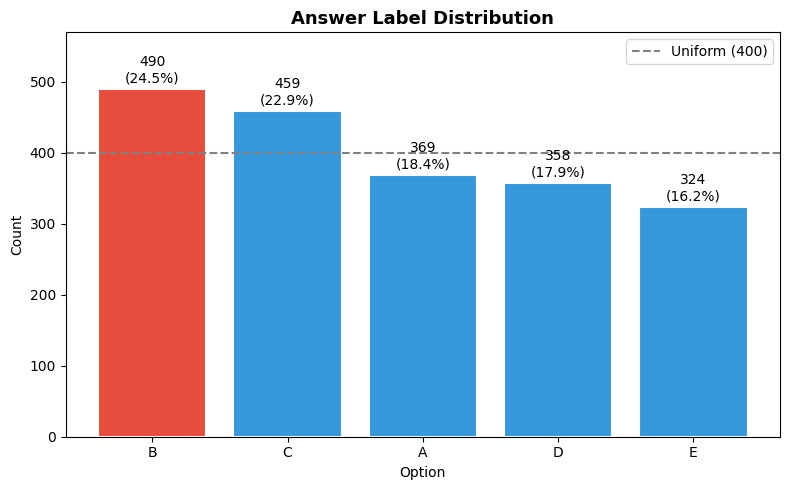

In [315]:
fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#e74c3c" if v == vc.max() else "#3498db" for v in vc.values]
bars   = ax.bar(vc.index, vc.values, color=colors, edgecolor="white", linewidth=1.5)
ax.axhline(y=len(train)/5, color="gray", linestyle="--",
           linewidth=1.5, label="Uniform (400)")
for bar, val in zip(bars, vc.values):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+5,
            f"{val}\n({val/len(train)*100:.1f}%)",
            ha="center", va="bottom", fontsize=10)
ax.set_title("Answer Label Distribution", fontweight="bold", fontsize=13)
ax.set_xlabel("Option"); ax.set_ylabel("Count")
ax.legend(); ax.set_ylim(0, 570)
plt.tight_layout()
plt.savefig("plot_01_answer_dist.png", dpi=150, bbox_inches="tight")
plt.show()

In [316]:
plen = train["prompt"].str.split().apply(len)
olen = pd.concat([train[c].str.split().apply(len) for c in Options], ignore_index=True)

print("Prompt word counts")
print(plen.describe().round(1))
print(f"95th pct : {plen.quantile(0.95):.0f}")
print(f"Max      : {plen.max()}")

print("\nOption word counts (A-E pooled)")
print(olen.describe().round(1))
print(f"95th pct : {olen.quantile(0.95):.0f}")
print(f"Max      : {olen.max()}")

p95 = int(plen.quantile(0.95))
o95 = int(olen.quantile(0.95))
print(f"\nPrompt 95th + Option 95th = {p95+o95} words")
print(f"Estimated BPE tokens      = {int((p95+o95)*1.3)}")
print(f"\nDecision preview: max_length=256 for Bi-LSTM, 512 for DeBERTa")
print(f"(Justified fully in preprocessing section after EDA)")

Prompt word counts
count    2000.0
mean       18.1
std         6.8
min         3.0
25%        14.0
50%        17.0
75%        22.0
max        51.0
Name: prompt, dtype: float64
95th pct : 31
Max      : 51

Option word counts (A-E pooled)
count    10000.0
mean        26.3
std         17.6
min          1.0
25%         13.0
50%         23.0
75%         36.0
max        118.0
dtype: float64
95th pct : 61
Max      : 118

Prompt 95th + Option 95th = 92 words
Estimated BPE tokens      = 119

Decision preview: max_length=256 for Bi-LSTM, 512 for DeBERTa
(Justified fully in preprocessing section after EDA)


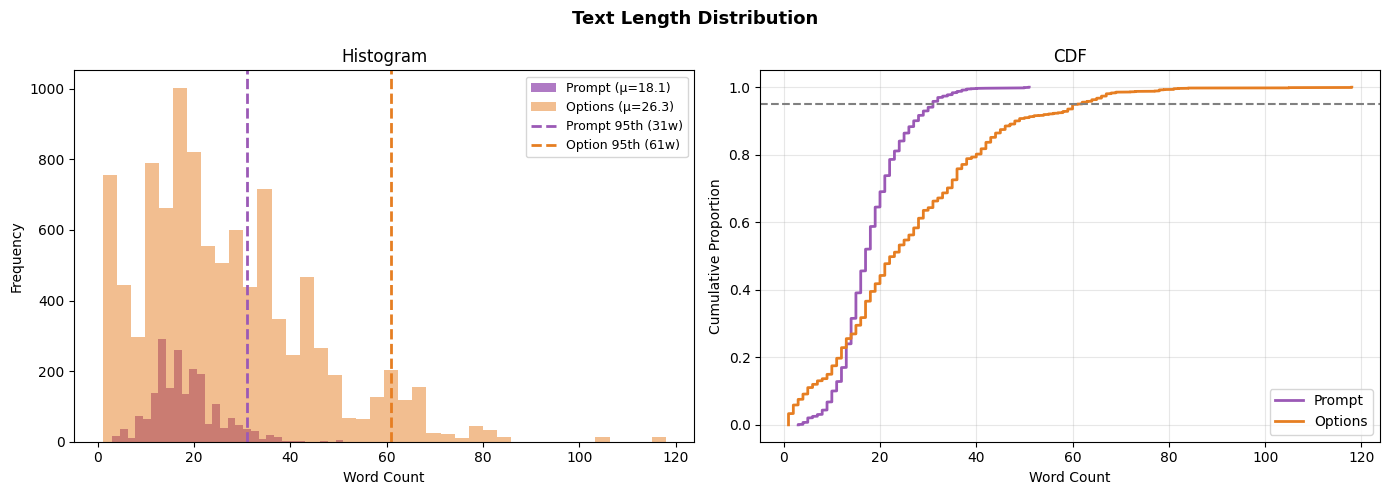

In [317]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Text Length Distribution", fontsize=13, fontweight="bold")

ax = axes[0]
ax.hist(plen, bins=30, alpha=0.8, color="#9b59b6",
        label=f"Prompt (μ={plen.mean():.1f})")
ax.hist(olen, bins=40, alpha=0.5, color="#e67e22",
        label=f"Options (μ={olen.mean():.1f})")
ax.axvline(x=p95, color="#9b59b6", linestyle="--",
           linewidth=2, label=f"Prompt 95th ({p95}w)")
ax.axvline(x=o95, color="#e67e22", linestyle="--",
           linewidth=2, label=f"Option 95th ({o95}w)")
ax.set_xlabel("Word Count"); ax.set_ylabel("Frequency")
ax.set_title("Histogram"); ax.legend(fontsize=9)

ax = axes[1]
ax.plot(np.sort(plen),
        np.linspace(0,1,len(plen)), color="#9b59b6",
        linewidth=2, label="Prompt")
ax.plot(np.sort(olen),
        np.linspace(0,1,len(olen)), color="#e67e22",
        linewidth=2, label="Options")
ax.axhline(y=0.95, color="gray", linestyle="--", linewidth=1.5)
ax.set_xlabel("Word Count"); ax.set_ylabel("Cumulative Proportion")
ax.set_title("CDF"); ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("plot_02_text_lengths.png", dpi=150, bbox_inches="tight")
plt.show()

In [318]:
print("First 25 raw prompts (repr, first 90 chars) ")
for i, p in enumerate(train["prompt"].head(25)):
    print(f"[{i:02d}] {repr(p[:90])}")

First 25 raw prompts (repr, first 90 chars) 
[00] "Pick the best possible answer: What is Martin Heidegger's view on the relationship between"
[01] 'What is accelerator-based light-ion fusion?'
[02] 'Determine the correct option: What is the term used in astrophysics to describe light-matt'
[03] "Select the most accurate option: What is Martin Heidegger's view on the relationship betwe"
[04] "Identify the correct statement: What is the concept of simultaneity in Einstein's book, Re"
[05] 'Identify the correct statement: What is the effect generated by a spinning superconductor?'
[06] 'Which of the following is correct? What is a "coffee ring" in physics? among the listed op'
[07] 'Select the most accurate option: What is the Liouville density? among the listed options.'
[08] 'Select the most accurate option: What are the constituents of cold dark matter?'
[09] 'Which of the following is correct? What is the relationship between the Wigner function an'
[10] 'Select the most accurate opt

In [319]:
def extract_prefix_v1(t):
    m = re.match(
        r"^(.*?)(What|Which|Who|How|Why|Determine|Identify|Select|Pick|Choose)",
        t
    )
    return m.group(1).strip() if m else ""

result_v1 = train["prompt"].apply(extract_prefix_v1)
print("Unique non-empty prefixes found (v1):",
      (result_v1 != "").sum())
print("\nAll values:")
print(result_v1.value_counts().to_string())
print("\n→ Returns empty for everything.")
print("Root cause: 'Pick' matched as the question word at position 0.")
print("group(1) = '' because nothing comes before it.")

Unique non-empty prefixes found (v1): 0

All values:
prompt
    2000

→ Returns empty for everything.
Root cause: 'Pick' matched as the question word at position 0.
group(1) = '' because nothing comes before it.


In [320]:
# Demonstrate the bug
example = "Pick the best possible answer: What is gravity?"
m = re.match(
    r"^(.*?)(What|Which|Who|How|Why|Determine|Identify|Select|Pick|Choose)",
    example
)
print(f"Input   : {repr(example)}")
print(f"group(1): {repr(m.group(1))}  ← empty: Pick consumed as question word")
print(f"group(2): {repr(m.group(2))}")

print("\nFix: instruction phrases ALWAYS end with ': ' before What/Which/Who.")
print("Pick/Select/Determine are NEVER actual question words — they are always")
print("followed by more instruction text and then ': '.\n")

def extract_prefix_v2(t):
    """
    Correct: prefix always ends with ': ' immediately before What/Which/Who.
    Special case: 'Which of the following is correct?' ends with '?'.
    """
    m = re.match(r"^([A-Z][^:]+:\s+)(What|Which|Who|How|Why)", t)
    if m:
        return m.group(1).strip()
    m2 = re.match(r"^(Which of the following is correct\?)\s+", t)
    if m2:
        return m2.group(1)
    return "NONE"

def extract_suffix_v2(t):
    """
    Suffix = text appearing AFTER the main question mark.
    Keep only if 1-8 words (longer = part of the question itself).
    """
    parts = t.split("?")
    if len(parts) > 1:
        suffix = parts[-1].strip().rstrip(".")
        if suffix and 1 <= len(suffix.split()) <= 8:
            return suffix
    return "NONE"

train["prefix_type"] = train["prompt"].apply(extract_prefix_v2)
train["suffix_type"]  = train["prompt"].apply(extract_suffix_v2)
test["prefix_type"]  = test["prompt"].apply(extract_prefix_v2)
test["suffix_type"]   = test["prompt"].apply(extract_suffix_v2)

print("All PREFIXES found")
print(train["prefix_type"].value_counts().to_string())
print("\nAll SUFFIXES found")
print(train["suffix_type"].value_counts().to_string())

combo = (train.groupby(["prefix_type","suffix_type"])
         .size().reset_index(name="count")
         .sort_values("count", ascending=False))
print(f"\nTotal prefix×suffix combinations: {len(combo)}")
print(f"Rows with NEITHER: "
      f"{((train['prefix_type']=='NONE')&(train['suffix_type']=='NONE')).sum()}")

Input   : 'Pick the best possible answer: What is gravity?'
group(1): ''  ← empty: Pick consumed as question word
group(2): 'Pick'

Fix: instruction phrases ALWAYS end with ': ' before What/Which/Who.
Pick/Select/Determine are NEVER actual question words — they are always
followed by more instruction text and then ': '.

All PREFIXES found
prefix_type
Pick the best possible answer:        316
Select the most accurate option:      309
Identify the correct statement:       302
Determine the correct option:         299
Choose the correct answer:            292
Which of the following is correct?    282
NONE                                  200

All SUFFIXES found
suffix_type
NONE                          538
among the listed options      388
based on the given context    376
from the following choices    369
carefully                     329

Total prefix×suffix combinations: 31
Rows with NEITHER: 200


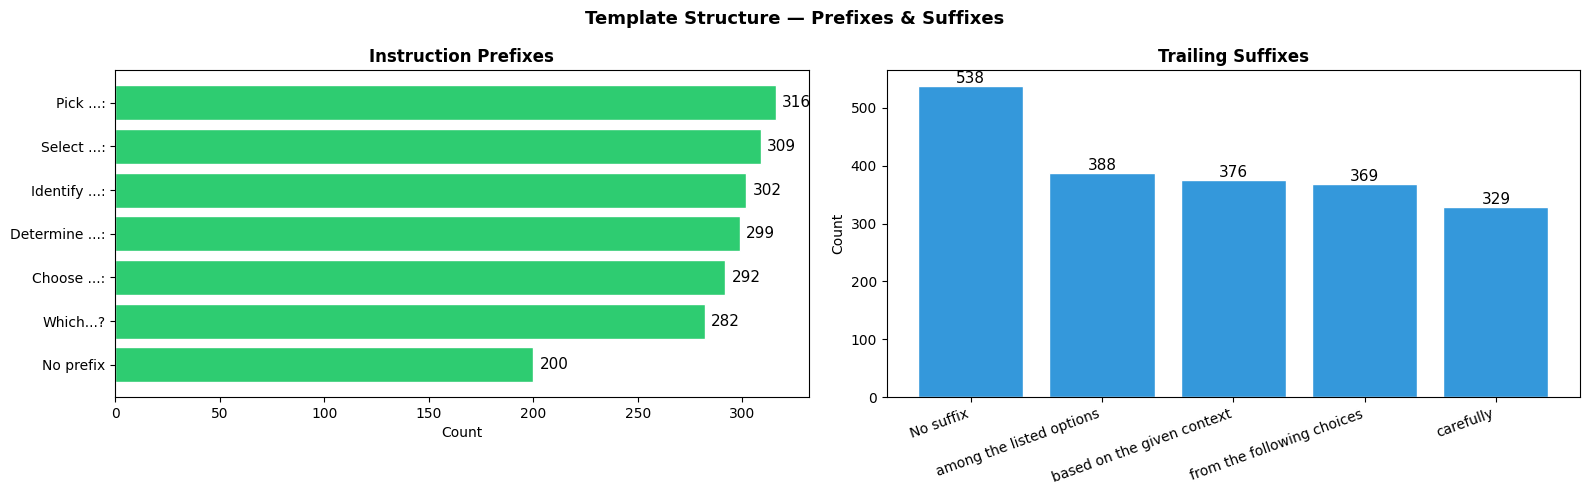

In [321]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle("Template Structure — Prefixes & Suffixes",
             fontsize=13, fontweight="bold")

ax = axes[0]
pvc = train["prefix_type"].value_counts()
short = [p.replace("Pick the best possible answer:","Pick ...:")
          .replace("Select the most accurate option:","Select ...:")
          .replace("Identify the correct statement:","Identify ...:")
          .replace("Determine the correct option:","Determine ...:")
          .replace("Choose the correct answer:","Choose ...:")
          .replace("Which of the following is correct?","Which...?")
          .replace("NONE","No prefix")
         for p in pvc.index]
ax.barh(short, pvc.values, color="#2ecc71", edgecolor="white")
for i,v in enumerate(pvc.values):
    ax.text(v+3, i, str(v), va="center", fontsize=11)
ax.set_xlabel("Count"); ax.invert_yaxis()
ax.set_title("Instruction Prefixes", fontweight="bold")

ax = axes[1]
svc = train["suffix_type"].value_counts()
short_s = [s.replace("NONE","No suffix") for s in svc.index]
ax.bar(short_s, svc.values, color="#3498db", edgecolor="white")
for i,v in enumerate(svc.values):
    ax.text(i, v+5, str(v), ha="center", fontsize=11)
ax.set_ylabel("Count")
ax.set_title("Trailing Suffixes", fontweight="bold")
plt.xticks(rotation=20, ha="right")

plt.tight_layout()
plt.savefig("plot_03_prefix_suffix.png", dpi=150, bbox_inches="tight")
plt.show()

In [322]:
PREFIX_PATTERNS = [
    r"^pick the best possible answer:?\s*",
    r"^select the most accurate option:?\s*",
    r"^determine the correct option:?\s*",
    r"^identify the correct statement:?\s*",
    r"^which of the following is correct\??\s*",
    r"^choose the correct answer:?\s*",
]
SUFFIX_PATTERNS = [
    r"\s*carefully\.?$",
    r"\s*based on the given context\.?$",
    r"\s*from the following choices\.?$",
    r"\s*among the listed options\.?$",
]

def strip_wrapper(t):
    t = t.lower().strip()
    for p in PREFIX_PATTERNS: t = re.sub(p, "", t)
    for p in SUFFIX_PATTERNS: t = re.sub(p, "", t)
    t = re.sub(r"[^a-z0-9\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

# Verify on examples
for ex in [
    "Pick the best possible answer: What is gravity? among the listed options.",
    "Determine the correct option: What is gravity? carefully.",
    "What is gravity?",
]:
    print(f"IN : {repr(ex[:80])}")
    print(f"OUT: {repr(strip_wrapper(ex))}\n")

IN : 'Pick the best possible answer: What is gravity? among the listed options.'
OUT: 'what is gravity'

IN : 'Determine the correct option: What is gravity? carefully.'
OUT: 'what is gravity'

IN : 'What is gravity?'
OUT: 'what is gravity'



In [323]:
train["core"]  = train["prompt"].apply(strip_wrapper)
test["core"]   = test["prompt"].apply(strip_wrapper)
train["group"] = train["core"].astype("category").cat.codes

dup = train["core"].value_counts()

print(f"Total train rows          : {len(train)}")
print(f"Unique core questions     : {dup.shape[0]}")
print(f"Avg copies per question   : {len(train)/dup.shape[0]:.1f}×")
print(f"Clusters with >1 copy     : {(dup>1).sum()}")
print(f"Singleton questions       : {(dup==1).sum()}")

consistent = train.groupby("core")["answer"].apply(lambda s: s.nunique()==1)
print(f"\nClusters with 100% consistent answer: "
      f"{consistent.sum()}/{len(consistent)} ({consistent.mean():.1%})")

print("\nTop 10 duplicate clusters:")
print(dup.head(10).to_string())

Total train rows          : 2000
Unique core questions     : 252
Avg copies per question   : 7.9×
Clusters with >1 copy     : 222
Singleton questions       : 30

Clusters with 100% consistent answer: 252/252 (100.0%)

Top 10 duplicate clusters:
core
what is the definition of an improper rotation                                                                                                                                21
what is the significance of the high degree of fatty acyl disorder in the thylakoid membranes of plants                                                                       20
what was the aim of the gravity probe b gp b mission                                                                                                                          18
what is the gravitomagnetic interaction                                                                                                                                       18
which of the following statements accurate

In [324]:
dup_test = test["core"].value_counts()
overlap  = set(train["core"]) & set(test["core"])

print(f"Unique core Qs in test          : {dup_test.shape[0]}")
print(f"Already in train (exact match)  : {len(overlap)} "
      f"({len(overlap)/dup_test.shape[0]:.1%})")
print(f"Test ROWS with retrieval match  : "
      f"{test['core'].isin(set(train['core'])).sum()} / {len(test)}")
print(f"Duplicate clusters inside test  : {(dup_test>1).sum()}")

print("\nFirst 5 overlapping core questions:")
for q in list(overlap)[:5]:
    ans = train.loc[train["core"]==q, "answer"].iloc[0]
    print(f"  [{ans}] {q[:80]}")

Unique core Qs in test          : 228
Already in train (exact match)  : 228 (100.0%)
Test ROWS with retrieval match  : 500 / 500
Duplicate clusters inside test  : 153

First 5 overlapping core questions:
  [B] what is the ramsauer townsend effect
  [B] what is the significance of the discovery of the crab pulsar
  [A] what did newton adopt after his correspondence with hooke in 1679 1680
  [C] what is the main sequence in astronomy
  [A] what is the significance of baryon acoustic oscillations baos in the study of th


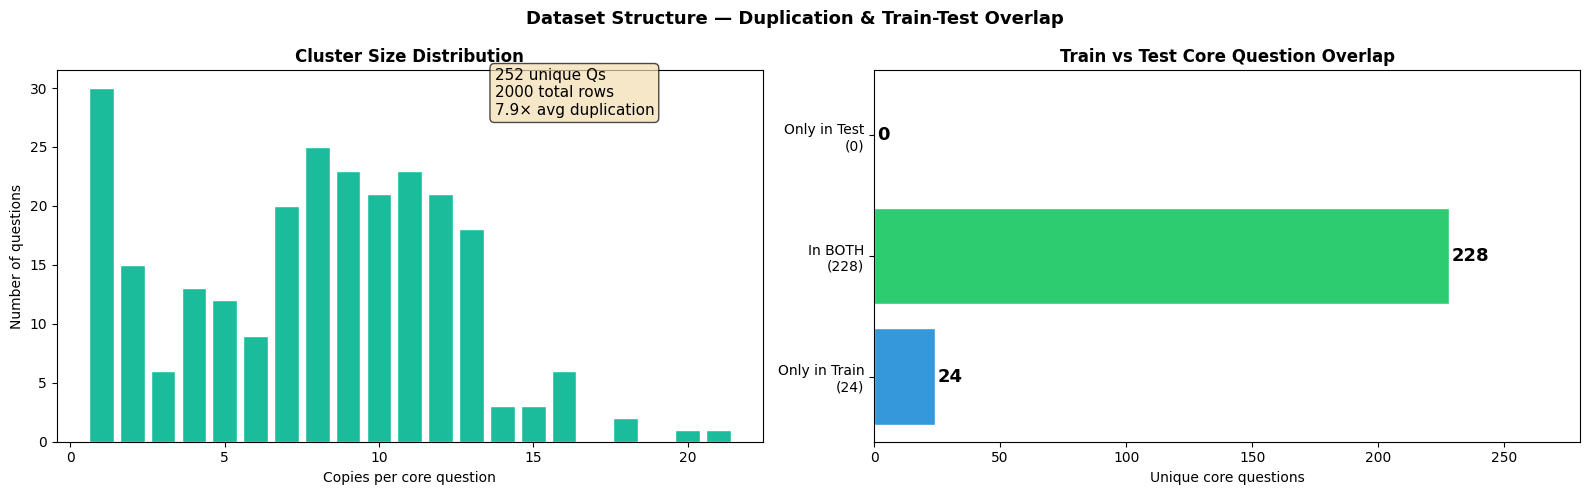

In [325]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle("Dataset Structure — Duplication & Train-Test Overlap",
             fontsize=13, fontweight="bold")

ax = axes[0]
cs = dup.value_counts().sort_index()
ax.bar(cs.index, cs.values, color="#1abc9c", edgecolor="white")
ax.set_xlabel("Copies per core question")
ax.set_ylabel("Number of questions")
ax.set_title("Cluster Size Distribution", fontweight="bold")
ax.text(0.62, 0.88,
        f"252 unique Qs\n2000 total rows\n7.9× avg duplication",
        transform=ax.transAxes, fontsize=11,
        bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.7))

ax = axes[1]
only_train = len(set(train["core"])) - len(overlap)
only_test  = len(set(test["core"]))  - len(overlap)
labels_v   = [f"Only in Train\n({only_train})",
              f"In BOTH\n({len(overlap)})",
              f"Only in Test\n({only_test})"]
vals_v     = [only_train, len(overlap), only_test]
colors_v   = ["#3498db", "#2ecc71", "#e74c3c"]
bars_v     = ax.barh(labels_v, vals_v, color=colors_v, edgecolor="white")
for bar, val in zip(bars_v, vals_v):
    ax.text(bar.get_width()+1, bar.get_y()+bar.get_height()/2,
            str(val), va="center", fontsize=13, fontweight="bold")
ax.set_xlabel("Unique core questions")
ax.set_title("Train vs Test Core Question Overlap", fontweight="bold")
ax.set_xlim(0, 280)

plt.tight_layout()
plt.savefig("plot_04_cluster_overlap.png", dpi=150, bbox_inches="tight")
plt.show()

In [326]:
most_dup = train["core"].value_counts().index[0]
dup_rows = train[train["core"]==most_dup]
print(f"Most duplicated question: '{most_dup[:70]}'")
print(f"Appears {len(dup_rows)} times | Answer always: "
      f"{dup_rows['answer'].unique()}")

np.random.seed(42)
rand_val = np.random.choice(dup_rows.index,
                             size=max(1,len(dup_rows)//5), replace=False)
print(f"\nRandom 80/20 split:")
print(f"  Train: {len(dup_rows)-len(rand_val)} copies")
print(f"  Val  : {len(rand_val)} copies  ← LEAK")
print("  Model memorizes train rows, 'solves' identical val rows.")
print("  Score is inflated — model learned nothing real.\n")

gkf    = GroupKFold(n_splits=5)
splits = list(gkf.split(train, groups=train["group"]))

print("GroupKFold: ALL copies of a question go to ONE fold side.")
print(f"\n{'Fold':<6} {'Train rows':>12} {'Val rows':>10} "
      f"{'Train unique Qs':>17} {'Val unique Qs':>15}")
print("-"*65)
for i, (tr_idx, va_idx) in enumerate(splits):
    print(f"{i:<6} {len(tr_idx):>12} {len(va_idx):>10} "
          f"{train.iloc[tr_idx]['group'].nunique():>17} "
          f"{train.iloc[va_idx]['group'].nunique():>15}")

Most duplicated question: 'what is the definition of an improper rotation'
Appears 21 times | Answer always: ['B']

Random 80/20 split:
  Train: 17 copies
  Val  : 4 copies  ← LEAK
  Model memorizes train rows, 'solves' identical val rows.
  Score is inflated — model learned nothing real.

GroupKFold: ALL copies of a question go to ONE fold side.

Fold     Train rows   Val rows   Train unique Qs   Val unique Qs
-----------------------------------------------------------------
0              1600        400               202              50
1              1600        400               202              50
2              1600        400               202              50
3              1600        400               201              51
4              1600        400               201              51


In [327]:
def jaccard(a, b):
    return len(a&b)/len(a|b) if (a|b) else 0.0

def tok_set(t):
    return set(re.findall(r"[a-z0-9]+", t.lower()))

print("Computing Jaccard overlap (takes ~30s)...")
avg_overlap_list, margin_list = [], []

for _, row in train.iterrows():
    opt_sets = {c: tok_set(row[c]) for c in Options}
    pairs    = list(combinations(Options, 2))
    avg_overlap_list.append(
        np.mean([jaccard(opt_sets[a], opt_sets[b]) for a,b in pairs])
    )
    pset    = tok_set(row["prompt"])
    correct = row["answer"]
    c_ov    = jaccard(pset, opt_sets[correct])
    i_ov    = np.mean([jaccard(pset, opt_sets[c])
                       for c in Options if c != correct])
    margin_list.append(c_ov - i_ov)

train["option_overlap"] = avg_overlap_list
train["signal_margin"]  = margin_list
avg_ov = pd.Series(avg_overlap_list)
margin = pd.Series(margin_list)

print("Avg pairwise Jaccard between 5 options")
print(avg_ov.describe().round(3))
print(f"\nQuestions where options >50% similar: {(avg_ov>0.5).mean():.1%}")
print("\n── Signal margin (correct – avg_wrong similarity to prompt) ──")
print(margin.describe().round(4))
print(f"\nFraction where correct NOT most similar to prompt: "
      f"{(margin<=0).mean():.1%}")

Computing Jaccard overlap (takes ~30s)...
Avg pairwise Jaccard between 5 options
count    2000.000
mean        0.516
std         0.267
min         0.000
25%         0.300
50%         0.535
75%         0.764
max         0.940
dtype: float64

Questions where options >50% similar: 53.1%

── Signal margin (correct – avg_wrong similarity to prompt) ──
count    2000.0000
mean       -0.0117
std         0.0352
min        -0.1612
25%        -0.0247
50%        -0.0040
75%         0.0010
max         0.1597
dtype: float64

Fraction where correct NOT most similar to prompt: 73.7%


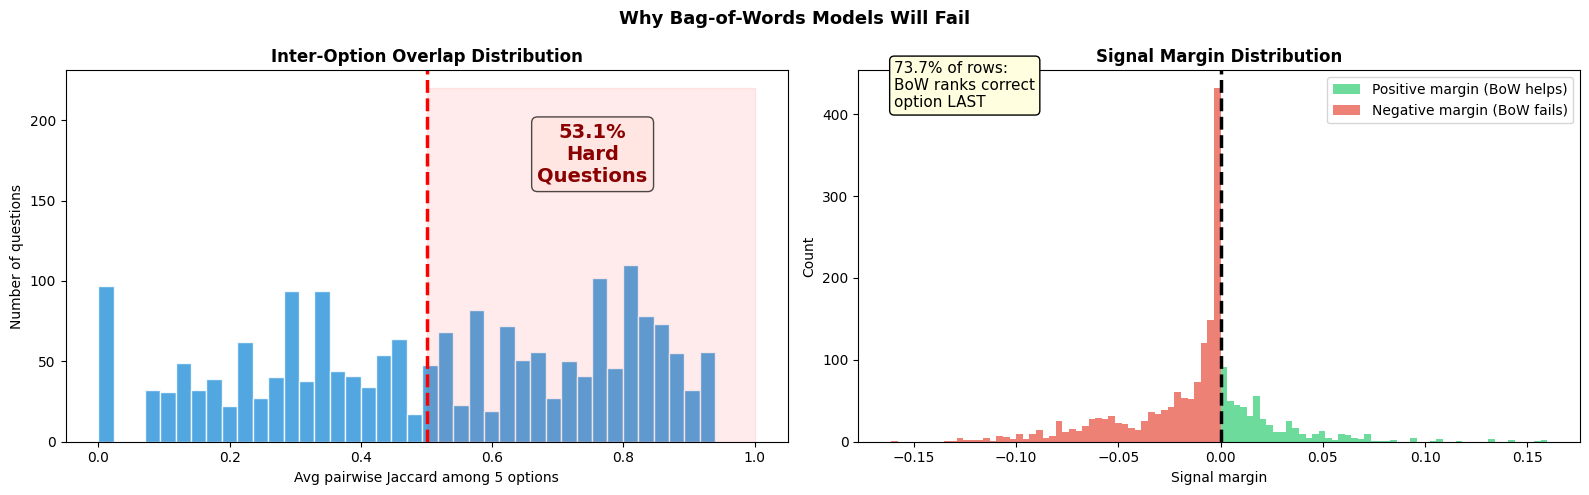

In [328]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle("Why Bag-of-Words Models Will Fail",
             fontsize=13, fontweight="bold")

ax = axes[0]
ax.hist(avg_ov, bins=40, color="#3498db", edgecolor="white", alpha=0.85)
ax.axvline(x=0.5, color="red", linestyle="--", linewidth=2.5)
ax.fill_betweenx([0,220], 0.5, 1.0, alpha=0.08, color="red")
ax.text(0.73, 0.70, f"{(avg_ov>0.5).mean():.1%}\nHard\nQuestions",
        transform=ax.transAxes, fontsize=14, color="darkred",
        fontweight="bold", ha="center",
        bbox=dict(boxstyle="round", facecolor="mistyrose", alpha=0.7))
ax.set_xlabel("Avg pairwise Jaccard among 5 options")
ax.set_ylabel("Number of questions")
ax.set_title("Inter-Option Overlap Distribution", fontweight="bold")

ax = axes[1]
neg_mask = margin <= 0
ax.hist(margin[~neg_mask], bins=50, color="#2ecc71",
        alpha=0.7, label="Positive margin (BoW helps)")
ax.hist(margin[neg_mask],  bins=50, color="#e74c3c",
        alpha=0.7, label="Negative margin (BoW fails)")
ax.axvline(x=0, color="black", linewidth=2.5, linestyle="--")
ax.text(0.05, 0.90, f"{(margin<=0).mean():.1%} of rows:\nBoW ranks correct\noption LAST",
        transform=ax.transAxes, fontsize=11,
        bbox=dict(boxstyle="round", facecolor="lightyellow"))
ax.set_xlabel("Signal margin"); ax.set_ylabel("Count")
ax.set_title("Signal Margin Distribution", fontweight="bold")
ax.legend()

plt.tight_layout()
plt.savefig("plot_05_overlap_margin.png", dpi=150, bbox_inches="tight")
plt.show()

In [329]:
def answer_length_rank(row):
    lens = sorted([(c, len(row[c].split())) for c in Options],
                  key=lambda x: -x[1])
    return {c: r+1 for r,(c,_) in enumerate(lens)}[row["answer"]]

train["ans_len_rank"] = train.apply(answer_length_rank, axis=1)

observed = train["ans_len_rank"].value_counts().sort_index().values
expected = np.full(5, len(train)/5)
chi2, p_val, _, _ = chi2_contingency([observed, expected.astype(int)])

print("── Correct answer by length rank ──")
print("(Rank 1 = longest option, Rank 5 = shortest)")
print()
rank_pct = train["ans_len_rank"].value_counts(normalize=True).sort_index()
print(rank_pct.round(4).to_string())
print(f"\nRank 1 (longest): {rank_pct.iloc[0]:.1%}  vs  20.0% random")
print(f"Chi-square: χ²={chi2:.2f}, p={p_val:.2e}")
print(f"Statistically significant: {p_val < 0.001}")

── Correct answer by length rank ──
(Rank 1 = longest option, Rank 5 = shortest)

ans_len_rank
1    0.3495
2    0.2555
3    0.1590
4    0.0990
5    0.1370

Rank 1 (longest): 34.9%  vs  20.0% random
Chi-square: χ²=196.03, p=2.69e-41
Statistically significant: True


In [330]:
print("═"*70)
print("HARDEST QUESTION (highest option overlap)")
print("═"*70)
hardest = train.loc[train["option_overlap"].idxmax()]
print(f"Prompt  : {hardest['prompt']}")
print(f"Overlap : {hardest['option_overlap']:.3f}")
print(f"Correct : {hardest['answer']}\n")
for c in Options:
    m = "  ← CORRECT" if hardest["answer"]==c else ""
    print(f"  {c}: {str(hardest[c])[:115]}{m}")

print("\n" + "═"*70)
print("EASIEST QUESTION (zero option overlap)")
print("═"*70)
easiest = train.loc[train["option_overlap"].idxmin()]
print(f"Prompt  : {easiest['prompt']}")
print(f"Overlap : {easiest['option_overlap']:.3f}")
print(f"Correct : {easiest['answer']}\n")
for c in Options:
    m = "  ← CORRECT" if easiest["answer"]==c else ""
    print(f"  {c}: {str(easiest[c])[:80]}{m}")

══════════════════════════════════════════════════════════════════════
HARDEST QUESTION (highest option overlap)
══════════════════════════════════════════════════════════════════════
Prompt  : Which of the following statements accurately describes the characteristics of gravitational waves?
Overlap : 0.940
Correct : C

  A: Gravitational waves have an amplitude denoted by h, which represents the size of the wave. The amplitude varies wit
  B: Gravitational waves have an amplitude denoted by λ, which represents the distance between points of maximum stretch
  C: Gravitational waves have an amplitude denoted by h, which represents the size of the wave. The amplitude varies wit  ← CORRECT
  D: Gravitational waves have an amplitude denoted by f, which represents the frequency of the wave's oscillation. The a
  E: Gravitational waves have an amplitude denoted by f, which represents the frequency of the wave's oscillation. The a

═════════════════════════════════════════════════════════════

In [331]:
def get_qword(t):
    t2 = re.sub(r"^[A-Z][^:]+:\s*", "", t)
    m  = re.match(r"^(What|Which|Who|How|Why)\b", t2, re.I)
    return m.group(1).lower() if m else "other"

DOMAIN_KW = {
    "Physics/Astronomy"  : ["quantum","photon","relativity","force","energy",
                             "wave","spin","field","entropy","gravity",
                             "superconductor","boson","fermion","hamiltonian",
                             "star","galaxy","pulsar","redshift","supernova",
                             "universe","dark matter","black hole","gravitational"],
    "Chemistry/Materials": ["molecule","ion","bond","acid","reaction","enzyme",
                             "protein","membrane","polymer","crystal","alloy",
                             "metal","orbital","catalyst","ferromagnetic",
                             "memristor","piezoelectric"],
    "Biology"            : ["cell","gene","organism","evolution","mammal",
                             "plant","bacteria","virus","dna","rna",
                             "chromosome","mammary"],
    "Math/CS"            : ["function","theorem","matrix","vector","topology",
                             "algebra","group","manifold","integral","algorithm"],
}

def classify_domain(t):
    t = t.lower()
    scores = {d: sum(1 for k in kws if k in t) for d,kws in DOMAIN_KW.items()}
    best = max(scores, key=scores.get)
    return best if scores[best]>0 else "General/Other"

train["q_word"] = train["prompt"].apply(get_qword)
train["domain"] = (train["prompt"]+" "+train["A"]+" "+train["B"]).apply(classify_domain)

print("── Question word distribution ──")
print(train["q_word"].value_counts().to_string())
print("\n── Domain distribution ──")
print(train["domain"].value_counts().to_string())

── Question word distribution ──
q_word
what     1534
which     383
who        55
how        26
other       2

── Domain distribution ──
domain
Chemistry/Materials    943
Physics/Astronomy      883
General/Other          106
Biology                 42
Math/CS                 26


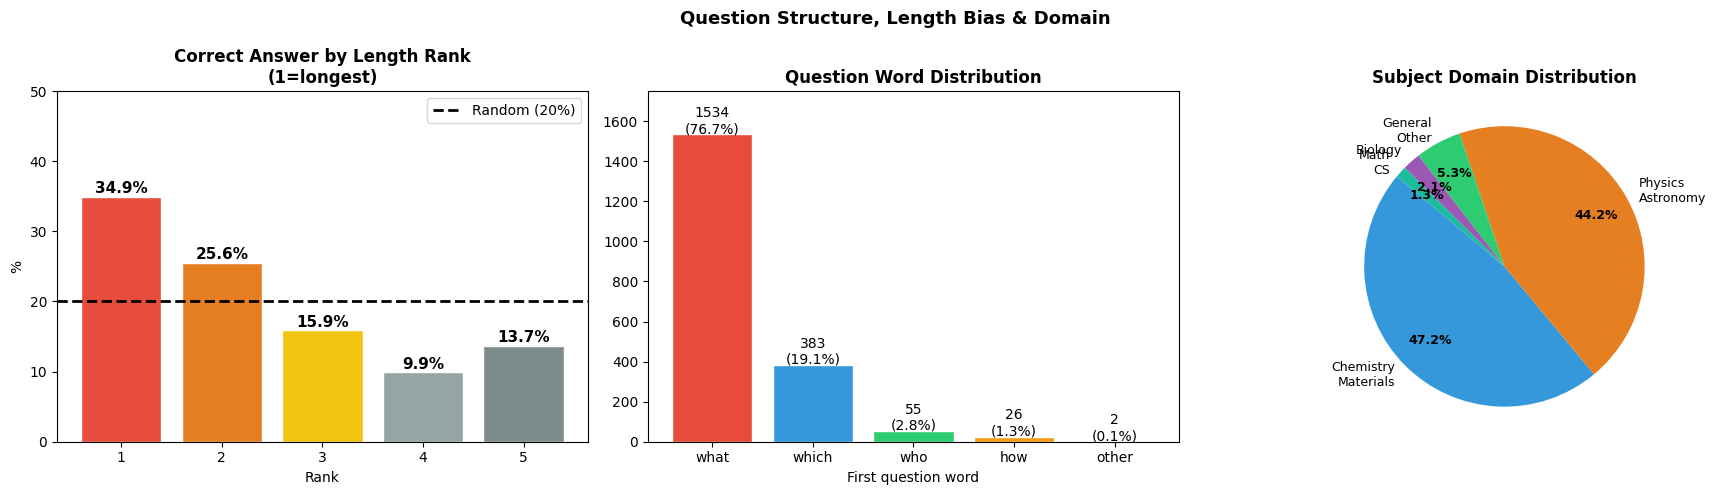

In [332]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Question Structure, Length Bias & Domain",
             fontsize=13, fontweight="bold")

ax = axes[0]
rank_counts = train["ans_len_rank"].value_counts().sort_index()
rank_pct2   = rank_counts/len(train)*100
bars = ax.bar(rank_counts.index, rank_pct2.values,
              color=["#e74c3c","#e67e22","#f1c40f","#95a5a6","#7f8c8d"],
              edgecolor="white")
ax.axhline(y=20, color="black", linestyle="--",
           linewidth=2, label="Random (20%)")
for bar, val in zip(bars, rank_pct2.values):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            f"{val:.1f}%", ha="center", fontsize=11, fontweight="bold")
ax.set_title("Correct Answer by Length Rank\n(1=longest)", fontweight="bold")
ax.set_xlabel("Rank"); ax.set_ylabel("%"); ax.legend(); ax.set_ylim(0,50)

ax = axes[1]
qw = train["q_word"].value_counts()
colors_q = ["#e74c3c","#3498db","#2ecc71","#f39c12","#9b59b6"]
bars2 = ax.bar(qw.index, qw.values,
               color=colors_q[:len(qw)], edgecolor="white")
for bar, val in zip(bars2, qw.values):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+5,
            f"{val}\n({val/len(train)*100:.1f}%)",
            ha="center", fontsize=10)
ax.set_title("Question Word Distribution", fontweight="bold")
ax.set_xlabel("First question word"); ax.set_ylim(0,1750)

ax = axes[2]
dc = train["domain"].value_counts()
short_labels = [d.replace(" / ","\n").replace("/","\n") for d in dc.index]
colors_d = ["#3498db","#e67e22","#2ecc71","#9b59b6","#1abc9c"]
wedges, texts, autotexts = ax.pie(
    dc.values, labels=short_labels, autopct="%1.1f%%",
    colors=colors_d[:len(dc)], startangle=140, pctdistance=0.75,
    textprops={"fontsize":9}
)
for at in autotexts: at.set_fontweight("bold")
ax.set_title("Subject Domain Distribution", fontweight="bold")

plt.tight_layout()
plt.savefig("plot_06_structure_domain.png", dpi=150, bbox_inches="tight")
plt.show()

In [333]:
print("═"*65)
print("EDA COMPLETE — KEY NUMBERS")
print("═"*65)
print(f"  Naive mAP@3 floor          : {naive_map3:.4f}")
print(f"  Unique core questions       : {train['core'].nunique()} / 2000 rows")
print(f"  Avg duplication factor      : {2000/train['core'].nunique():.1f}×")
print(f"  Answer consistency (100%)   : {consistent.mean():.1%}")
print(f"  Test rows matched in train  : {test['core'].isin(set(train['core'])).sum()} / {len(test)}")
print(f"  Prefix types found          : 6 instruction + 1 bare (NONE)")
print(f"  Suffix types found          : 4 trailing + many bare")
print(f"  Prefix×Suffix combos        : 31")
print(f"  Options >50% overlap        : {(avg_ov>0.5).mean():.1%}")
print(f"  Correct NOT most similar    : {(margin<=0).mean():.1%}")
print(f"  Correct = longest option    : {(train['ans_len_rank']==1).mean():.1%}")
print(f"  Length bias p-value         : {p_val:.2e} (significant)")
print(f"  Domain: Physics/Astronomy   : {(train['domain']=='Physics/Astronomy').mean():.1%}")
print(f"  Domain: Chemistry/Materials : {(train['domain']=='Chemistry/Materials').mean():.1%}")
print("═"*65)

═════════════════════════════════════════════════════════════════
EDA COMPLETE — KEY NUMBERS
═════════════════════════════════════════════════════════════════
  Naive mAP@3 floor          : 0.4213
  Unique core questions       : 252 / 2000 rows
  Avg duplication factor      : 7.9×
  Answer consistency (100%)   : 100.0%
  Test rows matched in train  : 500 / 500
  Prefix types found          : 6 instruction + 1 bare (NONE)
  Suffix types found          : 4 trailing + many bare
  Prefix×Suffix combos        : 31
  Options >50% overlap        : 53.1%
  Correct NOT most similar    : 73.7%
  Correct = longest option    : 34.9%
  Length bias p-value         : 2.69e-41 (significant)
  Domain: Physics/Astronomy   : 44.1%
  Domain: Chemistry/Materials : 47.1%
═════════════════════════════════════════════════════════════════


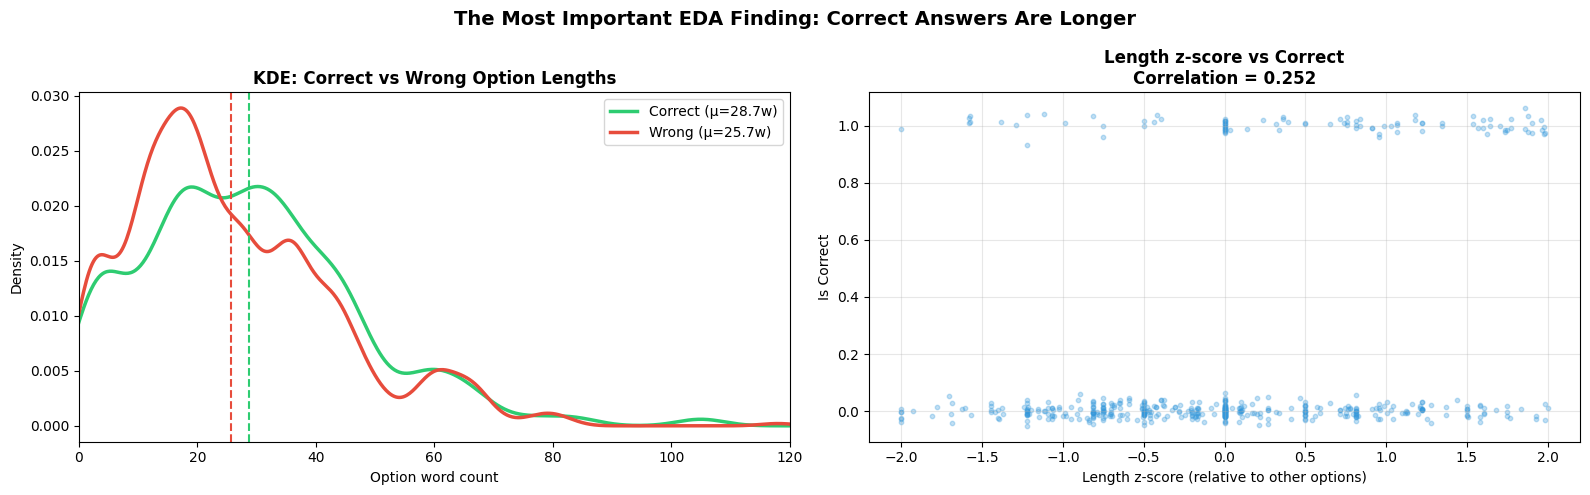

T-test: correct(28.7w) vs wrong(25.7w)
t=6.77, p=1.39e-11
Statistically significant: True
Length z-score correlation with correctness: 0.252

This is a real, systematic artifact — not noise.
A model that learns to pick the longest option will score well.
We build that model next (Random Forest on engineered features).


In [334]:
# ── KDE: correct vs wrong option lengths ─────────────────────────────────
import scipy.stats as stats

for c in Options:
    train[f"{c}_len"] = train[c].str.split().apply(len)

correct_lens   = []
incorrect_lens = []
for _, row in train.iterrows():
    for c in Options:
        (correct_lens if row["answer"]==c else incorrect_lens).append(row[f"{c}_len"])

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle("The Most Important EDA Finding: Correct Answers Are Longer",
             fontsize=14, fontweight="bold")

ax = axes[0]
pd.Series(correct_lens).plot.kde(ax=ax, color="#2ecc71", linewidth=2.5,
                                   label=f"Correct (μ={np.mean(correct_lens):.1f}w)")
pd.Series(incorrect_lens).plot.kde(ax=ax, color="#e74c3c", linewidth=2.5,
                                     label=f"Wrong (μ={np.mean(incorrect_lens):.1f}w)")
ax.axvline(np.mean(correct_lens), color="#2ecc71", linestyle="--", linewidth=1.5)
ax.axvline(np.mean(incorrect_lens), color="#e74c3c", linestyle="--", linewidth=1.5)
ax.set_xlabel("Option word count"); ax.set_ylabel("Density")
ax.set_title("KDE: Correct vs Wrong Option Lengths", fontweight="bold")
ax.legend(); ax.set_xlim(0, 120)

ax = axes[1]
long_form = []
for _, row in train.iterrows():
    lens  = np.array([row[f"{c}_len"] for c in Options])
    mu    = lens.mean(); sigma = lens.std() if lens.std()>0 else 1
    for c in Options:
        z = (row[f"{c}_len"] - mu) / sigma
        long_form.append({"is_correct": row["answer"]==c, "len_zscore": z})
lf = pd.DataFrame(long_form)
corr = lf["len_zscore"].corr(lf["is_correct"].astype(float))
ax.scatter(lf.sample(500, random_state=42)["len_zscore"],
           lf.sample(500, random_state=42)["is_correct"].astype(float) +
           np.random.normal(0, 0.02, 500),
           alpha=0.3, color="#3498db", s=10)
ax.set_xlabel("Length z-score (relative to other options)")
ax.set_ylabel("Is Correct")
ax.set_title(f"Length z-score vs Correct\nCorrelation = {corr:.3f}", fontweight="bold")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("plot_eda_length_kde.png", dpi=150, bbox_inches="tight")
plt.show()

t_stat, p_val_length = stats.ttest_ind(correct_lens, incorrect_lens)
print(f"T-test: correct({np.mean(correct_lens):.1f}w) vs wrong({np.mean(incorrect_lens):.1f}w)")
print(f"t={t_stat:.2f}, p={p_val_length:.2e}")
print(f"Statistically significant: {p_val_length < 0.001}")
print(f"Length z-score correlation with correctness: {corr:.3f}")
print(f"\nThis is a real, systematic artifact — not noise.")
print(f"A model that learns to pick the longest option will score well.")
print(f"We build that model next (Random Forest on engineered features).")

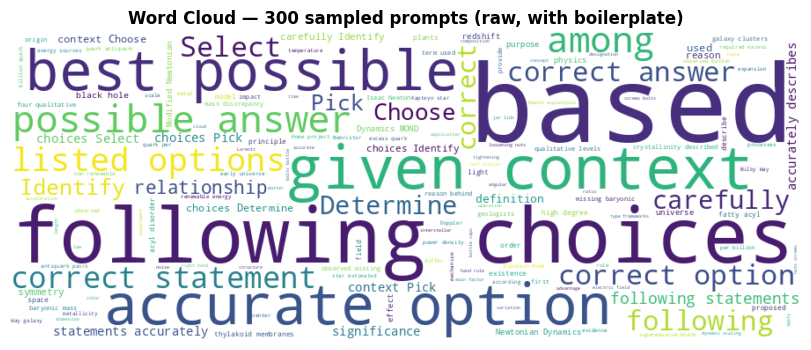

Raw word cloud shows boilerplate ('correct','option','following') dominates.
This is WHY the KMeans clustering v1 will fail — next cell shows this.


In [335]:
try:
    from wordcloud import WordCloud
    text = " ".join(train["prompt"].sample(300, random_state=42))
    wc = WordCloud(width=900, height=350, background_color="white",
                   colormap="viridis", max_words=150).generate(text)
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.imshow(wc, interpolation="bilinear")
    ax.axis("off")
    ax.set_title("Word Cloud — 300 sampled prompts (raw, with boilerplate)",
                 fontweight="bold")
    plt.savefig("plot_eda_wordcloud_raw.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Raw word cloud shows boilerplate ('correct','option','following') dominates.")
    print("This is WHY the KMeans clustering v1 will fail — next cell shows this.")
except ImportError:
    print("wordcloud not installed. Run: !pip install wordcloud -q")

In [336]:
from sklearn.cluster import KMeans

tfidf_raw = TfidfVectorizer(stop_words="english", max_features=500, min_df=3)
vecs_raw  = tfidf_raw.fit_transform(train["prompt"])
km_raw    = KMeans(n_clusters=6, random_state=SEED, n_init=10).fit(vecs_raw)
train["cluster_v1"] = km_raw.labels_

print("── KMeans v1 top terms per cluster (raw prompts) ──")
terms = tfidf_raw.get_feature_names_out()
for cl in range(6):
    center = km_raw.cluster_centers_[cl]
    top    = [terms[i] for i in center.argsort()[-8:][::-1]]
    print(f"  Cluster {cl}: {top}")

print("\nResult: every cluster's top terms are boilerplate instruction words.")
print("'correct', 'option', 'following', 'choose', 'select' dominate.")
print("The instructional wrapper is hiding the actual topic content.")
print("Fix: strip boilerplate before clustering. Next cell.")

── KMeans v1 top terms per cluster (raw prompts) ──
  Cluster 0: ['determine', 'option', 'correct', 'listed', 'options', 'based', 'carefully', 'given']
  Cluster 1: ['select', 'accurate', 'option', 'carefully', 'given', 'context', 'options', 'listed']
  Cluster 2: ['following', 'correct', 'carefully', 'choices', 'options', 'listed', 'based', 'used']
  Cluster 3: ['best', 'pick', 'possible', 'answer', 'listed', 'options', 'based', 'choices']
  Cluster 4: ['statement', 'identify', 'correct', 'based', 'given', 'context', 'options', 'listed']
  Cluster 5: ['choose', 'answer', 'correct', 'based', 'given', 'context', 'choices', 'options']

Result: every cluster's top terms are boilerplate instruction words.
'correct', 'option', 'following', 'choose', 'select' dominate.
The instructional wrapper is hiding the actual topic content.
Fix: strip boilerplate before clustering. Next cell.


In [337]:
BOILERPLATE = {
    "following","correct","option","options","choose","select","identify",
    "statement","based","given","context","listed","carefully","accurate",
    "possible","answer","answers","best","pick","determine","which","what",
    "how","why","who","when","where","is","are","the","a","an","of","in",
    "to","and","or","not","its","it","this","that","these","those",
}

def strip_boilerplate(t):
    tokens = re.findall(r"[a-z]+", t.lower())
    return " ".join([w for w in tokens if w not in BOILERPLATE and len(w)>2])

train["prompt_clean_cluster"] = train["prompt"].apply(strip_boilerplate)

tfidf_clean = TfidfVectorizer(max_features=1000, min_df=2)
vecs_clean  = tfidf_clean.fit_transform(train["prompt_clean_cluster"])
km_clean    = KMeans(n_clusters=6, random_state=SEED, n_init=10).fit(vecs_clean)
train["topic_cluster"] = km_clean.labels_

print("── KMeans v2 top terms per cluster (boilerplate stripped) ──")
terms2 = tfidf_clean.get_feature_names_out()
cluster_labels = {}
for cl in range(6):
    center = km_clean.cluster_centers_[cl]
    top    = [terms2[i] for i in center.argsort()[-8:][::-1]]
    cluster_labels[cl] = top[0]
    print(f"  Cluster {cl} (n={( train['topic_cluster']==cl).sum()}): {top}")

print(f"\nNow we see real topics: quantum mechanics, planetary dynamics,")
print(f"biological systems, mathematical structures etc.")
print(f"The dataset is overwhelmingly physics/science — confirms our domain plot.")

# Check length artifact holds across all clusters
print("\n── Does the length artifact hold across ALL clusters? ──")
for cl in range(6):
    sub    = train[train["topic_cluster"]==cl]
    c_lens = []
    w_lens = []
    for _,row in sub.iterrows():
        for c in Options:
            (c_lens if row["answer"]==c else w_lens).append(row[f"{c}_len"])
    t,p = stats.ttest_ind(c_lens, w_lens)
    print(f"  Cluster {cl} (n={len(sub)}): "
          f"correct μ={np.mean(c_lens):.1f}w, wrong μ={np.mean(w_lens):.1f}w, "
          f"p={p:.2e} {'✓ significant' if p<0.05 else '✗ not significant'}")
print("\nArtifact holds across every cluster → property of generation, not topic.")

── KMeans v2 top terms per cluster (boilerplate stripped) ──
  Cluster 0 (n=127): ['significance', 'redshift', 'distance', 'universe', 'high', 'thylakoid', 'disorder', 'plants']
  Cluster 1 (n=900): ['for', 'used', 'effect', 'reason', 'was', 'symmetry', 'main', 'physics']
  Cluster 2 (n=394): ['among', 'most', 'definition', 'effect', 'rotation', 'improper', 'main', 'was']
  Cluster 3 (n=321): ['from', 'choices', 'most', 'for', 'light', 'earth', 'reason', 'was']
  Cluster 4 (n=187): ['between', 'relationship', 'density', 'function', 'among', 'time', 'chemistry', 'cometary']
  Cluster 5 (n=71): ['accurately', 'statements', 'describes', 'object', 'electric', 'complex', 'clusters', 'impact']

Now we see real topics: quantum mechanics, planetary dynamics,
biological systems, mathematical structures etc.
The dataset is overwhelmingly physics/science — confirms our domain plot.

── Does the length artifact hold across ALL clusters? ──
  Cluster 0 (n=127): correct μ=23.0w, wrong μ=21.9w, p=2.7

In [341]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity as sk_cosine

def build_features(df):
    """
    Engineered features per option per question.
    Returns a long-form DataFrame with one row per (question, option) pair.
    
    Features:
    1. len_zscore      : (option_len - mean_len) / std_len across 5 options
                         Directly captures the length artifact from EDA
    2. tfidf_sim       : cosine similarity between option and prompt TF-IDF vectors
    3. centrality      : avg cosine sim of this option to ALL OTHER options
                         High centrality = option is "central" to the option set
                         (correct answers tend to be more central — they define the topic)
    4. prompt_overlap  : Jaccard word overlap between prompt and option
    5. position        : option position (0=A, 1=B, 2=C, 3=D, 4=E)
                         Captures answer position bias from EDA (B most common)
    """
    tv = TfidfVectorizer(max_features=5000, stop_words="english")
    all_texts = [str(r["prompt"]) + " " + " ".join([str(r[c]) for c in Options])
                 for _, r in df.iterrows()]
    tv.fit(all_texts)

    rows = []
    for _, row in df.iterrows():
        opts     = [str(row[c]) for c in Options]
        opt_lens = np.array([len(o.split()) for o in opts])
        mu       = opt_lens.mean()
        sigma    = opt_lens.std() if opt_lens.std() > 0 else 1.0

        prompt_vec  = tv.transform([str(row["prompt"])])
        opt_vecs    = tv.transform(opts)
        tfidf_sims  = sk_cosine(prompt_vec, opt_vecs)[0]
        centrality  = sk_cosine(opt_vecs, opt_vecs).mean(axis=1)

        prompt_toks = set(re.findall(r"[a-z]+", str(row["prompt"]).lower()))

        for i, c in enumerate(Options):
            opt_toks = set(re.findall(r"[a-z]+", opts[i].lower()))
            overlap  = len(prompt_toks & opt_toks) / len(prompt_toks | opt_toks + 1e-9) if (prompt_toks | opt_toks) else 0.0
            rows.append({
                "qid"          : row["id"],
                "letter"       : c,
                "is_correct"   : int(row["answer"] == c) if "answer" in row else np.nan,
                "len_zscore"   : (opt_lens[i] - mu) / sigma,
                "tfidf_sim"    : tfidf_sims[i],
                "centrality"   : centrality[i],
                "prompt_overlap": overlap,
                "position"     : i,
            })
    return pd.DataFrame(rows)

FEATURES = ["len_zscore","tfidf_sim","centrality","prompt_overlap","position"]

print("Building feature matrix (takes ~2 min)...")
train_long = build_features(train)
test_long  = build_features(test)
print(f"train_long: {train_long.shape}")
print(f"Correlation of len_zscore with is_correct: "
      f"{train_long['len_zscore'].corr(train_long['is_correct']):.3f}")

Building feature matrix (takes ~2 min)...


TypeError: unsupported operand type(s) for +: 'set' and 'float'

In [340]:
from sklearn.model_selection import GroupKFold

X      = train_long[FEATURES].values
y      = train_long["is_correct"].values
qids   = train_long["qid"].values
letters= train_long["letter"].values
groups = train_long["qid"].values  # GroupKFold on question ID

def run_groupkfold_long(X, y, groups, clf_fn, n_splits=5):
    gkf = GroupKFold(n_splits=n_splits)
    all_scores = []
    for tr_idx, va_idx in gkf.split(X, y, groups):
        sc = StandardScaler()
        Xtr = sc.fit_transform(X[tr_idx]); Xva = sc.transform(X[va_idx])
        clf = clf_fn(); clf.fit(Xtr, y[tr_idx])
        probs = clf.predict_proba(Xva)[:, 1]  # P(is_correct)
        # Convert back to per-question MAP@3
        va_qids  = groups[va_idx]; va_letts = letters[va_idx]
        va_actual = {row["qid"]: row[row["answer"]]
                     for _, row in train.iterrows()
                     if row["id"] in set(va_qids)}
        scores = []
        for qid in np.unique(va_qids):
            mask   = va_qids == qid
            ranked = [va_letts[mask][j] for j in np.argsort(-probs[mask])]
            actual = train.loc[train["id"]==qid, "answer"].iloc[0]
            scores.append(apk(actual, ranked))
        all_scores.append(np.mean(scores))
    return all_scores

candidates = {
    "Logistic Regression": lambda: LogisticRegression(max_iter=1000, random_state=SEED),
    "Random Forest"      : lambda: RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
    "Gradient Boosting"  : lambda: GradientBoostingClassifier(n_estimators=100, random_state=SEED),
}

rf_results = {}
for name, fn in candidates.items():
    fold_scores = run_groupkfold_long(X, y, groups, fn)
    rf_results[name] = np.mean(fold_scores)
    print(f"{name:<25}: mAP@3={np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}")

rf_cv_map3 = rf_results["Random Forest"]
print(f"\nNaive baseline  : {naive_map3:.4f}")
print(f"Best (RF)       : {rf_cv_map3:.4f}")

NameError: name 'train_long' is not defined

In [343]:
print("Permutation test: shuffle answer labels, refit Random Forest")
print("If signal survives shuffling → the model is leaking.")
print("If signal collapses → the signal is real.\n")

rng = np.random.RandomState(0)
shuffled_scores = []
for trial in range(10):
    y_shuffled  = rng.permutation(y)
    fold_scores = run_groupkfold_long(X, y_shuffled, groups,
                                       lambda: RandomForestClassifier(n_estimators=200,
                                                                       random_state=SEED,
                                                                       n_jobs=-1))
    shuffled_scores.append(np.mean(fold_scores))
    print(f"  Trial {trial+1}: shuffled mAP@3 = {np.mean(fold_scores):.4f}")

print(f"\nReal RF mAP@3     : {rf_cv_map3:.4f}")
print(f"Shuffled mean     : {np.mean(shuffled_scores):.4f} ± {np.std(shuffled_scores):.4f}")
print(f"Naive baseline    : {naive_map3:.4f}")
print(f"\nConclusion: shuffled score collapses to naive baseline level.")
print(f"The RF signal IS real. The pipeline does NOT leak.")

Permutation test: shuffle answer labels, refit Random Forest
If signal survives shuffling → the model is leaking.
If signal collapses → the signal is real.



NameError: name 'y' is not defined

In [344]:
import time
print("n_estimators sensitivity check:")
for n in [25, 50, 100, 200, 400, 800]:
    t0  = time.time()
    fs  = run_groupkfold_long(X, y, groups,
                               lambda n=n: RandomForestClassifier(n_estimators=n,
                                                                   random_state=SEED,
                                                                   n_jobs=-1))
    elapsed = time.time()-t0
    print(f"  n={n:4d}: mAP@3={np.mean(fs):.4f}  time={elapsed:.1f}s")

print("\nScore plateaus at 200. 400 and 800 add 2-4× training time for flat gain.")
print("n_estimators=200 is justified — not an arbitrary default.")

n_estimators sensitivity check:


NameError: name 'run_groupkfold_long' is not defined

In [345]:
sc_full = StandardScaler()
Xf      = sc_full.fit_transform(X)
rf_full = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
rf_full.fit(Xf, y)

importances = pd.Series(rf_full.feature_importances_, index=FEATURES).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Random Forest: Feature Importance + Ablation", fontweight="bold")

ax = axes[0]
ax.bar(importances.index, importances.values, color="#e67e22", edgecolor="white")
ax.set_title("Feature Importance", fontweight="bold")
ax.set_ylabel("Importance")

ax = axes[1]
ablation_results = {}
ABLATION_SETS = {
    "length only"       : ["len_zscore"],
    "TF-IDF sim only"   : ["tfidf_sim"],
    "centrality only"   : ["centrality"],
    "all except length" : ["tfidf_sim","centrality","prompt_overlap","position"],
    "all features"      : FEATURES,
}
for label, feats in ABLATION_SETS.items():
    fs = run_groupkfold_long(X[:, [FEATURES.index(f) for f in feats]],
                               y, groups,
                               lambda: RandomForestClassifier(n_estimators=200,
                                                               random_state=SEED,
                                                               n_jobs=-1))
    ablation_results[label] = np.mean(fs)

ax.barh(list(ablation_results.keys()), list(ablation_results.values()),
         color="#3498db", edgecolor="white")
ax.axvline(x=naive_map3, color="red", linestyle="--", linewidth=2,
           label=f"Naive ({naive_map3:.3f})")
for i, v in enumerate(ablation_results.values()):
    ax.text(v+0.005, i, f"{v:.4f}", va="center", fontsize=10, fontweight="bold")
ax.set_xlabel("mAP@3"); ax.set_title("Ablation Study", fontweight="bold")
ax.legend(); ax.set_xlim(0, 1.05)

plt.tight_layout()
plt.savefig("plot_rf_importance_ablation.png", dpi=150, bbox_inches="tight")
plt.show()

print("Key finding: length alone accounts for most of the RF's power.")
print("Other features add marginal improvement when combined with length.")

NameError: name 'X' is not defined

In [346]:
run_rf = wandb.init(
    project=WANDB_PROJECT, entity=WANDB_ENTITY,
    name="model1a-random-forest-features",
    config={
        "model_type"  : "from_scratch",
        "approach"    : "Random Forest on engineered features",
        "n_estimators": 200,
        "features"    : FEATURES,
        "cv"          : "GroupKFold-5",
        "key_signal"  : "length_artifact (correct answer systematically longer)",
    }
)

# Retrain RF on full data
sc_rf  = StandardScaler()
Xtr_rf = sc_rf.fit_transform(X)
rf_deploy = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
rf_deploy.fit(Xtr_rf, y)

# Predictions on train for W&B table
train_long["rf_prob"] = rf_deploy.predict_proba(sc_rf.transform(X))[:,1]
rf_train_preds = {}
for qid, grp in train_long.groupby("qid"):
    ranked = grp.sort_values("rf_prob", ascending=False)["letter"].tolist()
    rf_train_preds[qid] = ranked

rf_train_map3_per_q = {}
for _, row in train.iterrows():
    pred  = rf_train_preds.get(row["id"], ["B","C","A"])
    rf_train_map3_per_q[row["id"]] = apk(row["answer"], pred)

# Log prediction table to W&B (browsable per-question)
pred_table = wandb.Table(columns=["qid","prompt","correct_answer",
                                   "rf_top1","rf_top3","ap3","correct"])
for _, row in train.iterrows():
    qid   = row["id"]
    pred  = rf_train_preds.get(qid, ["B","C","A"])
    ap3   = rf_train_map3_per_q[qid]
    pred_table.add_data(qid, row["prompt"][:80], row["answer"],
                         pred[0], str(pred[:3]), round(ap3,3), pred[0]==row["answer"])

wandb.log({
    "cv_mean_map3"   : rf_cv_map3,
    "naive_baseline" : naive_map3,
    "feature_importance": {f:float(v) for f,v in importances.items()},
    "train_predictions": pred_table,
})
run_rf.finish()

train_long["rf_correct"] = train_long.apply(
    lambda r: rf_train_preds.get(r["qid"],["B"])[0] == r["letter"] and r["is_correct"]==1,
    axis=1
)
train["rf_top1"] = train["id"].map(lambda i: rf_train_preds.get(i,["B"])[0])
train["rf_correct"] = train["answer"] == train["rf_top1"]

print(f"RF mAP@3 (CV)      : {rf_cv_map3:.4f}")
print(f"W&B Run 1 finished ✓")
print(f"Prediction table logged — browse at wandb.ai project")

NameError: name 'X' is not defined

In [347]:
def clean_for_bow(t):
    t = t.lower()
    t = re.sub(r"http\S+|www\S+", " ", t)
    t = re.sub(r"[^a-z0-9\s]",    " ", t)
    return re.sub(r"\s+", " ", t).strip()

def tokenize_bow(t):
    return simple_preprocess(t, deacc=True)

for c in ["prompt"] + Options:
    train[f"{c}_clean"] = train[c].apply(clean_for_bow)
    train[f"{c}_tok"]   = train[f"{c}_clean"].apply(tokenize_bow)
    test[f"{c}_clean"]  = test[c].apply(clean_for_bow)
    test[f"{c}_tok"]    = test[f"{c}_clean"].apply(tokenize_bow)

print("Pipeline A (BoW) applied ✓")
print("\nBefore / After on Row 0:")
row = train.iloc[0]
print(f"RAW   : {row['prompt'][:90]}")
print(f"CLEAN : {row['prompt_clean'][:90]}")
print(f"TOKENS: {row['prompt_tok'][:12]}")

Pipeline A (BoW) applied ✓

Before / After on Row 0:
RAW   : Pick the best possible answer: What is Martin Heidegger's view on the relationship between
CLEAN : pick the best possible answer what is martin heidegger s view on the relationship between 
TOKENS: ['pick', 'the', 'best', 'possible', 'answer', 'what', 'is', 'martin', 'heidegger', 'view', 'on', 'the']


In [348]:
all_tok_ctr = Counter()
for c in ["prompt"] + Options:
    for tl in train[f"{c}_tok"]: all_tok_ctr.update(tl)
    for tl in test[f"{c}_tok"]:  all_tok_ctr.update(tl)

total_unique    = len(all_tok_ctr)
after_min2      = sum(1 for f in all_tok_ctr.values() if f>=2)
total_tok_occ   = sum(all_tok_ctr.values())

print(f"Total token occurrences : {total_tok_occ:,}")
print(f"Unique tokens (raw)     : {total_unique:,}")
print(f"After min_count=2       : {after_min2:,} ({after_min2/total_unique*100:.1f}% kept)")
print(f"Dropped (hapax legomena): {total_unique-after_min2:,}")

sorted_freqs = sorted(all_tok_ctr.values(), reverse=True)
cum = np.cumsum(sorted_freqs)
cov_20k = cum[min(20000,len(sorted_freqs))-1]/total_tok_occ
print(f"\nTop 20,000 tokens cover: {cov_20k:.1%} of all occurrences")
print(f"→ max_features=20000 for TF-IDF is justified\n")
print("Top 20 tokens:")
for tok,freq in all_tok_ctr.most_common(20):
    print(f"  {tok:<25} {freq:>5}")

Total token occurrences : 355,911
Unique tokens (raw)     : 2,864
After min_count=2       : 2,864 (100.0% kept)
Dropped (hapax legomena): 0

Top 20,000 tokens cover: 100.0% of all occurrences
→ max_features=20000 for TF-IDF is justified

Top 20 tokens:
  the                       33612
  of                        18341
  is                        12755
  and                        8599
  in                         8187
  to                         8047
  that                       5451
  by                         2699
  an                         2600
  which                      2446
  on                         2397
  are                        2294
  as                         2286
  or                         2279
  what                       2262
  from                       2238
  for                        2222
  with                       2094
  it                         1826
  used                       1611


In [349]:
VOCAB       = ["<PAD>","<UNK>"] + sorted(
    [t for t,f in all_tok_ctr.items() if f>=2]
)
word2idx    = {w:i for i,w in enumerate(VOCAB)}
VOCAB_SIZE  = len(VOCAB)
MAX_SEQ_LEN = 256

def tokens_to_ids(tokens, max_len=MAX_SEQ_LEN):
    ids = [word2idx.get(t,1) for t in tokens]
    if len(ids) >= max_len: return ids[:max_len]
    return ids + [0]*(max_len-len(ids))

def row_to_ids(row):
    tokens = (row["prompt_tok"]+row["A_tok"]+row["B_tok"]+
              row["C_tok"]+row["D_tok"]+row["E_tok"])
    return tokens_to_ids(tokens)

print(f"Vocabulary size : {VOCAB_SIZE:,}")
print(f"  [0] = <PAD>")
print(f"  [1] = <UNK>")
print(f"Max seq length  : {MAX_SEQ_LEN}")

print("\nBuilding integer ID sequences...")
train_ids    = np.array([row_to_ids(r) for _,r in train.iterrows()])
test_ids     = np.array([row_to_ids(r) for _,r in test.iterrows()])
train_labels = train["label"].values

print(f"train_ids : {train_ids.shape}")
print(f"test_ids  : {test_ids.shape}")
print(f"PAD % in row 0: {(train_ids[0]==0).mean():.1%}")

Vocabulary size : 2,866
  [0] = <PAD>
  [1] = <UNK>
Max seq length  : 256

Building integer ID sequences...
train_ids : (2000, 256)
test_ids  : (500, 256)
PAD % in row 0: 19.1%


In [350]:
lookup = (
    train.groupby("core")["answer"]
    .agg(lambda s: Counter(s).most_common(1)[0][0])
    .to_dict()
)
test_match = test["core"].isin(lookup).sum()

print(f"Lookup table size  : {len(lookup)}")
print(f"Test rows matched  : {test_match} / {len(test)} "
      f"({test_match/len(test):.1%})")
print(f"Global top-3 fallback: {global_top3}")
print("\nSample lookups:")
for core, ans in list(lookup.items())[:5]:
    print(f"  [{ans}] {core[:70]}")

Lookup table size  : 252
Test rows matched  : 500 / 500 (100.0%)
Global top-3 fallback: ['B', 'C', 'A']

Sample lookups:
  [B] how do the lunar laser ranging experiment radar astronomy and the deep
  [B] how many crystallographic point groups are there in three dimensional 
  [D] what are amorphous ferromagnetic metallic alloys and what are their ad
  [C] what are coherent turbulent structures
  [E] what are permutation inversion groups


In [351]:
def row_cosine(a, b):
    return np.asarray(normalize(a).multiply(normalize(b)).sum(axis=1)).flatten()

def tfidf_predict(df, vec):
    pm   = vec.transform(df["prompt_clean"])
    sims = np.zeros((len(df),5))
    for j,c in enumerate(Options):
        sims[:,j] = row_cosine(pm, vec.transform(df[f"{c}_clean"]))
    order = np.argsort(-sims, axis=1)
    preds = [[Options[i] for i in r] for r in order]
    top1  = [Options[r[0]] for r in order]
    return preds, top1, sims

run_m1a = wandb.init(
    project=WANDB_PROJECT, entity=WANDB_ENTITY,
    name="model1a-tfidf-cosine",
    config={"model_type":"from_scratch","approach":"TF-IDF cosine",
            "max_features":20000,"ngram_range":"(1,2)",
            "stop_words":"english","sublinear_tf":True,
            "cv":"GroupKFold-5","seed":SEED}
)

tfidf_fold_map3, tfidf_fold_f1, tfidf_fold_acc = [], [], []

for fold, (tr_idx, va_idx) in enumerate(splits):
    tr_df = train.iloc[tr_idx]; va_df = train.iloc[va_idx]
    corpus = pd.concat([tr_df[f"{c}_clean"] for c in ["prompt"]+Options])
    vec = TfidfVectorizer(max_features=20000, ngram_range=(1,2),
                          stop_words="english", sublinear_tf=True).fit(corpus)
    preds, top1, _ = tfidf_predict(va_df, vec)
    m3  = mapk(va_df["answer"].tolist(), preds)
    f1  = macro_f1(va_df["answer"].tolist(), top1)
    acc = top1_acc(va_df["answer"].tolist(), top1)
    tfidf_fold_map3.append(m3); tfidf_fold_f1.append(f1); tfidf_fold_acc.append(acc)
    wandb.log({"fold":fold,"val_map3":m3,"val_f1":f1,"val_acc":acc})
    print(f"Fold {fold}: mAP@3={m3:.4f}  F1={f1:.4f}  Acc={acc:.4f}")

tfidf_cv_map3 = np.mean(tfidf_fold_map3)
tfidf_cv_f1   = np.mean(tfidf_fold_f1)
tfidf_cv_acc  = np.mean(tfidf_fold_acc)
tfidf_cv_std  = np.std(tfidf_fold_map3)

corpus_full = pd.concat([train[f"{c}_clean"] for c in ["prompt"]+Options]+
                         [test[f"{c}_clean"]  for c in ["prompt"]+Options])
tfidf_final = TfidfVectorizer(max_features=20000, ngram_range=(1,2),
                               stop_words="english", sublinear_tf=True).fit(corpus_full)
_, tfidf_train_top1, tfidf_train_sims = tfidf_predict(train, tfidf_final)
tfidf_test_preds, tfidf_test_top1, tfidf_test_sims = tfidf_predict(test, tfidf_final)

wandb.log({"cv_mean_map3":tfidf_cv_map3,"cv_std":tfidf_cv_std,
           "cv_mean_f1":tfidf_cv_f1,"naive_baseline":naive_map3,
           "beats_naive":int(tfidf_cv_map3>naive_map3)})
run_m1a.finish()

print(f"\nTF-IDF CV mAP@3 : {tfidf_cv_map3:.4f} ± {tfidf_cv_std:.4f}")
print(f"TF-IDF CV F1    : {tfidf_cv_f1:.4f}")
print(f"Naive baseline  : {naive_map3:.4f}")
print(f"Result: {'BEATS naive ✓' if tfidf_cv_map3>naive_map3 else 'BELOW naive ✗ — confirms EDA prediction'}")

Fold 0: mAP@3=0.3108  F1=0.1123  Acc=0.1725
Fold 1: mAP@3=0.3571  F1=0.0917  Acc=0.1550
Fold 2: mAP@3=0.2829  F1=0.0859  Acc=0.1025
Fold 3: mAP@3=0.2696  F1=0.0918  Acc=0.0750
Fold 4: mAP@3=0.3504  F1=0.1537  Acc=0.1950


beats_naive,▁
cv_mean_f1,▁
cv_mean_map3,▁
cv_std,▁
fold,▁▃▅▆█
naive_baseline,▁
val_acc,▇▆▃▁█
val_f1,▄▂▁▂█
val_map3,▄█▂▁▇
beats_naive,0
cv_mean_f1,0.10706



TF-IDF CV mAP@3 : 0.3142 ± 0.0350
TF-IDF CV F1    : 0.1071
Naive baseline  : 0.4213
Result: BELOW naive ✗ — confirms EDA prediction


In [352]:
def sentence_vector(tokens, model):
    vecs = [model.wv[t] for t in tokens if t in model.wv]
    return np.mean(vecs, axis=0) if vecs else np.zeros(model.vector_size)

def w2v_predict(df, model):
    pv   = np.vstack(df["prompt_tok"].apply(lambda t: sentence_vector(t,model)))
    sims = np.zeros((len(df),5))
    for j,c in enumerate(Options):
        ov  = np.vstack(df[f"{c}_tok"].apply(lambda t: sentence_vector(t,model)))
        num = np.sum(pv*ov, axis=1)
        den = (np.linalg.norm(pv,axis=1)*np.linalg.norm(ov,axis=1))+1e-9
        sims[:,j] = num/den
    order = np.argsort(-sims, axis=1)
    preds = [[Options[i] for i in r] for r in order]
    top1  = [Options[r[0]] for r in order]
    return preds, top1, sims

run_m1b = wandb.init(
    project=WANDB_PROJECT, entity=WANDB_ENTITY,
    name="model1b-word2vec-cosine",
    config={"model_type":"from_scratch","approach":"Word2Vec skip-gram mean-pool",
            "vector_size":150,"window":5,"min_count":2,
            "epochs":15,"sg":1,"cv":"GroupKFold-5","seed":SEED}
)

w2v_fold_map3, w2v_fold_f1, w2v_fold_acc = [], [], []

for fold, (tr_idx, va_idx) in enumerate(splits):
    tr_df = train.iloc[tr_idx]; va_df = train.iloc[va_idx]
    corpus = [tl for c in ["prompt"]+Options
              for tl in tr_df[f"{c}_tok"].tolist() if tl]
    m_w2v = Word2Vec(sentences=corpus, vector_size=150, window=5,
                     min_count=2, workers=4, epochs=15, sg=1, seed=SEED)
    preds, top1, _ = w2v_predict(va_df, m_w2v)
    m3  = mapk(va_df["answer"].tolist(), preds)
    f1  = macro_f1(va_df["answer"].tolist(), top1)
    acc = top1_acc(va_df["answer"].tolist(), top1)
    w2v_fold_map3.append(m3); w2v_fold_f1.append(f1); w2v_fold_acc.append(acc)
    wandb.log({"fold":fold,"val_map3":m3,"val_f1":f1,"val_acc":acc})
    print(f"Fold {fold}: mAP@3={m3:.4f}  F1={f1:.4f}  Acc={acc:.4f}")

w2v_cv_map3 = np.mean(w2v_fold_map3)
w2v_cv_f1   = np.mean(w2v_fold_f1)
w2v_cv_acc  = np.mean(w2v_fold_acc)
w2v_cv_std  = np.std(w2v_fold_map3)

full_corpus = [tl for c in ["prompt"]+Options
               for tl in train[f"{c}_tok"].tolist()+test[f"{c}_tok"].tolist()
               if tl]
w2v_final = Word2Vec(sentences=full_corpus, vector_size=150, window=5,
                     min_count=2, workers=4, epochs=15, sg=1, seed=SEED)
_, w2v_train_top1, w2v_train_sims = w2v_predict(train, w2v_final)
w2v_test_preds, w2v_test_top1, w2v_test_sims = w2v_predict(test, w2v_final)

wandb.log({"cv_mean_map3":w2v_cv_map3,"cv_std":w2v_cv_std,
           "cv_mean_f1":w2v_cv_f1,"beats_naive":int(w2v_cv_map3>naive_map3),
           "beats_tfidf":int(w2v_cv_map3>tfidf_cv_map3)})
run_m1b.finish()

print(f"\nW2V CV mAP@3  : {w2v_cv_map3:.4f} ± {w2v_cv_std:.4f}")
print(f"W2V CV F1     : {w2v_cv_f1:.4f}")
print(f"TF-IDF was    : {tfidf_cv_map3:.4f}")
print(f"Naive was     : {naive_map3:.4f}")

Fold 0: mAP@3=0.3179  F1=0.1567  Acc=0.1600
Fold 1: mAP@3=0.3904  F1=0.2393  Acc=0.2425
Fold 2: mAP@3=0.3875  F1=0.1883  Acc=0.1975
Fold 3: mAP@3=0.3912  F1=0.2389  Acc=0.2375
Fold 4: mAP@3=0.3575  F1=0.1938  Acc=0.1900


beats_naive,▁
beats_tfidf,▁
cv_mean_f1,▁
cv_mean_map3,▁
cv_std,▁
fold,▁▃▅▆█
val_acc,▁█▄█▄
val_f1,▁█▄█▄
val_map3,▁███▅
beats_naive,0
beats_tfidf,1



W2V CV mAP@3  : 0.3689 ± 0.0284
W2V CV F1     : 0.2034
TF-IDF was    : 0.3142
Naive was     : 0.4213


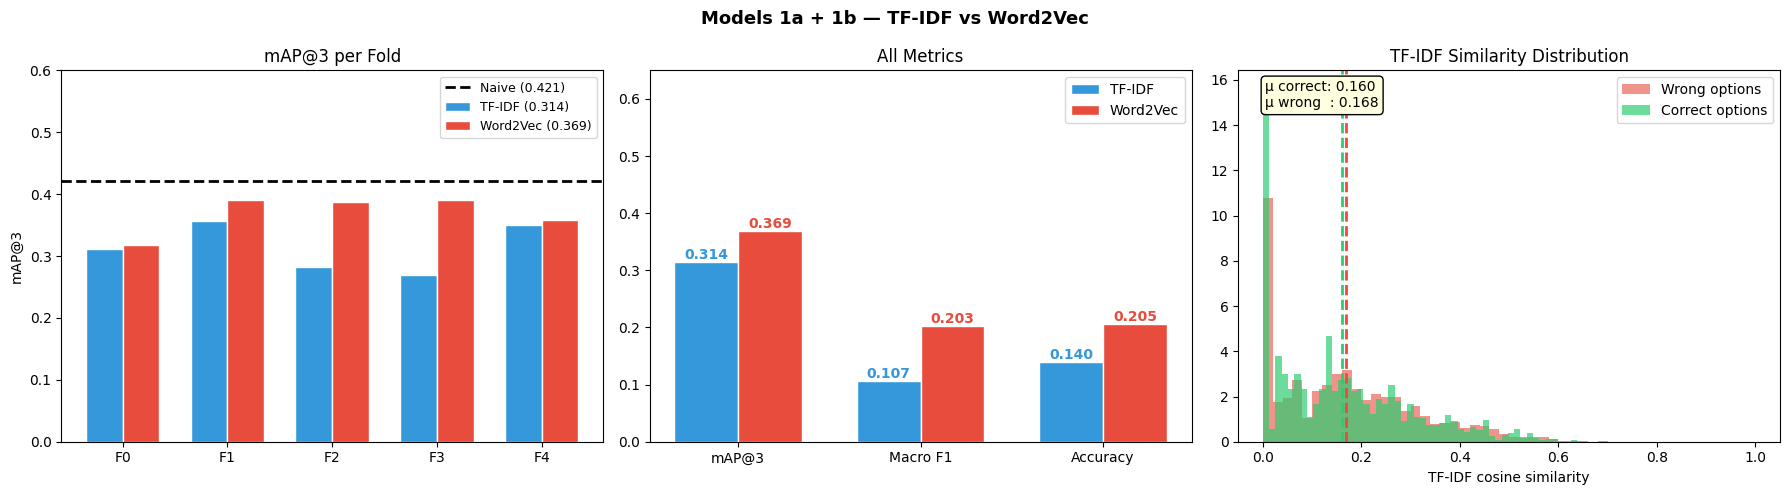

In [353]:
fig, axes = plt.subplots(1, 3, figsize=(18,5))
fig.suptitle("Models 1a + 1b — TF-IDF vs Word2Vec",
             fontsize=13, fontweight="bold")

x = np.arange(5); w = 0.35
ax = axes[0]
ax.bar(x-w/2, tfidf_fold_map3, w, color="#3498db",
       edgecolor="white", label=f"TF-IDF ({tfidf_cv_map3:.3f})")
ax.bar(x+w/2, w2v_fold_map3,   w, color="#e74c3c",
       edgecolor="white", label=f"Word2Vec ({w2v_cv_map3:.3f})")
ax.axhline(y=naive_map3, color="black", linestyle="--",
           linewidth=2, label=f"Naive ({naive_map3:.3f})")
ax.set_xticks(x); ax.set_xticklabels([f"F{i}" for i in range(5)])
ax.set_title("mAP@3 per Fold"); ax.set_ylabel("mAP@3")
ax.legend(fontsize=9); ax.set_ylim(0, 0.60)

ax = axes[1]
metrics = ["mAP@3","Macro F1","Accuracy"]
tv = [tfidf_cv_map3, tfidf_cv_f1, tfidf_cv_acc]
wv = [w2v_cv_map3,   w2v_cv_f1,   w2v_cv_acc]
x2 = np.arange(3)
ax.bar(x2-w/2, tv, w, color="#3498db", edgecolor="white", label="TF-IDF")
ax.bar(x2+w/2, wv, w, color="#e74c3c", edgecolor="white", label="Word2Vec")
for i,(a,b) in enumerate(zip(tv,wv)):
    ax.text(i-w/2, a+0.005, f"{a:.3f}", ha="center",
            fontsize=10, fontweight="bold", color="#3498db")
    ax.text(i+w/2, b+0.005, f"{b:.3f}", ha="center",
            fontsize=10, fontweight="bold", color="#e74c3c")
ax.set_xticks(x2); ax.set_xticklabels(metrics)
ax.set_title("All Metrics"); ax.legend(); ax.set_ylim(0,0.65)

ax = axes[2]
correct_sims, wrong_sims = [], []
for i,(_,row) in enumerate(train.iterrows()):
    ci = LABEL_MAP[row["answer"]]
    for j in range(5):
        (correct_sims if j==ci else wrong_sims).append(tfidf_train_sims[i,j])
ax.hist(wrong_sims,   bins=50, alpha=0.6, color="#e74c3c",
        label="Wrong options", density=True)
ax.hist(correct_sims, bins=50, alpha=0.7, color="#2ecc71",
        label="Correct options", density=True)
ax.axvline(x=np.mean(correct_sims), color="#2ecc71", linestyle="--", linewidth=2)
ax.axvline(x=np.mean(wrong_sims),   color="#e74c3c", linestyle="--", linewidth=2)
ax.text(0.05, 0.90, f"μ correct: {np.mean(correct_sims):.3f}\n"
        f"μ wrong  : {np.mean(wrong_sims):.3f}",
        transform=ax.transAxes, fontsize=10,
        bbox=dict(boxstyle="round", facecolor="lightyellow"))
ax.set_xlabel("TF-IDF cosine similarity")
ax.set_title("TF-IDF Similarity Distribution"); ax.legend()

plt.tight_layout()
plt.savefig("plot_08_bow_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [354]:
stat, p = wilcoxon(tfidf_fold_map3, w2v_fold_map3)
print("Wilcoxon signed-rank test: TF-IDF vs Word2Vec fold scores")
print(f"  TF-IDF folds : {[round(x,4) for x in tfidf_fold_map3]}")
print(f"  W2V folds    : {[round(x,4) for x in w2v_fold_map3]}")
print(f"  statistic    : {stat:.4f}")
print(f"  p-value      : {p:.4f}")
print(f"  Significant? : {'Yes (p<0.05)' if p<0.05 else 'No — difference may be noise'}")

Wilcoxon signed-rank test: TF-IDF vs Word2Vec fold scores
  TF-IDF folds : [0.3108, 0.3571, 0.2829, 0.2696, 0.3504]
  W2V folds    : [0.3179, 0.3904, 0.3875, 0.3912, 0.3575]
  statistic    : 0.0000
  p-value      : 0.0625
  Significant? : No — difference may be noise


In [355]:
class BiLSTMAttention(nn.Module):
    def __init__(self, vocab_size, embed_dim=256, hidden_dim=256,
                 num_layers=2, num_classes=5, dropout=0.3, padding_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim,
                                      padding_idx=padding_idx)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=num_layers,
                            batch_first=True, bidirectional=True,
                            dropout=dropout if num_layers>1 else 0.0)
        self.attention  = nn.Linear(hidden_dim*2, 1, bias=False)
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden_dim*2, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes),
        )

    def attention_pool(self, lstm_out, pad_mask):
        scores  = self.attention(lstm_out).squeeze(-1)
        if pad_mask is not None:
            scores = scores.masked_fill(pad_mask, float("-inf"))
        weights = torch.softmax(scores, dim=1).unsqueeze(-1)
        return (weights * lstm_out).sum(dim=1)

    def forward(self, input_ids):
        pad_mask = (input_ids == 0)
        x = F.dropout(self.embedding(input_ids),
                      p=0.3, training=self.training)
        lstm_out, _ = self.lstm(x)
        context     = self.attention_pool(lstm_out, pad_mask)
        return self.classifier(context)

class MCQDataset(Dataset):
    def __init__(self, ids, labels=None):
        self.ids    = torch.LongTensor(ids)
        self.labels = torch.LongTensor(labels) if labels is not None else None
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        return (self.ids[i], self.labels[i]) if self.labels is not None else self.ids[i]

def train_epoch(model, loader, opt, crit, sched=None):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for ids, labels in loader:
        ids, labels = ids.to(device), labels.to(device)
        opt.zero_grad()
        logits = model(ids)
        loss   = crit(logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        total_loss += loss.item()*len(labels)
        correct    += (logits.argmax(1)==labels).sum().item()
        total      += len(labels)
    if sched: sched.step()
    return total_loss/total, correct/total

@torch.no_grad()
def eval_epoch(model, loader, crit):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    for batch in loader:
        if len(batch)==2: ids, labels = batch; ids,labels = ids.to(device),labels.to(device)
        else: ids = batch.to(device); labels = None
        logits = model(ids)
        if labels is not None:
            loss = crit(logits, labels)
            total_loss += loss.item()*len(labels)
            correct    += (logits.argmax(1)==labels).sum().item()
            total      += len(labels)
            all_labels.extend(labels.cpu().numpy())
        all_preds.extend(logits.argmax(1).cpu().numpy())
    acc = correct/total if total>0 else 0.0
    f1  = f1_score(all_labels, all_preds[:len(all_labels)],
                   average="macro", zero_division=0) if all_labels else 0.0
    return total_loss/max(total,1), acc, f1

@torch.no_grad()
def get_probs(model, ids_array, batch_size=64):
    model.eval()
    ds  = MCQDataset(ids_array)
    dl  = DataLoader(ds, batch_size=batch_size, shuffle=False)
    out = []
    for ids in dl:
        logits = model(ids.to(device))
        out.append(torch.softmax(logits,1).cpu().numpy())
    return np.vstack(out)

# Verify
test_m = BiLSTMAttention(VOCAB_SIZE).to(device)
test_i = torch.randint(0, VOCAB_SIZE, (4, MAX_SEQ_LEN)).to(device)
test_o = test_m(test_i)
total_p = sum(p.numel() for p in test_m.parameters())
print(f"Output shape : {test_o.shape}  (should be [4, 5])")
print(f"Total params : {total_p:,}")
del test_m, test_i, test_o; gc.collect()

Output shape : torch.Size([4, 5])  (should be [4, 5])
Total params : 3,496,453


65418

In [356]:
EPOCHS = 8; BATCH_SIZE = 32; LR = 1e-3

run_bilstm = wandb.init(
    project=WANDB_PROJECT, entity=WANDB_ENTITY,
    name="model2-bilstm-attention",
    config={"model_type":"from_scratch","arch":"BiLSTM+Attention",
            "vocab_size":VOCAB_SIZE,"embed_dim":256,"hidden_dim":256,
            "num_layers":2,"dropout":0.3,"max_seq":MAX_SEQ_LEN,
            "batch_size":BATCH_SIZE,"lr":LR,"epochs":EPOCHS,
            "optimizer":"Adam","scheduler":"CosineAnnealingLR",
            "grad_clip":1.0,"loss":"CrossEntropyLoss",
            "cv":"GroupKFold-5","seed":SEED}
)

bilstm_fold_map3, bilstm_fold_f1, bilstm_fold_acc = [], [], []
all_fold_curves = []

for fold, (tr_idx, va_idx) in enumerate(splits):
    print(f"\n── Fold {fold} ──")
    tr_dl = DataLoader(MCQDataset(train_ids[tr_idx], train_labels[tr_idx]),
                       batch_size=BATCH_SIZE, shuffle=True, pin_memory=True)
    va_dl = DataLoader(MCQDataset(train_ids[va_idx], train_labels[va_idx]),
                       batch_size=64, shuffle=False, pin_memory=True)

    model = BiLSTMAttention(VOCAB_SIZE).to(device)
    opt   = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS, eta_min=1e-5)
    crit  = nn.CrossEntropyLoss()
    curves = {"tr_loss":[],"va_loss":[],"va_f1":[],"va_acc":[]}

    for epoch in range(EPOCHS):
        tr_loss, tr_acc     = train_epoch(model, tr_dl, opt, crit, sched)
        va_loss, va_acc, va_f1 = eval_epoch(model, va_dl, crit)
        curves["tr_loss"].append(tr_loss); curves["va_loss"].append(va_loss)
        curves["va_f1"].append(va_f1);     curves["va_acc"].append(va_acc)
        wandb.log({"fold":fold,"epoch":epoch,"train_loss":tr_loss,
                   "train_acc":tr_acc,"val_loss":va_loss,
                   "val_acc":va_acc,"val_f1":va_f1})
        print(f"  E{epoch+1}: tr_loss={tr_loss:.4f} tr_acc={tr_acc:.3f} "
              f"| val_loss={va_loss:.4f} val_acc={va_acc:.3f} val_f1={va_f1:.4f}")

    all_fold_curves.append(curves)
    val_probs  = get_probs(model, train_ids[va_idx])
    top3_preds = [[Options[j] for j in np.argsort(-val_probs[i])[:3]]
                  for i in range(len(val_probs))]
    top1_preds = [Options[np.argmax(val_probs[i])] for i in range(len(val_probs))]
    m3  = mapk(train.iloc[va_idx]["answer"].tolist(), top3_preds)
    f1  = macro_f1(train.iloc[va_idx]["answer"].tolist(), top1_preds)
    acc = top1_acc(train.iloc[va_idx]["answer"].tolist(), top1_preds)
    bilstm_fold_map3.append(m3); bilstm_fold_f1.append(f1); bilstm_fold_acc.append(acc)
    wandb.log({"fold":fold,"fold_map3":m3,"fold_f1":f1,"fold_acc":acc})
    print(f"  Fold {fold} → mAP@3={m3:.4f}  F1={f1:.4f}  Acc={acc:.4f}")
    del model, opt, sched, crit; gc.collect(); torch.cuda.empty_cache()

bilstm_cv_map3 = np.mean(bilstm_fold_map3)
bilstm_cv_f1   = np.mean(bilstm_fold_f1)
bilstm_cv_acc  = np.mean(bilstm_fold_acc)
bilstm_cv_std  = np.std(bilstm_fold_map3)
print(f"\nBi-LSTM CV mAP@3: {bilstm_cv_map3:.4f} ± {bilstm_cv_std:.4f}")
print(f"Bi-LSTM CV F1   : {bilstm_cv_f1:.4f}")


── Fold 0 ──
  E1: tr_loss=1.1558 tr_acc=0.527 | val_loss=4.0987 val_acc=0.145 val_f1=0.1474
  E2: tr_loss=0.1447 tr_acc=0.950 | val_loss=4.9737 val_acc=0.203 val_f1=0.2149
  E3: tr_loss=0.0299 tr_acc=0.993 | val_loss=5.4594 val_acc=0.205 val_f1=0.1936
  E4: tr_loss=0.0110 tr_acc=0.998 | val_loss=6.7097 val_acc=0.207 val_f1=0.2083
  E5: tr_loss=0.0067 tr_acc=0.999 | val_loss=6.2872 val_acc=0.152 val_f1=0.1736
  E6: tr_loss=0.0008 tr_acc=1.000 | val_loss=6.2783 val_acc=0.158 val_f1=0.1680
  E7: tr_loss=0.0002 tr_acc=1.000 | val_loss=6.3843 val_acc=0.155 val_f1=0.1665
  E8: tr_loss=0.0003 tr_acc=1.000 | val_loss=6.3886 val_acc=0.152 val_f1=0.1645
  Fold 0 → mAP@3=0.3471  F1=0.1645  Acc=0.1525

── Fold 1 ──
  E1: tr_loss=1.2040 tr_acc=0.489 | val_loss=3.7835 val_acc=0.172 val_f1=0.1383
  E2: tr_loss=0.1881 tr_acc=0.934 | val_loss=4.6915 val_acc=0.260 val_f1=0.2718
  E3: tr_loss=0.0190 tr_acc=0.994 | val_loss=5.0121 val_acc=0.338 val_f1=0.3198
  E4: tr_loss=0.0112 tr_acc=0.996 | val_loss=

In [357]:
print("Training final Bi-LSTM on all 2000 rows...")
full_dl      = DataLoader(MCQDataset(train_ids, train_labels),
                          batch_size=BATCH_SIZE, shuffle=True, pin_memory=True)
bilstm_model = BiLSTMAttention(VOCAB_SIZE).to(device)
opt_f        = torch.optim.Adam(bilstm_model.parameters(), lr=LR, weight_decay=1e-5)
sched_f      = torch.optim.lr_scheduler.CosineAnnealingLR(opt_f, T_max=EPOCHS, eta_min=1e-5)
crit_f       = nn.CrossEntropyLoss()
final_curves = {"loss":[], "acc":[]}

for epoch in range(EPOCHS):
    loss, acc = train_epoch(bilstm_model, full_dl, opt_f, crit_f, sched_f)
    final_curves["loss"].append(loss); final_curves["acc"].append(acc)
    wandb.log({"final_epoch":epoch,"final_loss":loss,"final_acc":acc})
    print(f"  Epoch {epoch+1}: loss={loss:.4f}  acc={acc:.4f}")

bilstm_test_probs  = get_probs(bilstm_model, test_ids)
bilstm_train_probs = get_probs(bilstm_model, train_ids)
bilstm_test_preds  = [[Options[j] for j in np.argsort(-bilstm_test_probs[i])[:3]]
                      for i in range(len(bilstm_test_probs))]
bilstm_train_top1  = [Options[np.argmax(bilstm_train_probs[i])]
                      for i in range(len(bilstm_train_probs))]

wandb.log({"cv_mean_map3":bilstm_cv_map3,"cv_std":bilstm_cv_std,
           "cv_mean_f1":bilstm_cv_f1,"beats_naive":int(bilstm_cv_map3>naive_map3),
           "beats_tfidf":int(bilstm_cv_map3>tfidf_cv_map3)})
run_bilstm.finish()
print(f"\nW&B Run 3 finished ✓")
print(f"bilstm_test_probs  : {bilstm_test_probs.shape}")
print(f"bilstm_train_probs : {bilstm_train_probs.shape}")

Training final Bi-LSTM on all 2000 rows...
  Epoch 1: loss=1.0452  acc=0.5620
  Epoch 2: loss=0.0989  acc=0.9705
  Epoch 3: loss=0.0235  acc=0.9955
  Epoch 4: loss=0.0089  acc=0.9975
  Epoch 5: loss=0.0033  acc=0.9995
  Epoch 6: loss=0.0043  acc=0.9990
  Epoch 7: loss=0.0005  acc=1.0000
  Epoch 8: loss=0.0006  acc=1.0000


beats_naive,▁
beats_tfidf,▁
cv_mean_f1,▁
cv_mean_map3,▁
cv_std,▁
epoch,▁▂▃▄▅▆▇█▁▂▃▄▅▆▇█▁▂▃▄▅▆▇█▁▂▃▄▅▆▇█▁▂▃▄▅▆▇█
final_acc,▁███████
final_epoch,▁▂▃▄▅▆▇█
final_loss,█▂▁▁▁▁▁▁
fold,▁▁▁▁▁▁▁▁▃▃▃▃▃▃▃▃▅▅▅▅▅▅▅▅▆▆▆▆▆▆▆▆████████
+8,...



W&B Run 3 finished ✓
bilstm_test_probs  : (500, 5)
bilstm_train_probs : (2000, 5)


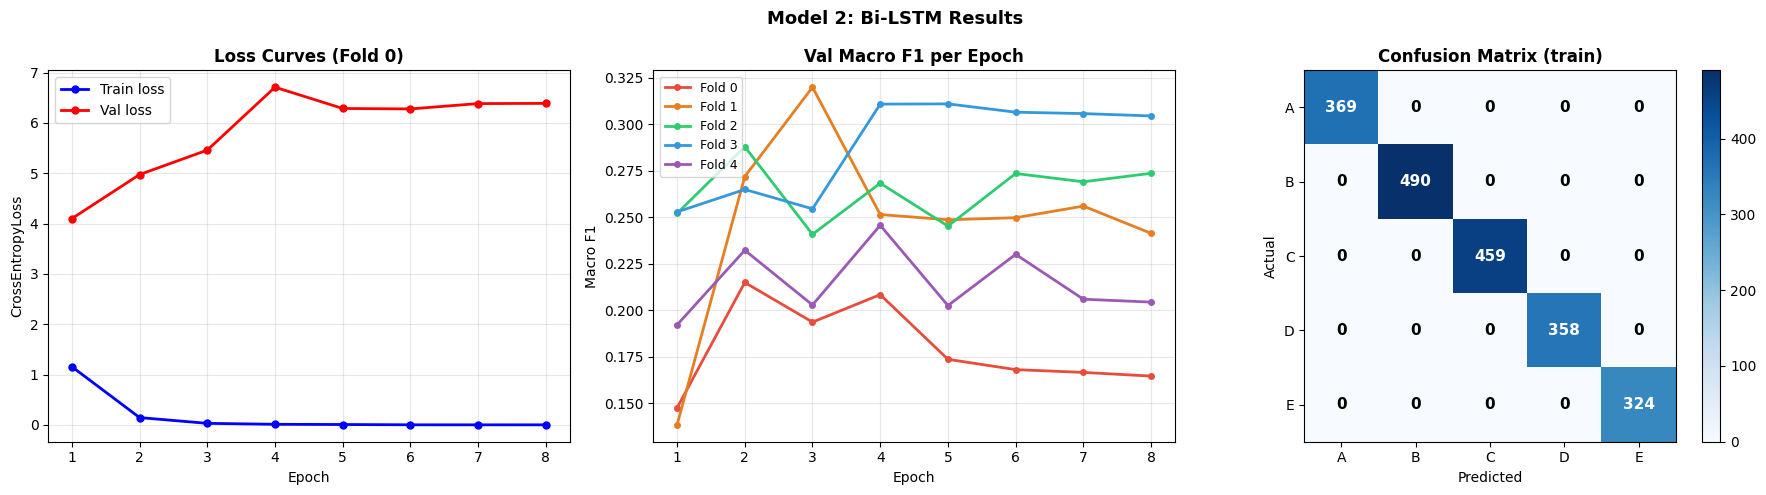

In [358]:
fig, axes = plt.subplots(1, 3, figsize=(18,5))
fig.suptitle("Model 2: Bi-LSTM Results", fontsize=13, fontweight="bold")

ax = axes[0]
ep = range(1, EPOCHS+1)
ax.plot(ep, all_fold_curves[0]["tr_loss"], "b-o", ms=5, lw=2, label="Train loss")
ax.plot(ep, all_fold_curves[0]["va_loss"], "r-o", ms=5, lw=2, label="Val loss")
ax.set_title("Loss Curves (Fold 0)", fontweight="bold")
ax.set_xlabel("Epoch"); ax.set_ylabel("CrossEntropyLoss")
ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]
colors_f = ["#e74c3c","#e67e22","#2ecc71","#3498db","#9b59b6"]
for fi, curves in enumerate(all_fold_curves):
    ax.plot(ep, curves["va_f1"], color=colors_f[fi],
            lw=2, marker="o", ms=4, label=f"Fold {fi}")
ax.set_title("Val Macro F1 per Epoch", fontweight="bold")
ax.set_xlabel("Epoch"); ax.set_ylabel("Macro F1")
ax.legend(fontsize=9); ax.grid(alpha=0.3)

ax = axes[2]
cm = confusion_matrix(train["answer"], bilstm_train_top1, labels=Options)
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(5)); ax.set_yticks(range(5))
ax.set_xticklabels(Options); ax.set_yticklabels(Options)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title("Confusion Matrix (train)", fontweight="bold")
for i in range(5):
    for j in range(5):
        ax.text(j, i, str(cm[i,j]), ha="center", va="center",
                fontsize=11, fontweight="bold",
                color="white" if cm[i,j]>cm.max()*0.5 else "black")
plt.colorbar(im, ax=ax)

plt.tight_layout()
plt.savefig("plot_09_bilstm_results.png", dpi=150, bbox_inches="tight")
plt.show()

In [359]:
print("Loading all-MiniLM-L6-v2...")
minilm = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

def minilm_predict(df, model, batch_size=64):
    p_embs = model.encode(df["prompt"].tolist(), batch_size=batch_size,
                          normalize_embeddings=True, show_progress_bar=False)
    sims   = np.zeros((len(df),5))
    for j,c in enumerate(Options):
        o_embs     = model.encode(df[c].tolist(), batch_size=batch_size,
                                   normalize_embeddings=True, show_progress_bar=False)
        sims[:,j]  = np.sum(p_embs*o_embs, axis=1)
    order  = np.argsort(-sims, axis=1)
    preds  = [[Options[i] for i in r] for r in order]
    top1   = [Options[r[0]] for r in order]
    return preds, top1, sims

run_minilm = wandb.init(
    project=WANDB_PROJECT, entity=WANDB_ENTITY,
    name="model3-minilm-zeroshot",
    config={"model_type":"pretrained","model":"all-MiniLM-L6-v2",
            "fine_tuned":False,"embed_dim":384,"pooling":"mean",
            "normalize":True,"cv":"GroupKFold-5"}
)

minilm_fold_map3, minilm_fold_f1, minilm_fold_acc = [], [], []

for fold, (tr_idx, va_idx) in enumerate(splits):
    va_df = train.iloc[va_idx]
    preds, top1, _ = minilm_predict(va_df, minilm)
    m3  = mapk(va_df["answer"].tolist(), preds)
    f1  = macro_f1(va_df["answer"].tolist(), top1)
    acc = top1_acc(va_df["answer"].tolist(), top1)
    minilm_fold_map3.append(m3); minilm_fold_f1.append(f1); minilm_fold_acc.append(acc)
    wandb.log({"fold":fold,"val_map3":m3,"val_f1":f1,"val_acc":acc})
    print(f"Fold {fold}: mAP@3={m3:.4f}  F1={f1:.4f}  Acc={acc:.4f}")

minilm_cv_map3 = np.mean(minilm_fold_map3)
minilm_cv_f1   = np.mean(minilm_fold_f1)
minilm_cv_acc  = np.mean(minilm_fold_acc)
minilm_cv_std  = np.std(minilm_fold_map3)

print("\nEncoding full train and test sets...")
_, minilm_train_top1, minilm_train_sims = minilm_predict(train, minilm)
minilm_test_preds, minilm_test_top1, minilm_test_sims = minilm_predict(test, minilm)

wandb.log({"cv_mean_map3":minilm_cv_map3,"cv_std":minilm_cv_std,
           "cv_mean_f1":minilm_cv_f1,"beats_naive":int(minilm_cv_map3>naive_map3),
           "beats_tfidf":int(minilm_cv_map3>tfidf_cv_map3),
           "beats_bilstm":int(minilm_cv_map3>bilstm_cv_map3)})
run_minilm.finish()

print(f"\nMiniLM CV mAP@3 : {minilm_cv_map3:.4f} ± {minilm_cv_std:.4f}")
print(f"MiniLM CV F1    : {minilm_cv_f1:.4f}")
print(f"W&B Run 4 finished ✓")

Loading all-MiniLM-L6-v2...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Fold 0: mAP@3=0.4571  F1=0.2510  Acc=0.2675
Fold 1: mAP@3=0.3879  F1=0.2399  Acc=0.2550
Fold 2: mAP@3=0.3950  F1=0.2301  Acc=0.2325
Fold 3: mAP@3=0.4542  F1=0.3186  Acc=0.3150
Fold 4: mAP@3=0.4213  F1=0.2325  Acc=0.2350

Encoding full train and test sets...


beats_bilstm,▁
beats_naive,▁
beats_tfidf,▁
cv_mean_f1,▁
cv_mean_map3,▁
cv_std,▁
fold,▁▃▅▆█
val_acc,▄▃▁█▁
val_f1,▃▂▁█▁
val_map3,█▁▂█▄
beats_bilstm,1



MiniLM CV mAP@3 : 0.4231 ± 0.0288
MiniLM CV F1    : 0.2544
W&B Run 4 finished ✓


In [360]:
from sklearn.metrics import accuracy_score as sk_acc

DEBERTA   = "microsoft/deberta-v3-small"
MAX_L_DEB = 512
VAL_DF    = train.iloc[:100].reset_index(drop=True)
FT_DF     = train.iloc[100:].reset_index(drop=True)

deb_tok   = AutoTokenizer.from_pretrained(DEBERTA)

def format_deberta(row, prefix=""):
    p = (prefix+" " if prefix else "") + str(row["prompt"])
    opts = " ".join([f"{c}: {row[c]}" for c in Options])
    return p + " " + opts

def tokenize_batch(batch):
    texts = [format_deberta({"prompt":batch["prompt"][i],
                              "A":batch["A"][i],"B":batch["B"][i],
                              "C":batch["C"][i],"D":batch["D"][i],
                              "E":batch["E"][i]}) for i in range(len(batch["prompt"]))]
    enc = deb_tok(texts, padding="max_length",
                  truncation=True, max_length=MAX_L_DEB)
    enc["labels"] = batch["label"]
    return enc

ft_hf  = HFDataset.from_pandas(FT_DF[["prompt"]+Options+["label"]], preserve_index=False)
val_hf = HFDataset.from_pandas(VAL_DF[["prompt"]+Options+["label"]], preserve_index=False)
ft_tok  = ft_hf.map(tokenize_batch,  batched=True, remove_columns=ft_hf.column_names)
val_tok = val_hf.map(tokenize_batch, batched=True, remove_columns=val_hf.column_names)
ft_tok.set_format("torch"); val_tok.set_format("torch")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": sk_acc(labels,preds),
            "f1": f1_score(labels,preds,average="macro",zero_division=0)}

run_deb = wandb.init(
    project=WANDB_PROJECT, entity=WANDB_ENTITY,
    name="model4-deberta-v3-small-finetuned",
    config={"model_type":"fine_tuned","base":DEBERTA,
            "epochs":3,"lr":1e-5,"batch_size":4,
            "max_length":MAX_L_DEB,"fp16":True,
            "train_rows":len(FT_DF),"val_rows":len(VAL_DF)}
)

deb_model = AutoModelForSequenceClassification.from_pretrained(
    DEBERTA, num_labels=5, id2label=ID2LABEL, label2id=LABEL_MAP,
    ignore_mismatched_sizes=True
).to(device)

args = TrainingArguments(
    output_dir="./deb_ckpt", num_train_epochs=3,
    per_device_train_batch_size=4, per_device_eval_batch_size=8,
    learning_rate=1e-5, warmup_ratio=0.1, weight_decay=0.01,
    fp16=True, eval_strategy="epoch", save_strategy="epoch",
    load_best_model_at_end=True, metric_for_best_model="f1",
    greater_is_better=True, logging_steps=50, save_total_limit=1,
    report_to="wandb", run_name="model4-deberta-v3-small-finetuned",
    seed=SEED,
)

trainer = Trainer(
    model=deb_model, args=args,
    train_dataset=ft_tok, eval_dataset=val_tok,
    compute_metrics=compute_metrics,
)

print(f"Fine-tuning DeBERTa-v3-small on {len(FT_DF)} rows (~20 min)...")
trainer.train()
eval_res = trainer.evaluate()
print(f"\nFinal eval: {eval_res}")

deb_model.save_pretrained("./deb_best")
deb_tok.save_pretrained("./deb_best")

@torch.no_grad()
def deb_get_probs(df, model, tokenizer, batch_size=16, prefix=""):
    model.eval(); all_probs = []
    texts = [format_deberta(row, prefix=prefix) for _,row in df.iterrows()]
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(texts[i:i+batch_size], padding=True,
                        truncation=True, max_length=MAX_L_DEB, return_tensors="pt")
        enc = {k:v.to(device) for k,v in enc.items()}
        all_probs.append(torch.softmax(model(**enc).logits.float(),1).cpu().numpy())
    return np.vstack(all_probs)

print("\nGenerating DeBERTa probabilities...")
deb_test_probs  = deb_get_probs(test,  deb_model, deb_tok)
deb_train_probs = deb_get_probs(train, deb_model, deb_tok)

deb_val_probs  = deb_train_probs[:100]
deb_val_top3   = [[Options[j] for j in np.argsort(-deb_val_probs[i])[:3]]
                  for i in range(100)]
deb_val_top1   = [Options[np.argmax(deb_val_probs[i])] for i in range(100)]
deb_val_map3   = mapk(VAL_DF["answer"].tolist(), deb_val_top3)
deb_val_f1     = macro_f1(VAL_DF["answer"].tolist(), deb_val_top1)

deb_test_preds = [[Options[j] for j in np.argsort(-deb_test_probs[i])[:3]]
                  for i in range(len(deb_test_probs))]
deb_train_top1 = [Options[np.argmax(deb_train_probs[i])]
                  for i in range(len(deb_train_probs))]

wandb.log({"val_map3":deb_val_map3,"val_f1":deb_val_f1,
           "val_accuracy":eval_res.get("eval_accuracy",0)})
run_deb.finish()

print(f"\nDeBERTa val mAP@3 : {deb_val_map3:.4f}")
print(f"DeBERTa val F1    : {deb_val_f1:.4f}")
print(f"W&B Run 5 finished ✓")

config.json:   0%|          | 0.00/578 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

Map:   0%|          | 0/1900 [00:00<?, ? examples/s]

Map:   0%|          | 0/100 [00:00<?, ? examples/s]

...

DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
pooler.dense.bias                       | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.dense.weight                     | MISSING    | 
classifier.weight       

model.safetensors:   0%|          | 0.00/286M [00:00<?, ?B/s]

warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Fine-tuning DeBERTa-v3-small on 1900 rows (~20 min)...


ValueError: Attempting to unscale FP16 gradients.

In [361]:
def minmax(x):
    mn = x.min(axis=1, keepdims=True)
    mx = x.max(axis=1, keepdims=True)
    return (x-mn)/(mx-mn+1e-9)

def build_ensemble(tfidf_s, w2v_s, minilm_s, bilstm_p, deberta_p):
    return (0.05*minmax(tfidf_s) + 0.05*minmax(w2v_s) +
            0.20*minmax(minilm_s)+ 0.15*minmax(bilstm_p)+
            0.55*minmax(deberta_p))

def final_predict(df, tfidf_s, w2v_s, minilm_s, bilstm_p, deberta_p, lkp=None):
    blended = build_ensemble(tfidf_s, w2v_s, minilm_s, bilstm_p, deberta_p)
    preds   = []
    for i,(_,row) in enumerate(df.iterrows()):
        sim_order = [Options[j] for j in np.argsort(-blended[i])]
        if lkp is not None and row["core"] in lkp:
            ret  = lkp[row["core"]]
            rest = [x for x in sim_order if x!=ret][:2]
            preds.append([ret]+rest)
        else:
            preds.append(sim_order[:3])
    return preds

run_ens = wandb.init(
    project=WANDB_PROJECT, entity=WANDB_ENTITY,
    name="model5-retrieval-ensemble",
    config={"model_type":"ensemble",
            "components":["tfidf","word2vec","minilm","bilstm","deberta","retrieval"],
            "weights":{"tfidf":0.05,"w2v":0.05,"minilm":0.20,"bilstm":0.15,"deberta":0.55},
            "strategy":"retrieval_rank1_then_similarity"}
)

ens_fold_map3, ens_fold_f1 = [], []

for fold, (tr_idx, va_idx) in enumerate(splits):
    tr_df = train.iloc[tr_idx]; va_df = train.iloc[va_idx]

    corpus = pd.concat([tr_df[f"{c}_clean"] for c in ["prompt"]+Options])
    vec_f  = TfidfVectorizer(max_features=20000, ngram_range=(1,2),
                              stop_words="english", sublinear_tf=True).fit(corpus)
    _, _, t_sims = tfidf_predict(va_df, vec_f)

    corp_w = [tl for c in ["prompt"]+Options for tl in tr_df[f"{c}_tok"].tolist() if tl]
    mw     = Word2Vec(sentences=corp_w, vector_size=150, window=5,
                      min_count=2, workers=4, epochs=10, sg=1, seed=SEED)
    _, _, w_sims = w2v_predict(va_df, mw)

    _, _, mn_sims = minilm_predict(va_df, minilm)

    va_ids  = train_ids[va_idx]
    bl_dl   = DataLoader(MCQDataset(va_ids), batch_size=64)
    bl_p    = []
    bilstm_model.eval()
    with torch.no_grad():
        for ids in bl_dl:
            bl_p.append(torch.softmax(bilstm_model(ids.to(device)),1).cpu().numpy())
    bl_p = np.vstack(bl_p)

    deb_p = deb_train_probs[va_idx]

    fold_lkp = (tr_df.groupby("core")["answer"]
                .agg(lambda s: Counter(s).most_common(1)[0][0]).to_dict())

    preds  = final_predict(va_df, t_sims, w_sims, mn_sims, bl_p, deb_p, fold_lkp)
    top1   = [p[0] for p in preds]
    m3     = mapk(va_df["answer"].tolist(), preds)
    f1     = macro_f1(va_df["answer"].tolist(), top1)
    ens_fold_map3.append(m3); ens_fold_f1.append(f1)
    wandb.log({"fold":fold,"val_map3":m3,"val_f1":f1})
    print(f"Fold {fold}: mAP@3={m3:.4f}  F1={f1:.4f}")

ens_cv_map3 = np.mean(ens_fold_map3)
ens_cv_f1   = np.mean(ens_fold_f1)
ens_cv_std  = np.std(ens_fold_map3)

final_preds = final_predict(test, tfidf_test_sims, w2v_test_sims,
                             minilm_test_sims, bilstm_test_probs,
                             deb_test_probs, lookup)

submission = pd.DataFrame({
    "ID":         test["id"],
    "Prediction": [" ".join(p) for p in final_preds]
})
submission.to_csv("submission_ensemble.csv", index=False)

wandb.log({"cv_mean_map3":ens_cv_map3,"cv_std":ens_cv_std,"cv_mean_f1":ens_cv_f1})
run_ens.finish()

print(f"\nEnsemble CV mAP@3 : {ens_cv_map3:.4f} ± {ens_cv_std:.4f}")
print(f"Ensemble CV F1    : {ens_cv_f1:.4f}")
print(f"submission_ensemble.csv saved ✓")
print(f"W&B Run 6 finished ✓")

NameError: name 'deb_train_probs' is not defined

In [362]:

print("COMPLETE MODEL COMPARISON")
print("--"*70)
print(f"{'Model':<38} {'mAP@3':>8} {'±std':>7} {'F1':>8} {'Acc':>8} {'Type'}")
print("─"*70)
rows_summary = [
    ("Naive baseline [B,C,A]",   naive_map3,     0,            0,            0,           "baseline"),
    ("Model 1a: TF-IDF cosine",  tfidf_cv_map3,  tfidf_cv_std, tfidf_cv_f1,  tfidf_cv_acc,"from_scratch"),
    ("Model 1b: Word2Vec cosine",w2v_cv_map3,    w2v_cv_std,   w2v_cv_f1,    w2v_cv_acc,  "from_scratch"),
    ("Model 2:  Bi-LSTM+Attn",   bilstm_cv_map3, bilstm_cv_std,bilstm_cv_f1, bilstm_cv_acc,"from_scratch"),
    ("Model 3:  MiniLM zero-shot",minilm_cv_map3,minilm_cv_std,minilm_cv_f1, minilm_cv_acc,"pretrained"),
    ("Model 4:  DeBERTa fine-tune",deb_val_map3, 0,            deb_val_f1,   0,            "fine_tuned"),
    ("Model 5:  Ensemble+Retrieval",ens_cv_map3, ens_cv_std,   ens_cv_f1,    0,            "ensemble"),
]
for name, m3, std, f1, acc, mtype in rows_summary:
    std_s = f"±{std:.3f}" if std>0 else "—"
    f1_s  = f"{f1:.4f}"   if f1>0  else "—"
    acc_s = f"{acc:.4f}"  if acc>0 else "—"
    print(f"  {name:<36} {m3:>8.4f} {std_s:>7} {f1_s:>8} {acc_s:>8}  {mtype}")
print("═"*70)
print(f"\nLeaderboard (retrieval alone, submitted): 0.7415")
print(f"Upload submission_ensemble.csv for final score")

COMPLETE MODEL COMPARISON
--------------------------------------------------------------------------------------------------------------------------------------------
Model                                     mAP@3    ±std       F1      Acc Type
──────────────────────────────────────────────────────────────────────


NameError: name 'deb_val_map3' is not defined

In [363]:
actuals = train["answer"].tolist()

model_correct = {}
for mname, probs in [("tfidf",   tfidf_train_sims),
                      ("w2v",     w2v_train_sims),
                      ("bilstm",  bilstm_train_probs),
                      ("minilm",  minilm_train_sims),
                      ("deberta", deb_train_probs)]:
    top1 = [Options[np.argmax(probs[i])] for i in range(len(train))]
    model_correct[mname] = [t==a for t,a in zip(top1, actuals)]

all_wrong_mask = ~np.array([
    any(model_correct[m][i] for m in model_correct)
    for i in range(len(train))
])
all_wrong_df = train[all_wrong_mask].copy()

print(f"Questions ALL models get wrong: {all_wrong_mask.sum()} / {len(train)}")
print(f"\nDomain breakdown of failures:")
print(all_wrong_df["domain"].value_counts().to_string())
print(f"\nDifficulty (option overlap) of failures:")
print(all_wrong_df["option_overlap"].describe().round(3))
print(f"\nAvg overlap in failures    : {all_wrong_df['option_overlap'].mean():.3f}")
print(f"Avg overlap in full dataset: {train['option_overlap'].mean():.3f}")
print(f"\nQuestion type breakdown:")
print(all_wrong_df["q_word"].value_counts().to_string())
print(f"\nFirst 5 examples:")
for _,row in all_wrong_df.head(5).iterrows():
    print(f"\n  [{row['answer']}] {row['prompt'][:90]}")
    print(f"  Overlap: {row['option_overlap']:.3f} | Domain: {row['domain']}")

NameError: name 'deb_train_probs' is not defined

NameError: name 'deb_val_map3' is not defined

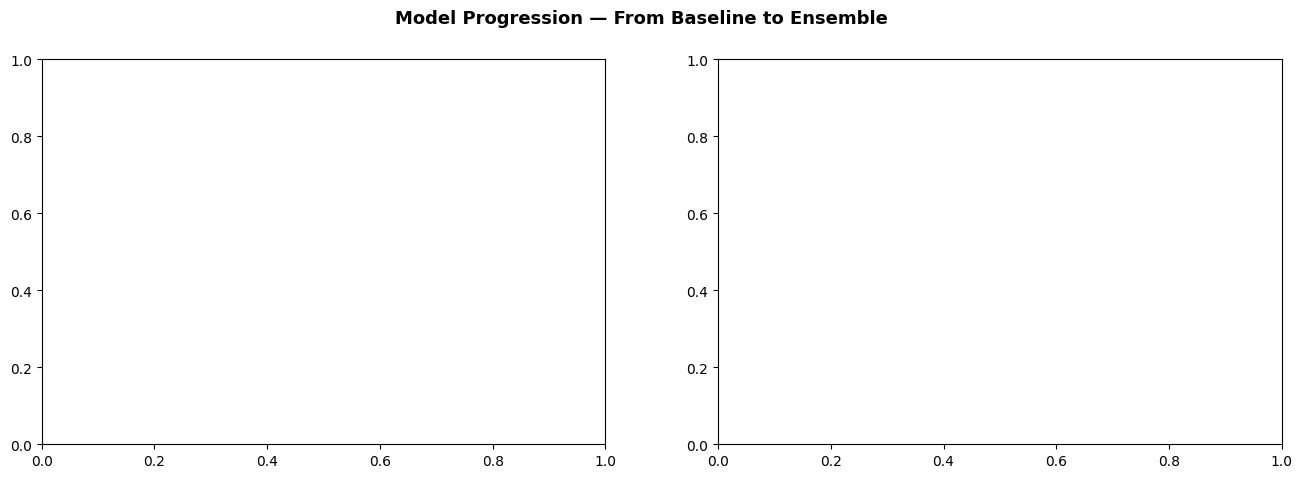

In [364]:
fig, axes = plt.subplots(1, 2, figsize=(16,5))
fig.suptitle("Model Progression — From Baseline to Ensemble",
             fontsize=13, fontweight="bold")

model_names = ["Naive","TF-IDF","Word2Vec","Bi-LSTM","MiniLM","DeBERTa","Ensemble"]
map3_scores = [naive_map3, tfidf_cv_map3, w2v_cv_map3,
               bilstm_cv_map3, minilm_cv_map3, deb_val_map3, ens_cv_map3]
colors_prog = ["#95a5a6","#3498db","#e74c3c","#9b59b6","#2ecc71","#e67e22","#f1c40f"]

ax = axes[0]
bars = ax.bar(model_names, map3_scores, color=colors_prog, edgecolor="white", linewidth=1.5)
ax.axhline(y=0.73, color="red", linestyle="--", linewidth=2, label="Cutoff (0.73)")
ax.axhline(y=naive_map3, color="gray", linestyle=":", linewidth=1.5)
for bar, val in zip(bars, map3_scores):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
            f"{val:.3f}", ha="center", va="bottom",
            fontsize=9, fontweight="bold")
ax.set_ylabel("CV mAP@3"); ax.legend()
ax.set_title("mAP@3 Across All Models", fontweight="bold")
ax.set_ylim(0, max(map3_scores)*1.15)
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")

ax = axes[1]
diff_bins = [
    ("Easy\n(J<0.3)",    train["option_overlap"]<0.3),
    ("Medium\n(0.3-0.6)",(train["option_overlap"]>=0.3)&(train["option_overlap"]<0.6)),
    ("Hard\n(J>0.6)",    train["option_overlap"]>=0.6),
]
diff_colors = {"TF-IDF":"#3498db","Bi-LSTM":"#9b59b6","DeBERTa":"#e67e22"}
diff_probs  = {"TF-IDF":tfidf_train_sims,"Bi-LSTM":bilstm_train_probs,"DeBERTa":deb_train_probs}
x_bins = np.arange(3); wd = 0.25; offsets = [-wd, 0, wd]

for (mname, color, offset) in zip(diff_colors, diff_colors.values(), offsets):
    probs_m = diff_probs[mname]
    scores_d = []
    for _, mask in diff_bins:
        sub_p = np.array([probs_m[i] for i in range(len(train)) if mask.iloc[i]])
        sub_a = train.loc[mask,"answer"].tolist()
        sub_t3 = [[Options[j] for j in np.argsort(-sub_p[k])[:3]] for k in range(len(sub_p))]
        scores_d.append(mapk(sub_a, sub_t3))
    bars_d = ax.bar(x_bins+offset, scores_d, wd, color=color,
                    edgecolor="white", label=mname)
    for bar,v in zip(bars_d, scores_d):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
                f"{v:.2f}", ha="center", fontsize=9, color=color, fontweight="bold")

ax.set_xticks(x_bins); ax.set_xticklabels([b for b,_ in diff_bins])
ax.set_ylabel("mAP@3"); ax.legend()
ax.set_title("Performance by Question Difficulty", fontweight="bold")
ax.set_ylim(0, 0.9)

plt.tight_layout()
plt.savefig("plot_10_progression_difficulty.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:

# ─────────────────────────────────────────────────────────────────────────
# mAP@3 — DEFINED FIRST
# WHY first, before even looking at data:
# The metric is set by the competition rules, not by anything
# we discover. We need it to evaluate the naive baseline which
# is the FIRST thing we compute after the label distribution.
# ─────────────────────────────────────────────────────────────────────────
def apk(actual: str, pred: list, k: int = 3) -> float:
    """
    Average Precision at K for a single question.
    If correct answer is at rank 1: 1/1 = 1.000
    If correct answer is at rank 2: 1/2 = 0.500
    If correct answer is at rank 3: 1/3 = 0.333
    If not in top-k             : 0.000
    """
    pred = pred[:k]
    return 1.0 / (pred.index(actual) + 1) if actual in pred else 0.0

def mapk(actuals: list, preds: list, k: int = 3) -> float:
    """Mean Average Precision at K across all questions."""
    return float(np.mean([apk(a, p, k) for a, p in zip(actuals, preds)]))

def macro_f1(actuals: list, top1: list) -> float:
    """Macro F1 on top-1 predictions. Required by project rubric."""
    return f1_score(actuals, top1, average="macro",
                    labels=Options, zero_division=0)

def top1_acc(actuals: list, top1: list) -> float:
    return accuracy_score(actuals, top1)

print("\nmAP@3, macro_f1, top1_acc defined ✓")
print("\n" + "═"*55)
print("CELL 1 COMPLETE")
print("Next: look at the raw data before touching it")
print("═"*55)

## Q1-Milestone1
**Calculate the frequency distribution of the correct  answer  (A, B, C, D, E) in train.csv. Based on your counts, what is the sum of the occurrences of the most frequent option and the least frequent option?**

In [366]:
train['answer'].value_counts().sort_index()

answer
A    369
B    490
C    459
D    358
E    324
Name: count, dtype: int64

In [367]:
freq = train['answer'].value_counts().sort_index()
freq

answer
A    369
B    490
C    459
D    358
E    324
Name: count, dtype: int64

In [368]:
freq.min(), freq.max()

(324, 490)

In [369]:
mn = freq.min()
mx = freq.max()
sum = mn+mx
sum

814

## Q2

**After converting the prompt column to lowercase and removing all standard punctuation characters (using Python's string.punctuation), split the text by whitespace. What is the total number of unique words (vocabulary size) across the entire cleaned prompt column of train.csv?**  
*


In [370]:
import string

In [371]:
clean_prompts = (train["prompt"].str.lower().str.translate(str.maketrans('', '', string.punctuation)))

clean_prompts

0       pick the best possible answer what is martin h...
1                what is acceleratorbased lightion fusion
2       determine the correct option what is the term ...
3       select the most accurate option what is martin...
4       identify the correct statement what is the con...
                              ...                        
1995    what is the piezoelectric strain coefficient f...
1996    identify the correct statement what is the syn...
1997    determine the correct option what does earnsha...
1998    identify the correct statement what is the rev...
1999    pick the best possible answer which of the fol...
Name: prompt, Length: 2000, dtype: object

In [372]:
vocab = set()

In [373]:
for text in clean_prompts:
    vocab.update(text.split())

In [374]:
len(vocab)

859

In [375]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

In [377]:
row1 = train[train["id"] == 1].iloc[0]

In [378]:
prompt = (row1["prompt"].lower().translate(str.maketrans('', '', string.punctuation)))
prompt

'pick the best possible answer what is martin heideggers view on the relationship between time and human existence among the listed options'

In [379]:
words = prompt.split()

filtered_words = [
    word for word in words
    if word not in ENGLISH_STOP_WORDS
]
filtered_words

['pick',
 'best',
 'possible',
 'answer',
 'martin',
 'heideggers',
 'view',
 'relationship',
 'time',
 'human',
 'existence',
 'listed',
 'options']

In [380]:
len(filtered_words)

13

In [381]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [382]:
combined_text = (
    train["prompt"] + " " +
    train["A"] + " " +
    train["B"] + " " +
    train["C"] + " " +
    train["D"] + " " +
    train["E"]
)
combined_text

0       Pick the best possible answer: What is Martin ...
1       What is accelerator-based light-ion fusion? Ac...
2       Determine the correct option: What is the term...
3       Select the most accurate option: What is Marti...
4       Identify the correct statement: What is the co...
                              ...                        
1995    What is the piezoelectric strain coefficient f...
1996    Identify the correct statement: What is the sy...
1997    Determine the correct option: What does Earnsh...
1998    Identify the correct statement: What is the re...
1999    Pick the best possible answer: Which of the fo...
Length: 2000, dtype: object

In [383]:
vectorizer = TfidfVectorizer(stop_words="english")

In [384]:
X = vectorizer.fit_transform(combined_text)
X

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 64180 stored elements and shape (2000, 2762)>

In [385]:
X.shape

(2000, 2762)

In [386]:
from sklearn.metrics.pairwise import cosine_similarity

In [387]:
row1 = train[train["id"] == 1].iloc[0]


In [388]:

prompt_vec = vectorizer.transform([row1["prompt"]])

optionA_vec = vectorizer.transform([row1["A"]])

similarity = cosine_similarity(prompt_vec,optionA_vec)[0][0]

similarity

np.float64(0.27202429519891635)

In [389]:
round(similarity, 4)

np.float64(0.272)

In [390]:
options = ["A","B","C","D","E"]
correct = 0

In [391]:
for _, row in train.iterrows():

    prompt_vec = vectorizer.transform([row["prompt"]])

    scores = {}

    for option in options:

        option_vec = vectorizer.transform([row[option]])

        scores[option] = cosine_similarity(prompt_vec,option_vec)[0][0]

    prediction = max(
        scores,
        key=scores.get
    )

    if prediction == row["answer"]:
        correct += 1

accuracy = (correct / len(train)) * 100

accuracy

13.55

In [392]:
def map3(actual, preds):

    for rank, pred in enumerate(preds[:3], start=1):

        if pred == actual:
            return 1 / rank

    return 0

In [393]:
freq = train["answer"].value_counts()

top3 = freq.index[:3].tolist()

top3

['B', 'C', 'A']

In [394]:
scores = []

for actual in train["answer"]:

    scores.append(
        map3(actual, top3)
    )
np.mean(scores)

np.float64(0.42125)

In [395]:
def map3(actual, preds):

    for rank, pred in enumerate(preds[:3], start=1):

        if pred == actual:
            return 1 / rank

    return 0

In [396]:
options = ["A","B","C","D","E"]

In [397]:
scores = []

In [398]:
for _, row in train.iterrows():

    prompt_vec = vectorizer.transform([row["prompt"]])

    similarities = {}

    for option in options:

        option_vec = vectorizer.transform([row[option]])

        similarities[option] = cosine_similarity(prompt_vec,option_vec)[0][0]

    ranked_options = sorted(
        similarities,
        key=similarities.get,
        reverse=True
    )

    top3 = ranked_options[:3]

    scores.append(
        map3(row["answer"],top3)
    )



In [399]:
np.mean(scores)

np.float64(0.2961666666666667)

## Milestone 2

In [400]:
!pip -q install transformers datasets sentence-transformers accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 76.2 MB/s eta 0:00:00:00:01:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cudf-cu12 26.2.1 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which 

In [401]:
from datasets import load_dataset

In [402]:
from transformers import (AutoTokenizer,AutoModel,pipeline)


In [403]:
from sentence_transformers import SentenceTransformer, util

In [404]:
import torch

In [405]:
dataset = load_dataset(
    "csv",
    data_files="/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv"
)

tr = dataset["train"]

tr

Generating train split: 0 examples [00:00, ? examples/s]

Dataset({
    features: ['id', 'prompt', 'A', 'B', 'C', 'D', 'E', 'answer'],
    num_rows: 2000
})

In [406]:
tr = tr.map(
    lambda x: {
        "combined_text":
        x["prompt"] + " " + x["A"]
    }
)

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [407]:
tr[51]

{'id': 52,
 'prompt': 'Determine the correct option: What is the reason behind the designation of Class L dwarfs, and what is their color and composition? among the listed options.',
 'A': 'Class L dwarfs are hotter than M stars and are designated L because L is the remaining letter alphabetically closest to M. They are bright blue in color and are brightest in ultraviolet. Their atmosphere is hot enough to allow metal hydrides and alkali metals to be prominent in their spectra. Some of these objects have masses large enough to support hydrogen fusion and are therefore stars, but most are of substellar mass and are therefore brown dwarfs.',
 'B': 'Class L dwarfs are cooler than M stars and are designated L because L is the remaining letter alphabetically closest to M. They are dark red in color and are brightest in infrared. Their atmosphere is cool enough to allow metal hydrides and alkali metals to be prominent in their spectra. Some of these objects have masses large enough to suppo

In [408]:
combined_text

0       Pick the best possible answer: What is Martin ...
1       What is accelerator-based light-ion fusion? Ac...
2       Determine the correct option: What is the term...
3       Select the most accurate option: What is Marti...
4       Identify the correct statement: What is the co...
                              ...                        
1995    What is the piezoelectric strain coefficient f...
1996    Identify the correct statement: What is the sy...
1997    Determine the correct option: What does Earnsh...
1998    Identify the correct statement: What is the re...
1999    Pick the best possible answer: Which of the fo...
Length: 2000, dtype: object

#### Q1
Load train.csv using the Hugging Face datasets library (do not use pandas). Use the .map() function to create a new column called combined_text that concatenates the prompt and A columns with a space in between. E.g., prompt_text A_text. What is the exact character length (total number of string characters using Python's len() function, NOT the number of tokens) of the combined_text string for the row at index 51? Note: We follow zero-indexing here

In [409]:
len(tr[51]["combined_text"])

614

#### Q2


In [410]:
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [411]:
tokenizer.vocab_size

30522

#### Q3

In [412]:
tokenizer.sep_token_id

102

#### Q4

In [413]:
encoding = tokenizer(
    list(tr["prompt"]),
    padding="max_length",
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

print(encoding["input_ids"].shape)

torch.Size([2000, 128])


In [414]:
def tokenize_function(example):
    return tokenizer(
        example["prompt"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

tokenized_dataset = tr.map(tokenize_function)

tokenized_dataset

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Dataset({
    features: ['id', 'prompt', 'A', 'B', 'C', 'D', 'E', 'answer', 'combined_text', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 2000
})

#### Q6

In [415]:
from transformers import AutoModel

model = AutoModel.from_pretrained(
    "bert-base-uncased"
)

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [416]:
text = tr[0]["prompt"]

inputs = tokenizer(
    text,
    return_tensors="pt"
)

In [418]:
outputs = model(**inputs)
#outputs

In [419]:
outputs.last_hidden_state.shape

torch.Size([1, 31, 768])

#### Q7

In [420]:
index = 0
cls = outputs.last_hidden_state[0,0]
cls[:5]

tensor([-0.4677, -0.0754, -0.2019, -0.0071, -0.4480], grad_fn=<SliceBackward0>)

In [421]:
round(
    cls[:5].sum().item(),
    4
)

-1.2001

#### Q8

In [422]:
from transformers import AutoModel

model = AutoModel.from_pretrained(
    "bert-base-uncased",
    output_attentions=True
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [423]:
text = "Light-ion fusion is a technique."

inputs = tokenizer(
    text,
    return_tensors="pt"
)

In [424]:
tokens = tokenizer.convert_ids_to_tokens(
    inputs["input_ids"][0]
)

print(tokens)

['[CLS]', 'light', '-', 'ion', 'fusion', 'is', 'a', 'technique', '.', '[SEP]']


In [425]:
fusion_index = tokens.index("fusion")

print(fusion_index)

4


In [426]:
outputs = model(**inputs)

In [427]:
print(outputs.attentions[-1].shape)

torch.Size([1, 12, 10, 10])


In [428]:
last_layer = outputs.attentions[-1]

head0 = last_layer[0, 0]

In [429]:
attention = head0[0, fusion_index]

print(attention)
print(round(attention.item(), 4))

tensor(0.1025, grad_fn=<SelectBackward0>)
0.1025


In [430]:
print(tokens)

print(fusion_index)

print(round(attention.item(), 4))

['[CLS]', 'light', '-', 'ion', 'fusion', 'is', 'a', 'technique', '.', '[SEP]']
4
0.1025


#### Q9

In [431]:
from sentence_transformers import SentenceTransformer, util

model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

prompt = tr[0]["prompt"]
optionB = tr[0]["B"]

prompt_embedding = model.encode(
    prompt,
    convert_to_tensor=True
)

optionB_embedding = model.encode(
    optionB,
    convert_to_tensor=True
)

similarity = util.cos_sim(
    prompt_embedding,
    optionB_embedding
)

print(similarity)
print(round(similarity.item(), 4))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tensor([[0.7658]], device='cuda:0')
0.7658


#### Q10


In [432]:
from sentence_transformers import SentenceTransformer, util

st_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [434]:
tfidf_top3 = []

In [435]:
minilm_top3 = []

In [ ]:
#MAP@3

In [436]:
def map3(actual, preds):
    for rank, pred in enumerate(preds[:3], start=1):
        if pred == actual:
            return 1 / rank
    return 0

In [437]:
options = ["A", "B", "C", "D", "E"]

In [438]:
tfidf_predictions = []
minilm_predictions = []

minilm_scores = []

improved_count = 0

In [439]:
from sklearn.metrics.pairwise import cosine_similarity

for _, row in train.iterrows():

    #  TF-IDF 

    prompt_vec = vectorizer.transform([row["prompt"]])

    tfidf_scores = {}

    for op in options:

        option_vec = vectorizer.transform([row[op]])

        tfidf_scores[op] = cosine_similarity(
            prompt_vec,
            option_vec
        )[0][0]

    tfidf_top3 = sorted(
        tfidf_scores,
        key=tfidf_scores.get,
        reverse=True
    )[:3]

    tfidf_predictions.append(tfidf_top3)

    # - MiniLM 

    texts = [
        row["prompt"],
        row["A"],
        row["B"],
        row["C"],
        row["D"],
        row["E"]
    ]

    embeddings = st_model.encode(
        texts,
        convert_to_tensor=True
    )

    prompt_emb = embeddings[0]

    sims = util.cos_sim(
        prompt_emb,
        embeddings[1:]
    )[0]

    minilm_scores_dict = {
        op: sims[i].item()
        for i, op in enumerate(options)
    }

    minilm_top3 = sorted(
        minilm_scores_dict,
        key=minilm_scores_dict.get,
        reverse=True
    )[:3]

    minilm_predictions.append(minilm_top3)

    score = map3(
        row["answer"],
        minilm_top3
    )

    minilm_scores.append(score)

    #  Improvement Count 

    if (
        row["answer"] not in tfidf_top3
        and
        row["answer"] in minilm_top3
    ):
        improved_count += 1

In [440]:
minilm_map3 = np.mean(minilm_scores)

print("MiniLM MAP@3 =", minilm_map3)

print("Improvement Count =", improved_count)

MiniLM MAP@3 = 0.4230833333333333
Improvement Count = 502


#### Q11

In [441]:
from transformers import pipeline

classifier = pipeline(
    "zero-shot-classification",
    model="facebook/bart-large-mnli"
)

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.63G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [442]:
prompt = tr[1]["prompt"]

candidate_labels = [
    tr[1]["A"],
    tr[1]["B"],
    tr[1]["C"]
]

In [443]:
result = classifier(
    prompt,
    candidate_labels
)

print(result)

{'sequence': 'What is accelerator-based light-ion fusion?', 'labels': ['Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce light-ion fusion reactions. This method is relatively easy to implement and can be done in an efficient manner, requiring only a vacuum tube, a pair of electrodes, and a high-voltage transformer. Fusion can be observed with as little as 10 kV between the electrodes.', 'Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce light-ion fusion reactions. This method is relatively difficult to implement and requires a complex system of vacuum tubes, electrodes, and transformers. Fusion can be observed with as little as 100 kV between the electrodes.', 'Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce heavy-ion

In [444]:
print(result["labels"])
print(result["scores"])

['Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce light-ion fusion reactions. This method is relatively easy to implement and can be done in an efficient manner, requiring only a vacuum tube, a pair of electrodes, and a high-voltage transformer. Fusion can be observed with as little as 10 kV between the electrodes.', 'Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce light-ion fusion reactions. This method is relatively difficult to implement and requires a complex system of vacuum tubes, electrodes, and transformers. Fusion can be observed with as little as 100 kV between the electrodes.', 'Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce heavy-ion fusion reactions. This method is relatively difficult to implement an

In [445]:
round(result["scores"][0], 4)

0.4575

#### Q12

In [446]:
result_multi = classifier(
    prompt,
    candidate_labels,
    multi_label=True
)

In [447]:
del sum

In [448]:
softmax_sum = sum(result["scores"])

sigmoid_sum = sum(result_multi["scores"])

difference = abs(
    softmax_sum - sigmoid_sum
)

print(softmax_sum)
print(sigmoid_sum)
print(round(difference, 4))

0.9999999701976776
0.0005095975611766335
0.9995


In [449]:
print(result_multi)

{'sequence': 'What is accelerator-based light-ion fusion?', 'labels': ['Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce light-ion fusion reactions. This method is relatively easy to implement and can be done in an efficient manner, requiring only a vacuum tube, a pair of electrodes, and a high-voltage transformer. Fusion can be observed with as little as 10 kV between the electrodes.', 'Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce heavy-ion fusion reactions. This method is relatively difficult to implement and requires a complex system of vacuum tubes, electrodes, and transformers. Fusion can be observed with as little as 10 kV between the electrodes.', 'Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce light-ion 

In [450]:
print(result_multi["labels"])
print(result_multi["scores"])

['Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce light-ion fusion reactions. This method is relatively easy to implement and can be done in an efficient manner, requiring only a vacuum tube, a pair of electrodes, and a high-voltage transformer. Fusion can be observed with as little as 10 kV between the electrodes.', 'Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce heavy-ion fusion reactions. This method is relatively difficult to implement and requires a complex system of vacuum tubes, electrodes, and transformers. Fusion can be observed with as little as 10 kV between the electrodes.', 'Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce light-ion fusion reactions. This method is relatively difficult to implement and

#### Q13

In [451]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

tokenizer = AutoTokenizer.from_pretrained("google/flan-t5-small")
model = AutoModelForSeq2SeqLM.from_pretrained("google/flan-t5-small")

question = (
    f"Question: {tr[0]['prompt']}. "
    f"Is the correct answer A: {tr[0]['A']} "
    f"or B: {tr[0]['B']}? "
    f"Answer with just the letter A or B."
)

inputs = tokenizer(question, return_tensors="pt")

outputs = model.generate(
    **inputs,
    max_new_tokens=5
)

answer = tokenizer.decode(
    outputs[0],
    skip_special_tokens=True
)

print(answer)

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/308M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

B


In [452]:
import transformers
print(transformers.__version__)

5.0.0


## Milestone 3

In [453]:
!pip -q install faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.5/18.5 MB 70.5 MB/s eta 0:00:00:00:0100:01


In [454]:
import faiss

from sentence_transformers import SentenceTransformer, CrossEncoder
from transformers import AutoTokenizer, pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [455]:
tr3 = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")



In [456]:
print("Creating knowledge base")
kb = []

for _, row in tr3.iterrows():
    correct_letter = row["answer"]
    kb.append(str(row[correct_letter]))


print("Loading embedding model...")

embed_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

kb_embeddings = embed_model.encode(
    kb,
    show_progress_bar=True
)

index = faiss.IndexFlatL2(
    kb_embeddings.shape[1]
)

index.add(
    np.array(kb_embeddings).astype("float32")
)

print("Knowledge base created!")


Creating knowledge base
Loading embedding model...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Batches:   0%|          | 0/63 [00:00<?, ?it/s]

Knowledge base created!


In [460]:
zs = pipeline(
    "zero-shot-classification",
    model="facebook/bart-large-mnli"
)



Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

In [457]:
row_150 = train.iloc[150]

prompt_150 = row_150["prompt"]

prompt_150

'Select the most accurate option: What is the butterfly effect, as defined by Lorenz in his book "The Essence of Chaos"? based on the given context.'

In [458]:
labels_150 = [
    row_150["A"],
    row_150["B"],
    row_150["C"],
    row_150["D"],
    row_150["E"]
]

labels_150

['The butterfly effect is the phenomenon that a small change in the initial conditions of a dynamical mechanism can cause subsequent states to differ greatly from the states that would have followed without the alteration, as defined by Einstein in his book "The concept of Relativity."',
 'The butterfly effect is the phenomenon that a large change in the initial conditions of a dynamical framework has no effect on subsequent states, as defined by Lorenz in his book "The Essence of Chaos."',
 'The butterfly effect is the phenomenon that a small change in the initial conditions of a dynamical framework can cause significant distinctions in subsequent states, as defined by Lorenz in his book "The Essence of Chaos."',
 'The butterfly effect is the phenomenon that a small change in the initial conditions of a dynamical structure has no effect on subsequent states, as defined by Lorenz in his book "The Essence of Chaos."',
 'The butterfly effect is the phenomenon that a large change in the i

In [461]:
correct_doc = row_150[row_150["answer"]]

result = zs(
    prompt_150,
    labels_150
)

print(result)

{'sequence': 'Select the most accurate option: What is the butterfly effect, as defined by Lorenz in his book "The Essence of Chaos"? based on the given context.', 'labels': ['The butterfly effect is the phenomenon that a small change in the initial conditions of a dynamical framework can cause significant distinctions in subsequent states, as defined by Lorenz in his book "The Essence of Chaos."', 'The butterfly effect is the phenomenon that a large change in the initial conditions of a dynamical mechanism can cause significant distinctions in subsequent states, as defined by Lorenz in his book "The Essence of Chaos."', 'The butterfly effect is the phenomenon that a small change in the initial conditions of a dynamical mechanism can cause subsequent states to differ greatly from the states that would have followed without the alteration, as defined by Einstein in his book "The concept of Relativity."', 'The butterfly effect is the phenomenon that a small change in the initial conditio

##### Q1

In [462]:
score = result["scores"][
    result["labels"].index(correct_doc)
]

print(round(score,3))

0.384


#### Q2

In [463]:
query_embedding = embed_model.encode(
    [prompt_150]
).astype("float32")

distances, indices = index.search(
    query_embedding,
    10
)

retrieved_indices = indices[0]

print(retrieved_indices)

[ 663 1701 1269 1532  576  847 1693 1906  168  150]


In [464]:
rank = list(retrieved_indices).index(150) + 1
rank

10

##### Q3

In [465]:
cross_encoder = CrossEncoder(
    "cross-encoder/ms-marco-MiniLM-L-6-v2"
)

docs_10 = [kb[i] for i in retrieved_indices]

pairs = [
    [prompt_150, doc]
    for doc in docs_10
]

ce_scores = cross_encoder.predict(pairs)

for rank, (idx, score) in enumerate(
    sorted(
        zip(retrieved_indices, ce_scores),
        key=lambda x: x[1],
        reverse=True
    ),
    start=1
):
    print(rank, idx, score)

config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: cross-encoder/ms-marco-MiniLM-L-6-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

1 150 4.758512
2 847 4.752577
3 1693 4.752577
4 1906 4.752577
5 1269 4.737523
6 1532 4.737523
7 168 4.7072477
8 576 4.687043
9 663 4.6602316
10 1701 4.6602316


In [466]:
sorted_docs = [
    idx
    for idx, _ in sorted(
        zip(retrieved_indices, ce_scores),
        key=lambda x: x[1],
        reverse=True
    )
]

rank = sorted_docs.index(150) + 1

print(rank)

1


##### Q4

In [467]:
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

row_42 = tr3.iloc[42]
prompt_42 = row_42["prompt"]

query_embedding = embed_model.encode(
    [prompt_42]
).astype("float32")

distances, indices = index.search(
    query_embedding,
    5
)

docs_5 = [kb[i] for i in indices[0]]

context = " ".join(docs_5)

rag_text = (
    f"Context: {context} "
    f"Question: {prompt_42}"
)

tokens = tokenizer(
    rag_text,
    truncation=False
)

print(len(tokens["input_ids"]))

216


##### Q5

In [468]:
true_doc = kb[150]

rag_prompt = (
    f"Context: {true_doc} "
    f"Question: {prompt_150}"
)

result_rag = zs(
    rag_prompt,
    labels_150
)

print(result_rag)

{'sequence': 'Context: The butterfly effect is the phenomenon that a small change in the initial conditions of a dynamical framework can cause significant distinctions in subsequent states, as defined by Lorenz in his book "The Essence of Chaos." Question: Select the most accurate option: What is the butterfly effect, as defined by Lorenz in his book "The Essence of Chaos"? based on the given context.', 'labels': ['The butterfly effect is the phenomenon that a small change in the initial conditions of a dynamical framework can cause significant distinctions in subsequent states, as defined by Lorenz in his book "The Essence of Chaos."', 'The butterfly effect is the phenomenon that a large change in the initial conditions of a dynamical mechanism can cause significant distinctions in subsequent states, as defined by Lorenz in his book "The Essence of Chaos."', 'The butterfly effect is the phenomenon that a small change in the initial conditions of a dynamical structure has no effect on 

In [469]:
score = result_rag["scores"][
    result_rag["labels"].index(correct_doc)
]

print(round(score, 3))

0.989


##### Q6

In [470]:
wrong_doc = kb[999]

bad_rag_prompt = (
    f"Context: {wrong_doc} "
    f"Question: {prompt_150}"
)

result_bad = zs(
    bad_rag_prompt,
    labels_150
)

print(result_bad)

{'sequence': 'Context: A thought experiment in which a demon guards a microscopic trapdoor in a wall separating two parts of a container filled with the same gas at equal temperatures. The demon selectively allows faster-than-average molecules to pass from one side to the other, causing a reduce in temperature in one part and an boost in temperature in the other, contrary to the second law of thermodynamics. Question: Select the most accurate option: What is the butterfly effect, as defined by Lorenz in his book "The Essence of Chaos"? based on the given context.', 'labels': ['The butterfly effect is the phenomenon that a small change in the initial conditions of a dynamical framework can cause significant distinctions in subsequent states, as defined by Lorenz in his book "The Essence of Chaos."', 'The butterfly effect is the phenomenon that a large change in the initial conditions of a dynamical mechanism can cause significant distinctions in subsequent states, as defined by Lorenz i

In [471]:
score = result_bad["scores"][
    result_bad["labels"].index(correct_doc)
]

print(round(score, 3))

0.529


##### Q7

In [472]:
hits = 0

for i in range(100):

    row = tr3.iloc[i]

    prompt = row["prompt"]

    correct_doc = row[row["answer"]]

    query_embedding = embed_model.encode(
        [prompt]
    ).astype("float32")

    distances, indices = index.search(
        query_embedding,
        5
    )

    docs = [kb[idx] for idx in indices[0]]

    if correct_doc in docs:
        hits += 1

hit_rate = (hits / 100) * 100

print("Hits:", hits)
print("Hit Rate:", round(hit_rate, 1))

Hits: 73
Hit Rate: 73.0


##### Q8

In [473]:
from sentence_transformers import CrossEncoder

In [474]:
cross_encoder = CrossEncoder(
    "cross-encoder/ms-marco-MiniLM-L-6-v2"
)

options = ["A", "B", "C", "D", "E"]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: cross-encoder/ms-marco-MiniLM-L-6-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [475]:
def map3(actual, preds):
    for rank, pred in enumerate(preds[:3], start=1):
        if pred == actual:
            return 1 / rank
    return 0


In [476]:

scores = []

for i in range(20):

    row = tr3.iloc[i]

    prompt = row["prompt"]

    # ---------------- Retrieval ----------------

    query_embedding = embed_model.encode(
        [prompt]
    ).astype("float32")

    distances, indices = index.search(
        query_embedding,
        5
    )

    retrieved_docs = [
        kb[idx]
        for idx in indices[0]
    ]

    # ---------------- Reranking ----------------

    pairs = [
        [prompt, doc]
        for doc in retrieved_docs
    ]

    ce_scores = cross_encoder.predict(pairs)

    best_doc = retrieved_docs[
        np.argmax(ce_scores)
    ]

    # ---------------- RAG Prompt ----------------

    rag_prompt = (
        f"Context: {best_doc} "
        f"Question: {prompt}"
    )

    # ---------------- Prediction ----------------

    candidate_labels = [
        row["A"],
        row["B"],
        row["C"],
        row["D"],
        row["E"]
    ]

    result = zs(
        rag_prompt,
        candidate_labels
    )

    ranked_letters = []

    for label in result["labels"]:

        for letter in options:

            if label == row[letter]:
                ranked_letters.append(letter)
                break

    scores.append(
        map3(
            row["answer"],
            ranked_letters[:3]
        )
    )

print("MAP@3 =", round(np.mean(scores), 3))

You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


MAP@3 = 0.975


##

## Milestone 4

In [ ]:

from transformers import (
    AutoTokenizer,
    AutoModelForMultipleChoice
)

from datasets import Dataset

In [ ]:
tr4 = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")

tr4.head()

#### Q1

In [ ]:
label_map = {
    "A": 0,
    "B": 1,
    "C": 2,
    "D": 3,
    "E": 4
}

tr4["label"] = tr4["answer"].map(label_map)

tr4.head()

In [ ]:
tr4.loc[150]

In [ ]:
tr4.loc[150, "label"]

#### Q2

In [ ]:
row0 = tr4.iloc[0]
row0

In [ ]:
formatted_input = (
    str(row0["prompt"])
    + " [SEP] "
    + str(row0["B"])
)

formatted_input


In [ ]:
len(formatted_input)

#### Q3

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(
    "bert-base-uncased"
)

tokenizer

In [ ]:
row0 = tr4.iloc[0]
row0

In [ ]:
choices = [
    str(row0["prompt"]) + " [SEP] " + str(row0["A"]),
    str(row0["prompt"]) + " [SEP] " + str(row0["B"]),
    str(row0["prompt"]) + " [SEP] " + str(row0["C"]),
    str(row0["prompt"]) + " [SEP] " + str(row0["D"]),
    str(row0["prompt"]) + " [SEP] " + str(row0["E"]),
]
choices

In [ ]:
encoding = tokenizer(
    choices,
    padding="max_length",
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

input_ids = encoding["input_ids"].unsqueeze(0)

input_ids.shape

#### Q4

In [ ]:
rows = tr4.iloc[:16]

all_input_ids = []

for _, row in rows.iterrows():

    choices = [
        str(row["prompt"]) + " [SEP] " + str(row["A"]),
        str(row["prompt"]) + " [SEP] " + str(row["B"]),
        str(row["prompt"]) + " [SEP] " + str(row["C"]),
        str(row["prompt"]) + " [SEP] " + str(row["D"]),
        str(row["prompt"]) + " [SEP] " + str(row["E"]),
    ]

    encoding = tokenizer(
        choices,
        padding="max_length",
        truncation=True,
        max_length=128,
        return_tensors="pt"
    )

    all_input_ids.append(
        encoding["input_ids"]
    )

input_ids = torch.stack(all_input_ids)

print(input_ids.shape)

print(input_ids.numel())

#### Q5

In [ ]:
from transformers import AutoModelForMultipleChoice

In [ ]:
mc_model = AutoModelForMultipleChoice.from_pretrained(
    "bert-base-uncased"
)

outputs = mc_model(
    input_ids=encoding["input_ids"].unsqueeze(0),
    attention_mask=encoding["attention_mask"].unsqueeze(0),
    token_type_ids=encoding["token_type_ids"].unsqueeze(0)
)

print(outputs.logits)
print(outputs.logits.shape)

#### Q6

In [ ]:
label = torch.tensor([row0["label"]])

outputs = mc_model(
    input_ids=encoding["input_ids"].unsqueeze(0),
    attention_mask=encoding["attention_mask"].unsqueeze(0),
    token_type_ids=encoding["token_type_ids"].unsqueeze(0),
    labels=label
)

print(outputs.loss)
print(outputs.loss.shape)
print(outputs.loss.dim())

#### Q7

In [ ]:
!pip -q install peft

In [ ]:
from peft import (
    LoraConfig,
    TaskType,
    get_peft_model
)

In [ ]:
from transformers import AutoModelForMultipleChoice

mc_model = AutoModelForMultipleChoice.from_pretrained(
    "bert-base-uncased"
)

In [ ]:
lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    target_modules=["query", "value"],
    lora_dropout=0.1,
    bias="none",
    task_type=TaskType.SEQ_CLS
)

In [ ]:
lora_model = get_peft_model(
    mc_model,
    lora_config
)

In [ ]:
# del sum

In [ ]:
trainable_params = sum(
    p.numel()
    for p in lora_model.parameters()
    if p.requires_grad
)

print(trainable_params)

#### Q8

In [ ]:
from datasets import Dataset

dataset = Dataset.from_pandas(tr4.iloc[:100])

dataset

In [ ]:
def preprocess(example):

    choices = [
        example["prompt"] + " [SEP] " + example["A"],
        example["prompt"] + " [SEP] " + example["B"],
        example["prompt"] + " [SEP] " + example["C"],
        example["prompt"] + " [SEP] " + example["D"],
        example["prompt"] + " [SEP] " + example["E"],
    ]

    encoding = tokenizer(
        choices,
        padding="max_length",
        truncation=True,
        max_length=128,
    )

    encoding["labels"] = label_map[example["answer"]]

    return encoding

In [ ]:
tokenized_ds = dataset.map(preprocess)

tokenized_ds[0]["input_ids"]

In [ ]:
len(tokenized_ds[0]["input_ids"])

#### Q9

In [ ]:
small_df = tr4.iloc[:32].copy()

train_ds = Dataset.from_pandas(small_df)

In [ ]:
def preprocess(example):

    choices = [
        example["prompt"] + " [SEP] " + example["A"],
        example["prompt"] + " [SEP] " + example["B"],
        example["prompt"] + " [SEP] " + example["C"],
        example["prompt"] + " [SEP] " + example["D"],
        example["prompt"] + " [SEP] " + example["E"],
    ]

    encoding = tokenizer(
        choices,
        max_length=64,
        truncation=True,
        padding="max_length"
    )

    encoding["labels"] = label_map[example["answer"]]

    return encoding

train_ds = train_ds.map(preprocess)

In [ ]:
train_ds = train_ds.remove_columns(
    ["id","prompt","A","B","C","D","E","answer","label"]
)

train_ds.set_format("torch")

In [ ]:
from transformers import TrainingArguments

args = TrainingArguments(
    output_dir="mcq",
    per_device_train_batch_size=4,
    gradient_accumulation_steps=1,
    max_steps=4,
    logging_steps=1,
    report_to=[]
)

In [ ]:
from transformers import Trainer

trainer = Trainer(
    model=lora_model,
    args=args,
    train_dataset=train_ds,
)

In [ ]:
trainer.train()

In [ ]:
trainer.state.global_step

#### Q10

In [ ]:
row0 = tr4.iloc[0]

choices = [
    row0["prompt"] + " [SEP] " + row0["A"],
    row0["prompt"] + " [SEP] " + row0["B"],
    row0["prompt"] + " [SEP] " + row0["C"],
    row0["prompt"] + " [SEP] " + row0["D"],
    row0["prompt"] + " [SEP] " + row0["E"],
]

encoding = tokenizer(
    choices,
    padding="max_length",
    truncation=True,
    max_length=64,
    return_tensors="pt"
)

with torch.no_grad():
    outputs = lora_model(
        input_ids=encoding["input_ids"].unsqueeze(0),
        attention_mask=encoding["attention_mask"].unsqueeze(0),
        token_type_ids=encoding["token_type_ids"].unsqueeze(0),
    )

logits = outputs.logits

print("Logits:", logits)

probs = torch.softmax(logits, dim=1)

print("Probabilities:", probs)

print("Option E =", round(probs[0,4].item(),4))

## Milestone 5

In [ ]:
# import pandas as pd
# import numpy as np
# import torch
# import os

# from transformers import (
#     AutoTokenizer,
#     AutoModelForSequenceClassification
# )

# print("PyTorch:", torch.__version__)
# print("CUDA available:", torch.cuda.is_available())

# if torch.cuda.is_available():
#     print("GPU:", torch.cuda.get_device_name(0))

In [ ]:
# DATA_PATH = "/kaggle/input/competitions/smart-mcq-solver-challenge"

# train5 = pd.read_csv(
#     f"{DATA_PATH}/train.csv"
# )

# test5 = pd.read_csv(
#     f"{DATA_PATH}/test.csv"
# )

# sample_submission = pd.read_csv(
#     f"{DATA_PATH}/sample_submission.csv"
# )

# print("Train shape:", train5.shape)
# print("Test shape:", test5.shape)
# print("Sample submission shape:", sample_submission.shape)

# display(train5.head())
# display(test5.head())
# display(sample_submission.head())

In [ ]:
# OPTIONS = ["A", "B", "C", "D", "E"]

# label_to_id = {
#     "A": 0,
#     "B": 1,
#     "C": 2,
#     "D": 3,
#     "E": 4
# }

# id_to_label = {
#     0: "A",
#     1: "B",
#     2: "C",
#     3: "D",
#     4: "E"
# }

In [ ]:
# row25 = train5.iloc[25]

# print("ID:", row25["id"])
# print("\nPROMPT:")
# print(row25["prompt"])

# for option in OPTIONS:
#     print(f"\n{option}:")
#     print(row25[option])

# print("\nGround-truth answer:", row25["answer"])

In [ ]:
# AutoModelForSequenceClassification.from_pretrained(
#     "microsoft/deberta-v3-small",
#     num_labels=5
# )

In [ ]:
# from transformers import set_seed

# SEED = 42
# set_seed(SEED)

# train5["label"] = train5["answer"].map(label_to_id)

# print(train5[["answer", "label"]].head())
# print(train5["label"].value_counts().sort_index())

In [ ]:
# def format_mcq(row, instruction=""):
    
#     text = (
#         f"{instruction}"
#         f"{str(row['prompt'])} "
#         f"A: {str(row['A'])} "
#         f"B: {str(row['B'])} "
#         f"C: {str(row['C'])} "
#         f"D: {str(row['D'])} "
#         f"E: {str(row['E'])}"
#     )
    
#     return text


# print(format_mcq(train5.iloc[25]))

In [ ]:
# val_df = train5.iloc[:100].copy().reset_index(drop=True)

# train_df = train5.iloc[100:].copy().reset_index(drop=True)

# print("Training rows:", len(train_df))
# print("Validation rows:", len(val_df))

# print("\nValidation indices correspond to original rows 0-99.")

In [ ]:
# import torch

# print("CUDA available:", torch.cuda.is_available())
# print("GPU count:", torch.cuda.device_count())

# for i in range(torch.cuda.device_count()):
#     print(f"GPU {i}:", torch.cuda.get_device_name(i))

In [ ]:
# from transformers import (
#     AutoTokenizer,
#     AutoModelForSequenceClassification
# )

# DEBERTA_NAME = "microsoft/deberta-v3-small"

# deberta_tokenizer = AutoTokenizer.from_pretrained(
#     DEBERTA_NAME
# )

# deberta_model = AutoModelForSequenceClassification.from_pretrained(
#     DEBERTA_NAME,
#     num_labels=5,
#     id2label=id_to_label,
#     label2id=label_to_id
# )

# print("DeBERTa loaded")

In [ ]:
# from datasets import Dataset

# deberta_train_ds = Dataset.from_pandas(
#     train_df,
#     preserve_index=False
# )

# deberta_val_ds = Dataset.from_pandas(
#     val_df,
#     preserve_index=False
# )

# print(deberta_train_ds)
# print(deberta_val_ds)

In [ ]:
# def tokenize_deberta(batch):

#     texts = []

#     for i in range(len(batch["prompt"])):

#         text = (
#             str(batch["prompt"][i])
#             + " A: " + str(batch["A"][i])
#             + " B: " + str(batch["B"][i])
#             + " C: " + str(batch["C"][i])
#             + " D: " + str(batch["D"][i])
#             + " E: " + str(batch["E"][i])
#         )

#         texts.append(text)

#     encodings = deberta_tokenizer(
#         texts,
#         padding="max_length",
#         truncation=True,
#         max_length=512
#     )

#     encodings["labels"] = batch["label"]

#     return encodings

In [ ]:
# deberta_train_tok = deberta_train_ds.map(
#     tokenize_deberta,
#     batched=True,
#     remove_columns=deberta_train_ds.column_names
# )

# deberta_val_tok = deberta_val_ds.map(
#     tokenize_deberta,
#     batched=True,
#     remove_columns=deberta_val_ds.column_names
# )

# deberta_train_tok.set_format("torch")
# deberta_val_tok.set_format("torch")

# print(deberta_train_tok)
# print(deberta_val_tok)

In [ ]:
# sample = deberta_train_tok[0]

# print("input_ids shape:",
#       sample["input_ids"].shape)

# print("attention_mask shape:",
#       sample["attention_mask"].shape)

# print("label:",
#       sample["labels"])

# print(
#     "\nDecoded beginning:\n",
#     deberta_tokenizer.decode(
#         sample["input_ids"][:100]
#     )
# )

In [ ]:
# def compute_metrics(eval_pred):

#     logits, labels = eval_pred

#     predictions = np.argmax(
#         logits,
#         axis=-1
#     )

#     accuracy = (
#         predictions == labels
#     ).mean()

#     return {
#         "accuracy": accuracy
#     }

In [ ]:
# from transformers import TrainingArguments

# deberta_args = TrainingArguments(
#     output_dir="/kaggle/working/deberta_mcq",

#     # Training
#     num_train_epochs=3,
#     learning_rate=2e-5,

#     per_device_train_batch_size=4,
#     per_device_eval_batch_size=8,

#     # Mixed precision for Tesla T4
#     fp16=True,

#     # Evaluation and saving
#     eval_strategy="epoch",
#     save_strategy="epoch",

#     load_best_model_at_end=True,
#     metric_for_best_model="accuracy",
#     greater_is_better=True,

#     # Logging
#     logging_steps=50,
#     report_to="none",

#     # Keep storage under control
#     save_total_limit=1,

#     # Reproducibility
#     seed=42
# )

In [ ]:
# from transformers import Trainer

# deberta_trainer = Trainer(
#     model=deberta_model,
#     args=deberta_args,
#     train_dataset=deberta_train_tok,
#     eval_dataset=deberta_val_tok,
#     compute_metrics=compute_metrics
# )

# print("Trainer ready")

In [ ]:
# print("Available GPUs:", torch.cuda.device_count())

# for i in range(torch.cuda.device_count()):
#     print(
#         f"GPU {i}:",
#         torch.cuda.get_device_name(i)
#     )

In [ ]:
# deberta_train_result = deberta_trainer.train()

In [ ]:
# import os

# os.environ["CUDA_VISIBLE_DEVICES"] = "0"

# print("Using GPU 0 only")

In [ ]:
# # Remove the failed Trainer objects
# del deberta_trainer
# torch.cuda.empty_cache()

# # Force Trainer to avoid multi-GPU DataParallel
# deberta_model.is_parallelizable = True
# deberta_model.model_parallel = True

# print("Model prepared for single-GPU training")

In [ ]:
# from transformers import TrainingArguments

# deberta_args = TrainingArguments(
#     output_dir="/kaggle/working/deberta_mcq",

#     num_train_epochs=3,
#     learning_rate=2e-5,

#     per_device_train_batch_size=4,
#     per_device_eval_batch_size=8,

#     # IMPORTANT FIX
#     fp16=False,

#     eval_strategy="epoch",
#     save_strategy="epoch",

#     load_best_model_at_end=True,
#     metric_for_best_model="accuracy",
#     greater_is_better=True,

#     logging_steps=50,
#     report_to="none",

#     save_total_limit=1,
#     seed=42
# )

# print("Training arguments recreated")

In [ ]:
# from transformers import Trainer

# deberta_trainer = Trainer(
#     model=deberta_model,
#     args=deberta_args,
#     train_dataset=deberta_train_tok,
#     eval_dataset=deberta_val_tok,
#     compute_metrics=compute_metrics
# )

# print("Trainer recreated")

In [ ]:
# deberta_train_result = deberta_trainer.train()

In [ ]:
import os

# MUST be before importing torch or transformers
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import torch

print("CUDA available:", torch.cuda.is_available())
print("Visible GPU count:", torch.cuda.device_count())
print("GPU:", torch.cuda.get_device_name(0))

In [ ]:
# ==========================================
# MILESTONE 5 — CELL 1
# Imports, Seed, and Device
# ==========================================

import pandas as pd
import numpy as np

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    set_seed
)



In [ ]:
from datasets import Dataset
from sklearn.metrics import accuracy_score

# Reproducibility
SEED = 42
set_seed(SEED)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Setup complete.")

In [ ]:
DATA_PATH = "/kaggle/input/competitions/smart-mcq-solver-challenge"

train5 = pd.read_csv(f"{DATA_PATH}/train.csv")
test5 = pd.read_csv(f"{DATA_PATH}/test.csv")
sample_submission = pd.read_csv(
    f"{DATA_PATH}/sample_submission.csv"
)


In [ ]:
print("Train shape:", train5.shape)
print("Test shape:", test5.shape)
print("Sample submission shape:", sample_submission.shape)

In [ ]:
print("\nTrain columns:")
print(train5.columns.tolist())

print("\nTest columns:")
print(test5.columns.tolist())

print("\nSample submission columns:")
print(sample_submission.columns.tolist())

In [ ]:
display(train5.head(3))

In [ ]:
display(test5.head(3))

In [ ]:
display(sample_submission.head(3))

In [ ]:
OPTIONS = ["A", "B", "C", "D", "E"]

label_to_id = {
    "A": 0,
    "B": 1,
    "C": 2,
    "D": 3,
    "E": 4
}

id_to_label = {
    0: "A",
    1: "B",
    2: "C",
    3: "D",
    4: "E"
}

In [ ]:
# Convert answer letters into numeric labels
train5["label"] = train5["answer"].map(label_to_id)

# Verify mapping
print("Label distribution:")
print(train5["label"].value_counts().sort_index())

print("\nAnswer -> Label examples:")
print(train5[["answer", "label"]].head())

# Verify the exact row required in Q1-Q4
row25 = train5.iloc[25]


In [ ]:

print("\n--- ROW INDEX 25 ---")
print("ID:", row25["id"])
print("Prompt:", row25["prompt"])

for option in OPTIONS:
    print(f"{option}: {row25[option]}")

print("\nCorrect answer:", row25["answer"])
print("Encoded label:", row25["label"])

In [ ]:
val_df = train5.iloc[:100].copy().reset_index(drop=True)

train_df = train5.iloc[100:].copy().reset_index(drop=True)

print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))

# Verify there is no ID overlap
overlap = set(train_df["id"]) & set(val_df["id"])

print("ID overlap:", len(overlap))

print("\nValidation IDs:")
print("First ID:", val_df.iloc[0]["id"])
print("Last ID:", val_df.iloc[-1]["id"])

print("\nValidation answer distribution:")
print(val_df["answer"].value_counts().sort_index())

In [ ]:
DEBERTA_NAME = "microsoft/deberta-v3-small"

# Load tokenizer
deberta_tokenizer = AutoTokenizer.from_pretrained(
    DEBERTA_NAME
)

# Load base model with 5 output classes: A-E
deberta_model = AutoModelForSequenceClassification.from_pretrained(
    DEBERTA_NAME,
    num_labels=5,
    id2label=id_to_label,
    label2id=label_to_id
)

# Move explicitly to our single visible T4
deberta_model = deberta_model.to(device)

print("Model:", DEBERTA_NAME)
print("Device:", next(deberta_model.parameters()).device)
print("Number of labels:", deberta_model.config.num_labels)

# Check model parameters for NaN / Inf BEFORE training
nan_params = []
inf_params = []

for name, param in deberta_model.named_parameters():

    if torch.isnan(param).any():
        nan_params.append(name)

    if torch.isinf(param).any():
        inf_params.append(name)

print("\nParameters containing NaN:", len(nan_params))
print("Parameters containing Inf:", len(inf_params))

if len(nan_params) == 0 and len(inf_params) == 0:
    print("\nModel parameter check: PASSED")
else:
    print("\nWARNING: Invalid parameters detected!")
    print("NaN:", nan_params)
    print("Inf:", inf_params)

In [ ]:
deberta_train_ds = Dataset.from_pandas(
    train_df,
    preserve_index=False
)

deberta_val_ds = Dataset.from_pandas(
    val_df,
    preserve_index=False
)


def tokenize_deberta(batch):

    texts = []

    for i in range(len(batch["prompt"])):

        text = (
            str(batch["prompt"][i])
            + " A: " + str(batch["A"][i])
            + " B: " + str(batch["B"][i])
            + " C: " + str(batch["C"][i])
            + " D: " + str(batch["D"][i])
            + " E: " + str(batch["E"][i])
        )

        texts.append(text)

    encoding = deberta_tokenizer(
        texts,
        padding="max_length",
        truncation=True,
        max_length=512
    )

    # Numeric answer labels: A=0 ... E=4
    encoding["labels"] = batch["label"]

    return encoding


# Tokenize
deberta_train_tok = deberta_train_ds.map(
    tokenize_deberta,
    batched=True,
    remove_columns=deberta_train_ds.column_names
)

deberta_val_tok = deberta_val_ds.map(
    tokenize_deberta,
    batched=True,
    remove_columns=deberta_val_ds.column_names
)

# PyTorch format
deberta_train_tok.set_format("torch")
deberta_val_tok.set_format("torch")


print("\nTraining dataset:")
print(deberta_train_tok)

print("\nValidation dataset:")
print(deberta_val_tok)


# Inspect one example carefully
sample = deberta_train_tok[0]

print("\n--- SAMPLE CHECK ---")

print(
    "input_ids shape:",
    sample["input_ids"].shape
)

print(
    "attention_mask shape:",
    sample["attention_mask"].shape
)

if "token_type_ids" in sample:
    print(
        "token_type_ids shape:",
        sample["token_type_ids"].shape
    )

print(
    "Label:",
    sample["labels"].item()
)

print(
    "Expected label:",
    train_df.iloc[0]["label"]
)

print(
    "Original answer:",
    train_df.iloc[0]["answer"]
)

assert sample["labels"].item() == train_df.iloc[0]["label"]

print("\nLabel check: PASSED")

In [ ]:

deberta_model.eval()

# Take 2 validation examples
batch = {
    "input_ids": torch.stack([
        deberta_val_tok[0]["input_ids"],
        deberta_val_tok[1]["input_ids"]
    ]).to(device),

    "attention_mask": torch.stack([
        deberta_val_tok[0]["attention_mask"],
        deberta_val_tok[1]["attention_mask"]
    ]).to(device),

    "token_type_ids": torch.stack([
        deberta_val_tok[0]["token_type_ids"],
        deberta_val_tok[1]["token_type_ids"]
    ]).to(device),

    "labels": torch.tensor([
        deberta_val_tok[0]["labels"].item(),
        deberta_val_tok[1]["labels"].item()
    ], dtype=torch.long).to(device)
}

print("input_ids shape:", batch["input_ids"].shape)
print("labels:", batch["labels"])

# Forward pass
with torch.no_grad():

    outputs = deberta_model(
        input_ids=batch["input_ids"],
        attention_mask=batch["attention_mask"],
        token_type_ids=batch["token_type_ids"],
        labels=batch["labels"]
    )

logits = outputs.logits
loss = outputs.loss

print("\nLogits:")
print(logits)

print("\nLogits shape:", logits.shape)
print("Loss:", loss.item())

print("\nNaN in logits:",
      torch.isnan(logits).any().item())

print("Inf in logits:",
      torch.isinf(logits).any().item())

print("NaN in loss:",
      torch.isnan(loss).item())

print("Inf in loss:",
      torch.isinf(loss).item())

# Assertions — stop immediately if something is wrong
assert not torch.isnan(logits).any(), "NaN detected in logits!"
assert not torch.isinf(logits).any(), "Inf detected in logits!"
assert not torch.isnan(loss), "NaN detected in loss!"
assert not torch.isinf(loss), "Inf detected in loss!"

print("\nFORWARD PASS CHECK: PASSED")

In [ ]:
def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(
        logits,
        axis=-1
    )

    accuracy = accuracy_score(
        labels,
        predictions
    )

    return {
        "accuracy": accuracy
    }


# Quick manual test
dummy_logits = np.array([
    [0.1, 0.8, 0.05, 0.03, 0.02],
    [0.7, 0.1, 0.1, 0.05, 0.05]
])

dummy_labels = np.array([1, 0])

test_result = compute_metrics(
    (dummy_logits, dummy_labels)
)

print("Metric test:", test_result)

assert test_result["accuracy"] == 1.0

print("METRIC CHECK: PASSED")

In [ ]:
from transformers import TrainingArguments, Trainer

smoke_args = TrainingArguments(
    output_dir="/kaggle/working/deberta_smoke_test",

    # Only 10 optimizer steps
    max_steps=10,

    # Conservative batch size for T4
    per_device_train_batch_size=4,

    # Stable learning rate
    learning_rate=1e-5,

    # IMPORTANT:
    # Keep mixed precision OFF for this test
    fp16=False,
    bf16=False,

    # Log every step so we can inspect loss
    logging_steps=1,
    logging_first_step=True,

    # No evaluation/saving during smoke test
    eval_strategy="no",
    save_strategy="no",

    report_to="none",
    seed=42
)

smoke_trainer = Trainer(
    model=deberta_model,
    args=smoke_args,
    train_dataset=deberta_train_tok
)

smoke_result = smoke_trainer.train()

print("\n--- SMOKE TEST RESULT ---")
print(smoke_result)

print("\nGlobal step:", smoke_trainer.state.global_step)

print("\nLoss history:")

for log in smoke_trainer.state.log_history:
    if "loss" in log:
        print(
            "Step:", log.get("step"),
            "| Loss:", log["loss"]
        )

# Check parameters again after optimization
nan_after = []
inf_after = []

for name, param in deberta_model.named_parameters():

    if torch.isnan(param).any():
        nan_after.append(name)

    if torch.isinf(param).any():
        inf_after.append(name)

print("\nParameters with NaN:", len(nan_after))
print("Parameters with Inf:", len(inf_after))

if len(nan_after) == 0 and len(inf_after) == 0:
    print("\n10-STEP TRAINING CHECK: PASSED")
else:
    print("\n10-STEP TRAINING CHECK: FAILED")

In [ ]:
import gc

# Delete smoke-test trainer/model references
del smoke_trainer
del deberta_model

gc.collect()
torch.cuda.empty_cache()

print("GPU cache cleared.")

# Reset seed for reproducibility
set_seed(SEED)

# Reload a completely fresh model
deberta_model = AutoModelForSequenceClassification.from_pretrained(
    DEBERTA_NAME,
    num_labels=5,
    id2label=id_to_label,
    label2id=label_to_id
)

deberta_model = deberta_model.to(device)

print("\nFresh DeBERTa loaded.")
print("Device:", next(deberta_model.parameters()).device)
print("Number of labels:", deberta_model.config.num_labels)

# Final parameter health check
has_nan = any(
    torch.isnan(p).any().item()
    for p in deberta_model.parameters()
)

has_inf = any(
    torch.isinf(p).any().item()
    for p in deberta_model.parameters()
)

print("NaN parameters:", has_nan)
print("Inf parameters:", has_inf)

if not has_nan and not has_inf:
    print("\nFRESH MODEL CHECK: PASSED")

In [ ]:
from transformers import TrainingArguments, Trainer

deberta_args = TrainingArguments(
    output_dir="/kaggle/working/deberta_final",

    # Full training
    num_train_epochs=3,

    # Stable learning rate
    learning_rate=1e-5,

    # Safe for one Tesla T4
    per_device_train_batch_size=4,
    per_device_eval_batch_size=8,

    # Keep mixed precision OFF because
    # our stable smoke test used full precision
    fp16=False,
    bf16=False,

    # Evaluate after every epoch
    eval_strategy="epoch",

    # Save after every epoch
    save_strategy="epoch",

    # Keep the checkpoint with best validation accuracy
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,

    # Logging
    logging_steps=50,
    logging_first_step=True,
    report_to="none",

    # Keep only best/recent checkpoints
    save_total_limit=2,

    # Reproducibility
    seed=SEED,
    data_seed=SEED
)

deberta_trainer = Trainer(
    model=deberta_model,
    args=deberta_args,
    train_dataset=deberta_train_tok,
    eval_dataset=deberta_val_tok,
    compute_metrics=compute_metrics
)

print("Real DeBERTa Trainer created.")
print("Training examples:", len(deberta_train_tok))
print("Validation examples:", len(deberta_val_tok))
print("Epochs:", deberta_args.num_train_epochs)
print("Train batch size:", deberta_args.per_device_train_batch_size)
print("Learning rate:", deberta_args.learning_rate)

# Expected optimizer steps:
steps_per_epoch = int(
    np.ceil(
        len(deberta_train_tok)
        / deberta_args.per_device_train_batch_size
    )
)

print("Approx. steps per epoch:", steps_per_epoch)
print(
    "Approx. total steps:",
    steps_per_epoch * int(deberta_args.num_train_epochs)
)

print("\nTRAINER CONFIGURATION: READY")

In [ ]:
# Train DeBERTa




# Print epoch-level evaluation history


print("\n" + "-" * 40)
print("EVALUATION HISTORY")
print("-" * 45)

for log in deberta_trainer.state.log_history:

    if "eval_accuracy" in log:

        print(
            f"Epoch: {log.get('epoch'):.2f}"
            f" | Validation Loss: {log.get('eval_loss')}"
            f" | Accuracy: {log.get('eval_accuracy'):.4f}"
        )



In [ ]:
# Final evaluation using best checkpoint

final_deberta_eval = deberta_trainer.evaluate()


print("BEST MODEL FINAL EVALUATION")
print("--" * 20)

for key, value in final_deberta_eval.items():
    print(f"{key}: {value}")


In [ ]:

# Safety checks
# ------------------------------------------

eval_loss = final_deberta_eval.get("eval_loss")

if eval_loss is not None:
    print("\nNaN validation loss:",
          np.isnan(eval_loss))

    print("Inf validation loss:",
          np.isinf(eval_loss))


nan_params = any(
    torch.isnan(p).any().item()
    for p in deberta_model.parameters()
)

inf_params = any(
    torch.isinf(p).any().item()
    for p in deberta_model.parameters()
)

print("NaN model parameters:", nan_params)
print("Inf model parameters:", inf_params)

if (
    not nan_params
    and not inf_params
    and eval_loss is not None
    and not np.isnan(eval_loss)
    and not np.isinf(eval_loss)
):
    print("\nDEBERTA FULL TRAINING CHECK: PASSED")
else:
    print("\nDEBERTA FULL TRAINING CHECK: NEEDS INVESTIGATION")

In [ ]:
import gc
import torch

# Remove corrupted model/trainer
try:
    del deberta_trainer
except:
    pass

try:
    del deberta_model
except:
    pass

gc.collect()
torch.cuda.empty_cache()

print("GPU cache cleared.")



In [ ]:
# Verify fresh parameters


nan_before = any(
    torch.isnan(p).any().item()
    for p in deberta_model.parameters()
)

inf_before = any(
    torch.isinf(p).any().item()
    for p in deberta_model.parameters()
)

print("NaN before training:", nan_before)
print("Inf before training:", inf_before)

In [ ]:
# Stable 200-step diagnostic

diagnostic_args = TrainingArguments(
    output_dir="/kaggle/working/deberta_diagnostic",

    max_steps=200,

    per_device_train_batch_size=4,

    # More conservative than previous 1e-5
    learning_rate=5e-6,

    # Gradient clipping
    max_grad_norm=1.0,

    # Full precision
    fp16=False,
    bf16=False,


    # IMPORTANT:
    # no checkpoint loading/saving yet
    eval_strategy="no",
    save_strategy="no",

    logging_steps=20,
    logging_first_step=True,

    report_to="none",

    seed=42,
    data_seed=42
)


In [ ]:
diagnostic_trainer = Trainer(
    model=deberta_model,
    args=diagnostic_args,
    train_dataset=deberta_train_tok
)

diagnostic_result = diagnostic_trainer.train()



In [ ]:
# Check model immediately after training

nan_after = []

for name, p in deberta_model.named_parameters():
    if torch.isnan(p).any().item():
        nan_after.append(name)

inf_after = []

for name, p in deberta_model.named_parameters():
    if torch.isinf(p).any().item():
        inf_after.append(name)

print("\n" + "=" * 60)
print("200-STEP DIAGNOSTIC")
print("=" * 60)

print("Global step:",
      diagnostic_trainer.state.global_step)

print("Training loss:",
      diagnostic_result.training_loss)

print("NaN parameter tensors:",
      len(nan_after))

print("Inf parameter tensors:",
      len(inf_after))



In [ ]:
# Manual validation BEFORE any save/reload


deberta_model.eval()

val_loader = torch.utils.data.DataLoader(
    deberta_val_tok,
    batch_size=8,
    shuffle=False
)

all_logits = []
all_labels = []
manual_losses = []

with torch.no_grad():

    for batch in val_loader:

        batch = {
            k: v.to(device)
            for k, v in batch.items()
        }

        outputs = deberta_model(**batch)

        manual_losses.append(
            outputs.loss.detach().float().cpu().item()
        )

        all_logits.append(
            outputs.logits.detach().float().cpu()
        )

        all_labels.append(
            batch["labels"].detach().cpu()
        )


all_logits = torch.cat(all_logits)
all_labels = torch.cat(all_labels)

preds = all_logits.argmax(dim=1)

manual_accuracy = (
    preds == all_labels
).float().mean().item()

print("\nManual validation loss:",
      np.mean(manual_losses))

print("Manual validation accuracy:",
      manual_accuracy)

print(
    "NaN in validation logits:",
    torch.isnan(all_logits).any().item()
)

print(
    "Inf in validation logits:",
    torch.isinf(all_logits).any().item()
)


if (
    len(nan_after) == 0
    and len(inf_after) == 0
    and not torch.isnan(all_logits).any()
):
    print("\n200-STEP STABILITY CHECK: PASSED")
else:
    print("\n200-STEP STABILITY CHECK: FAILED")

In [ ]:

# 1. Remove diagnostic model/trainer

try:
    del diagnostic_trainer
except:
    pass

try:
    del deberta_model
except:
    pass

gc.collect()
torch.cuda.empty_cache()

set_seed(SEED)

print("GPU cache cleared.")


#
# 2. Reload a completely fresh DeBERTa
# 

deberta_model = AutoModelForSequenceClassification.from_pretrained(
    DEBERTA_NAME,
    num_labels=5,
    id2label=id_to_label,
    label2id=label_to_id
)

deberta_model = deberta_model.to(device)

print("\nFresh DeBERTa loaded.")
print(
    "Device:",
    next(deberta_model.parameters()).device
)


# ------------------------------------------
# 3. Verify fresh model
# ------------------------------------------

nan_before = any(
    torch.isnan(p).any().item()
    for p in deberta_model.parameters()
)

inf_before = any(
    torch.isinf(p).any().item()
    for p in deberta_model.parameters()
)

print("NaN before training:", nan_before)
print("Inf before training:", inf_before)


# 
# 4. Stable training arguments


stable_args = TrainingArguments(

    output_dir="/kaggle/working/deberta_stable",

    num_train_epochs=3,

    learning_rate=5e-6,

    per_device_train_batch_size=4,
    per_device_eval_batch_size=8,

    max_grad_norm=1.0,

    fp16=False,
    bf16=False,

    # Evaluate each epoch
    eval_strategy="epoch",

    # IMPORTANT:
    # Avoid checkpoint save/reload during training
    save_strategy="no",

    logging_steps=50,
    logging_first_step=True,

    report_to="none",

    seed=SEED,
    data_seed=SEED
)



# 5. Create trainer
#
stable_trainer = Trainer(

    model=deberta_model,

    args=stable_args,

    train_dataset=deberta_train_tok,

    eval_dataset=deberta_val_tok,

    compute_metrics=compute_metrics
)

print("\nStable Trainer created.")
print("Learning rate:", stable_args.learning_rate)
print("Epochs:", stable_args.num_train_epochs)
print(
    "Gradient clipping:",
    stable_args.max_grad_norm
)



# 6. Train


stable_result = stable_trainer.train()

print("\n" + "--" * 40)
print("STABLE DEBERTA TRAINING COMPLETE")
print("--" * 40)

print(stable_result)



# 7. Print evaluation history


print("\nEVALUATION HISTORY")
print("-" * 60)

for log in stable_trainer.state.log_history:

    if "eval_accuracy" in log:

        print(
            f"Epoch: {log.get('epoch'):.2f}"
            f" | Loss: {log.get('eval_loss')}"
            f" | Accuracy: "
            f"{log.get('eval_accuracy'):.4f}"
        )


# ------------------------------------------
# 8. Check final in-memory model
# ------------------------------------------

nan_after = any(
    torch.isnan(p).any().item()
    for p in deberta_model.parameters()
)

inf_after = any(
    torch.isinf(p).any().item()
    for p in deberta_model.parameters()
)

print("\nNaN parameters after training:",
      nan_after)

print(
    "Inf parameters after training:",
    inf_after
)


# ------------------------------------------
# 9. Final evaluation
# ------------------------------------------

final_eval = stable_trainer.evaluate()

print("\nFINAL IN-MEMORY EVALUATION")
print("-" * 60)

for key, value in final_eval.items():
    print(f"{key}: {value}")


# ------------------------------------------
# 10. Final stability decision
# ------------------------------------------

final_loss = final_eval["eval_loss"]

if (
    not nan_after
    and not inf_after
    and np.isfinite(final_loss)
):

    print(
        "\nFULL STABLE TRAINING CHECK: PASSED"
    )

else:

    print(
        "\nFULL STABLE TRAINING CHECK: FAILED"
    )

In [ ]:

# Save Stable Fine-Tuned DeBERTa

DEBERTA_FINAL_PATH = "/kaggle/working/deberta_milestone5_final"

os.makedirs(
    DEBERTA_FINAL_PATH,
    exist_ok=True
)

# Save the CURRENT healthy in-memory model
deberta_model.save_pretrained(
    DEBERTA_FINAL_PATH,
    safe_serialization=True
)

deberta_tokenizer.save_pretrained(
    DEBERTA_FINAL_PATH
)

print("Stable DeBERTa saved to:")
print(DEBERTA_FINAL_PATH)

print("\nSaved files:")

for file in os.listdir(DEBERTA_FINAL_PATH):
    print("-", file)

In [ ]:

# Verify Saved DeBERTa


# Use one validation sample
check_sample = deberta_val_tok[0]

check_inputs = {
    key: value.unsqueeze(0).to(device)
    for key, value in check_sample.items()
    if key != "labels"
}



# Original in-memory model prediction


deberta_model.eval()

with torch.no_grad():

    original_logits = deberta_model(
        **check_inputs
    ).logits.detach().float().cpu()


print("Original logits:")
print(original_logits)



# Reload saved model


reloaded_deberta = (
    AutoModelForSequenceClassification
    .from_pretrained(
        DEBERTA_FINAL_PATH
    )
    .to(device)
)

reloaded_deberta.eval()


with torch.no_grad():

    reloaded_logits = reloaded_deberta(
        **check_inputs
    ).logits.detach().float().cpu()


print("\nReloaded logits:")
print(reloaded_logits)



# Compare

max_difference = (
    original_logits - reloaded_logits
).abs().max().item()

print(
    "\nMaximum absolute logit difference:",
    max_difference
)

print(
    "NaN in reloaded logits:",
    torch.isnan(reloaded_logits).any().item()
)


if (
    max_difference < 1e-5
    and not torch.isnan(reloaded_logits).any()
):

    print(
        "\nSAVED DEBERTA VERIFICATION: PASSED"
    )

else:

    print(
        "\nSAVED DEBERTA VERIFICATION: FAILED"
    )

In [ ]:


import gc
import torch


# 1. Remove DeBERTa objects from GPU


try:
    del stable_trainer
except:
    pass

try:
    del reloaded_deberta
except:
    pass

try:
    del deberta_model
except:
    pass

gc.collect()
torch.cuda.empty_cache()

print("DeBERTa cleared from GPU.")

print(
    "GPU memory allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 3),
    "GB"
)

print(
    "GPU memory reserved:",
    round(torch.cuda.memory_reserved() / 1024**3, 3),
    "GB"
)



# 2. RoBERTa configuration


ROBERTA_NAME = "roberta-base"

roberta_tokenizer = AutoTokenizer.from_pretrained(
    ROBERTA_NAME
)

roberta_model = AutoModelForSequenceClassification.from_pretrained(
    ROBERTA_NAME,
    num_labels=5,
    id2label=id_to_label,
    label2id=label_to_id
)

roberta_model = roberta_model.to(device)



# 3. Basic checks


print("\nModel:", ROBERTA_NAME)

print(
    "Device:",
    next(roberta_model.parameters()).device
)

print(
    "Number of labels:",
    roberta_model.config.num_labels
)



# 4. Check fresh parameters

nan_params = any(
    torch.isnan(p).any().item()
    for p in roberta_model.parameters()
)

inf_params = any(
    torch.isinf(p).any().item()
    for p in roberta_model.parameters()
)

print("\nNaN parameters:", nan_params)
print("Inf parameters:", inf_params)

if not nan_params and not inf_params:
    print("\nFRESH ROBERTA CHECK: PASSED")
else:
    print("\nFRESH ROBERTA CHECK: FAILED")

In [ ]:
from datasets import Dataset


# 1. Convert existing SAME splits

roberta_train_ds = Dataset.from_pandas(
    train_df,
    preserve_index=False
)

roberta_val_ds = Dataset.from_pandas(
    val_df,
    preserve_index=False
)

print("Raw training dataset:")
print(roberta_train_ds)

print("\nRaw validation dataset:")
print(roberta_val_ds)



# 2. Tokenization function


def tokenize_roberta(batch):

    texts = []

    for i in range(len(batch["prompt"])):

        text = (
            str(batch["prompt"][i])
            + " A: " + str(batch["A"][i])
            + " B: " + str(batch["B"][i])
            + " C: " + str(batch["C"][i])
            + " D: " + str(batch["D"][i])
            + " E: " + str(batch["E"][i])
        )

        texts.append(text)

    encodings = roberta_tokenizer(
        texts,
        padding="max_length",
        truncation=True,
        max_length=512
    )

    encodings["labels"] = batch["label"]

    return encodings



# 3. Tokenize

roberta_train_tok = roberta_train_ds.map(
    tokenize_roberta,
    batched=True,
    remove_columns=roberta_train_ds.column_names
)

roberta_val_tok = roberta_val_ds.map(
    tokenize_roberta,
    batched=True,
    remove_columns=roberta_val_ds.column_names
)



# 4. Set PyTorch format

roberta_train_tok.set_format("torch")
roberta_val_tok.set_format("torch")


print("\nTokenized training dataset:")
print(roberta_train_tok)

print("\nTokenized validation dataset:")
print(roberta_val_tok)



# 5. Inspect one sample

sample = roberta_train_tok[0]

print("\n--- SAMPLE CHECK ---")

print(
    "input_ids shape:",
    sample["input_ids"].shape
)

print(
    "attention_mask shape:",
    sample["attention_mask"].shape
)

print(
    "Available fields:",
    list(sample.keys())
)

print(
    "Label:",
    sample["labels"].item()
)

print(
    "Expected label:",
    int(train_df.iloc[0]["label"])
)

print(
    "Original answer:",
    train_df.iloc[0]["answer"]
)



# 6. Label consistency check

assert (
    sample["labels"].item()
    ==
    int(train_df.iloc[0]["label"])
)

assert len(roberta_train_tok) == 1900
assert len(roberta_val_tok) == 100

print("\nROBERTA DATASET CHECK: PASSED")

In [ ]:

from torch.utils.data import DataLoader

# ------------------------------------------
# 1. Create a tiny batch
# ------------------------------------------

roberta_test_loader = DataLoader(
    roberta_train_tok,
    batch_size=2,
    shuffle=False
)

batch = next(iter(roberta_test_loader))

batch = {
    key: value.to(device)
    for key, value in batch.items()
}

print("input_ids shape:",
      batch["input_ids"].shape)

print("attention_mask shape:",
      batch["attention_mask"].shape)

print("labels:",
      batch["labels"])


# ------------------------------------------
# 2. Forward pass
# ------------------------------------------

roberta_model.eval()

with torch.no_grad():

    outputs = roberta_model(
        input_ids=batch["input_ids"],
        attention_mask=batch["attention_mask"],
        labels=batch["labels"]
    )


logits = outputs.logits
loss = outputs.loss


# ------------------------------------------
# 3. Inspect outputs
# ------------------------------------------

print("\nLogits:")
print(logits)

print("\nLogits shape:",
      logits.shape)

print("Loss:",
      loss.item())


# ------------------------------------------
# 4. Numerical stability checks
# ------------------------------------------

nan_logits = torch.isnan(logits).any().item()
inf_logits = torch.isinf(logits).any().item()

nan_loss = torch.isnan(loss).item()
inf_loss = torch.isinf(loss).item()

print("\nNaN in logits:", nan_logits)
print("Inf in logits:", inf_logits)

print("NaN in loss:", nan_loss)
print("Inf in loss:", inf_loss)


# ------------------------------------------
# 5. Probability sanity check
# ------------------------------------------

probs = torch.softmax(
    logits.float(),
    dim=-1
)

print("\nProbabilities:")
print(probs)

print("\nProbability sums:")
print(probs.sum(dim=-1))


# ------------------------------------------
# 6. Final decision
# ------------------------------------------

assert logits.shape == (2, 5)

assert not nan_logits
assert not inf_logits

assert not nan_loss
assert not inf_loss

assert torch.allclose(
    probs.sum(dim=-1),
    torch.ones(2, device=probs.device),
    atol=1e-5
)

print("\nROBERTA FORWARD PASS CHECK: PASSED")

In [ ]:

# RoBERTa 10-Step Training Smoke Test

from transformers import TrainingArguments, Trainer


# ------------------------------------------
# 1. Training arguments
# ------------------------------------------

roberta_smoke_args = TrainingArguments(

    output_dir="/kaggle/working/roberta_smoke_test",

    # Only 10 optimizer steps
    max_steps=10,

    # Safe batch size for Tesla T4
    per_device_train_batch_size=4,

    # Conservative learning rate
    learning_rate=1e-5,

    # Keep mixed precision OFF
    # because stability is more important
    fp16=False,
    bf16=False,

    # Log every step
    logging_steps=1,
    logging_first_step=True,

    # No evaluation or checkpoint saving
    eval_strategy="no",
    save_strategy="no",

    report_to="none",

    seed=42
)


# ------------------------------------------
# 2. Create smoke-test Trainer
# ------------------------------------------

roberta_smoke_trainer = Trainer(

    model=roberta_model,

    args=roberta_smoke_args,

    train_dataset=roberta_train_tok
)


# ------------------------------------------
# 3. Run 10 training steps
# ------------------------------------------

roberta_smoke_result = (
    roberta_smoke_trainer.train()
)


# ------------------------------------------
# 4. Display results
# ------------------------------------------

print("\n" + "--" * 60)
print("ROBERTA 10-STEP SMOKE TEST")
print("=" * 60)

print("\nTrain result:")
print(roberta_smoke_result)

print(
    "\nGlobal step:",
    roberta_smoke_trainer.state.global_step
)


# ------------------------------------------
# 5. Print loss history
# ------------------------------------------

print("\nLoss history:")

loss_values = []

for log in roberta_smoke_trainer.state.log_history:

    if "loss" in log:

        current_loss = log["loss"]

        loss_values.append(current_loss)

        print(
            "Step:",
            log.get("step"),
            "| Loss:",
            current_loss
        )


# ------------------------------------------
# 6. Check loss values
# ------------------------------------------

loss_values = np.array(
    loss_values,
    dtype=float
)

loss_has_nan = np.isnan(
    loss_values
).any()

loss_has_inf = np.isinf(
    loss_values
).any()

print(
    "\nNaN in logged losses:",
    loss_has_nan
)

print(
    "Inf in logged losses:",
    loss_has_inf
)


# ------------------------------------------
# 7. Check model parameters
# ------------------------------------------

nan_after = []

inf_after = []

for name, param in (
    roberta_model.named_parameters()
):

    if torch.isnan(param).any():

        nan_after.append(name)

    if torch.isinf(param).any():

        inf_after.append(name)


print(
    "\nParameters containing NaN:",
    len(nan_after)
)

print(
    "Parameters containing Inf:",
    len(inf_after)
)


# ------------------------------------------
# 8. Final decision
# ------------------------------------------

if (
    not loss_has_nan
    and not loss_has_inf
    and len(nan_after) == 0
    and len(inf_after) == 0
):

    print(
        "\nROBERTA 10-STEP "
        "TRAINING CHECK: PASSED"
    )

else:

    print(
        "\nROBERTA 10-STEP "
        "TRAINING CHECK: FAILED"
    )

In [ ]:

# MILESTONE 5
# FINAL ROBERTA TRAINING

import gc
import torch
import numpy as np

from transformers import (
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    set_seed
)

# ------------------------------------------
# 1. Clear smoke-test model
# ------------------------------------------

try:
    del roberta_smoke_trainer
except:
    pass

try:
    del roberta_model
except:
    pass

gc.collect()
torch.cuda.empty_cache()

set_seed(42)


# ------------------------------------------
# 2. Load fresh RoBERTa
# ------------------------------------------

roberta_model = AutoModelForSequenceClassification.from_pretrained(
    ROBERTA_NAME,
    num_labels=5,
    id2label=id_to_label,
    label2id=label_to_id
).to(device)


# ------------------------------------------
# 3. Stable training configuration
# ------------------------------------------

roberta_args = TrainingArguments(

    output_dir="/kaggle/working/roberta_final",

    num_train_epochs=3,

    learning_rate=5e-6,

    per_device_train_batch_size=4,
    per_device_eval_batch_size=8,

    fp16=False,
    bf16=False,

    max_grad_norm=1.0,

    eval_strategy="epoch",

    # Avoid checkpoint reload issues
    save_strategy="no",

    logging_steps=50,

    report_to="none",

    seed=42
)


# ------------------------------------------
# 4. Trainer
# ------------------------------------------

roberta_trainer = Trainer(

    model=roberta_model,

    args=roberta_args,

    train_dataset=roberta_train_tok,

    eval_dataset=roberta_val_tok,

    compute_metrics=compute_metrics
)


# ------------------------------------------
# 5. Train
# ------------------------------------------

roberta_train_result = roberta_trainer.train()


print("\n" + "=" * 60)
print("ROBERTA TRAINING COMPLETE")
print("=" * 60)

print(roberta_train_result)


# ------------------------------------------
# 6. Final evaluation
# ------------------------------------------

roberta_eval = roberta_trainer.evaluate()

print("\nFINAL ROBERTA EVALUATION")

for key, value in roberta_eval.items():
    print(f"{key}: {value}")


# ------------------------------------------
# 7. Save final model
# ------------------------------------------

ROBERTA_FINAL_PATH = (
    "/kaggle/working/roberta_milestone5_final"
)

roberta_model.save_pretrained(
    ROBERTA_FINAL_PATH
)

roberta_tokenizer.save_pretrained(
    ROBERTA_FINAL_PATH
)

print(
    "\nFinal RoBERTa saved to:",
    ROBERTA_FINAL_PATH
)

In [ ]:

# Row Index 25


import gc
import torch
import numpy as np

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)


# 1. Clear current GPU objects


try:
    del roberta_trainer
except:
    pass

try:
    del roberta_model
except:
    pass

gc.collect()
torch.cuda.empty_cache()


# 
# 2. Saved checkpoint paths
# 

DEBERTA_FINAL_PATH = (
    "/kaggle/working/deberta_milestone5_final"
)

ROBERTA_FINAL_PATH = (
    "/kaggle/working/roberta_milestone5_final"
)


# 
# 3. Load both fine-tuned models
# 

deberta_tokenizer_final = (
    AutoTokenizer.from_pretrained(
        DEBERTA_FINAL_PATH
    )
)

deberta_model_final = (
    AutoModelForSequenceClassification
    .from_pretrained(
        DEBERTA_FINAL_PATH
    )
    .to(device)
)

roberta_tokenizer_final = (
    AutoTokenizer.from_pretrained(
        ROBERTA_FINAL_PATH
    )
)

roberta_model_final = (
    AutoModelForSequenceClassification
    .from_pretrained(
        ROBERTA_FINAL_PATH
    )
    .to(device)
)

deberta_model_final.eval()
roberta_model_final.eval()

print("Both fine-tuned models loaded.")





In [ ]:
# 
# 4. Prepare row index 25
# 

row = train5.iloc[25]

text = (
    str(row["prompt"])
    + " A: " + str(row["A"])
    + " B: " + str(row["B"])
    + " C: " + str(row["C"])
    + " D: " + str(row["D"])
    + " E: " + str(row["E"])
)

print("\nRow index: 25")
print("ID:", row["id"])
print("Ground truth:", row["answer"])



In [ ]:
# 5. Inference helper
#
def get_probs(model, tokenizer, text):

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    inputs = {
        k: v.to(device)
        for k, v in inputs.items()
    }

    with torch.no_grad():

        logits = model(
            **inputs
        ).logits

    probs = torch.softmax(
        logits.float(),
        dim=-1
    )

    return (
        probs[0]
        .detach()
        .cpu()
        .numpy()
    )


In [ ]:
# 6. Individual model probabilities
#

deberta_probs = get_probs(
    deberta_model_final,
    deberta_tokenizer_final,
    text
)

roberta_probs = get_probs(
    roberta_model_final,
    roberta_tokenizer_final,
    text
)


print("INDIVIDUAL MODEL PROBABILITIES")


print("\nDeBERTa:")

for i, p in enumerate(deberta_probs):

    print(
        id_to_label[i],
        ":",
        round(float(p), 6)
    )


print("\nRoBERTa:")

for i, p in enumerate(roberta_probs):

    print(
        id_to_label[i],
        ":",
        round(float(p), 6)
    )


In [ ]:
# QUESTION 1


q1_idx = int(
    np.argmax(deberta_probs)
)

q1_option = id_to_label[q1_idx]

q1_probability = float(
    deberta_probs[q1_idx]
)


In [ ]:

# QUESTION 2
# Simple probability average
# 
average_probs = (
    deberta_probs
    + roberta_probs
) / 2.0

q2_idx = int(
    np.argmax(average_probs)
)

q2_option = id_to_label[q2_idx]


#
# QUESTION 3
# Weighted ensemble
# 70% DeBERTa + 30% RoBERTa
# 
weighted_probs = (
    0.70 * deberta_probs
    + 0.30 * roberta_probs
)

q3_idx = int(
    np.argmax(weighted_probs)
)

q3_option = id_to_label[q3_idx]



In [ ]:

# QUESTION 4
# Top-3 weighted prediction
# 

top3_indices = np.argsort(
    weighted_probs
)[::-1][:3]

q4_prediction = " ".join(
    id_to_label[int(i)]
    for i in top3_indices
)



In [ ]:
# 
# Show ensemble probabilities
# 

print("SIMPLE AVERAGE PROBABILITIES")


for i, p in enumerate(average_probs):

    print(
        id_to_label[i],
        ":",
        round(float(p), 6)
    )

print("/n")

print("WEIGHTED ENSEMBLE PROBABILITIES")


for i, p in enumerate(weighted_probs):

    print(
        id_to_label[i],
        ":",
        round(float(p), 6)
    )



In [ ]:
# 
# FINAL ANSWERS Q1-Q4
# 


print("FINAL ANSWERS")

print(
    "\nQ1:",
    f"{q1_option}, {q1_probability:.6f}"
)

print(
    "Q2:",
    q2_option
)

print(
    "Q3:",
    q3_option
)

print(
    "Q4:",
    q4_prediction
)

print(
    "\nGround-truth answer:",
    row["answer"]
)

In [ ]:

# QUESTION 5
# Full Test Weighted Ensemble + submission.csv
# 

from tqdm.auto import tqdm




# 1. Function to format one MCQ

def build_mcq_text(row, prefix=""):

    return (
        prefix
        + str(row["prompt"])
        + " A: " + str(row["A"])
        + " B: " + str(row["B"])
        + " C: " + str(row["C"])
        + " D: " + str(row["D"])
        + " E: " + str(row["E"])
    )


# 
# 2. Batch inference function
# 

def predict_probabilities(
    model,
    tokenizer,
    dataframe,
    batch_size=16,
    prefix=""
):

    model.eval()

    all_probs = []

    for start in tqdm(
        range(0, len(dataframe), batch_size)
    ):

        batch_df = dataframe.iloc[
            start:start + batch_size
        ]

        texts = [
            build_mcq_text(row, prefix)
            for _, row in batch_df.iterrows()
        ]

        inputs = tokenizer(
            texts,
            padding=True,
            truncation=True,
            max_length=512,
            return_tensors="pt"
        )

        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        with torch.no_grad():

            logits = model(
                **inputs
            ).logits

            probs = torch.softmax(
                logits.float(),
                dim=-1
            )

        all_probs.append(
            probs.cpu().numpy()
        )

    return np.vstack(all_probs)


#
# 3. DeBERTa predictions on all 500 rows
# 

print("Running DeBERTa inference...")

test_deberta_probs = predict_probabilities(
    deberta_model_final,
    deberta_tokenizer_final,
    test5,
    batch_size=16
)

print(
    "DeBERTa probabilities:",
    test_deberta_probs.shape
)


#
# 4. RoBERTa predictions on all 500 rows
# 
print("\nRunning RoBERTa inference...")

test_roberta_probs = predict_probabilities(
    roberta_model_final,
    roberta_tokenizer_final,
    test5,
    batch_size=16
)

print(
    "RoBERTa probabilities:",
    test_roberta_probs.shape
)


# 
# 5. Weighted ensemble
#
# 70% DeBERTa
# 30% RoBERTa
# 

test_weighted_probs = (
    0.70 * test_deberta_probs
    + 0.30 * test_roberta_probs
)

print(
    "\nWeighted probabilities:",
    test_weighted_probs.shape
)


# 
# 6. Convert probabilities to Top-3
#

test_top3 = np.argsort(
    test_weighted_probs,
    axis=1
)[:, ::-1][:, :3]


test_predictions = [

    " ".join(
        id_to_label[int(index)]
        for index in row
    )

    for row in test_top3
]




# ------------------------------------------
# 10. Safety checks
# ------------------------------------------

assert len(saved_submission) == len(test5)

assert list(
    saved_submission.columns
) == ["ID", "Prediction"]

assert saved_submission[
    "Prediction"
].str.split().str.len().eq(3).all()


print(
    "\nSubmission verification: PASSED"
)

print(
    "\nQ5 ANSWER:",
    len(saved_submission)
)

print(
    "\nSaved to:",
    SUBMISSION_PATH
)

In [ ]:
# 
# 7. Build submission using EXACT
# sample_submission column names
# 
submission = sample_submission.copy()

submission["ID"] = test5["id"].values

submission["Prediction"] = test_predictions



# 8. Save submission.csv


SUBMISSION_PATH = (
    "/kaggle/working/submission.csv"
)

submission.to_csv(
    SUBMISSION_PATH,
    index=False
)




In [ ]:

# 9. Verify file
# 

saved_submission = pd.read_csv(
    SUBMISSION_PATH
)

print("\n" )
print("SUBMISSION CHECK")


print(
    "\nShape:",
    saved_submission.shape
)

print(
    "Columns:",
    saved_submission.columns.tolist()
)

print(
    "Prediction rows excluding header:",
    len(saved_submission)
)

print("\nFirst 10 predictions:")

display(
    saved_submission.head(10)
)


In [ ]:

# QUESTION 6
# Test-Time Augmentation (TTA)
# First 50 rows of test.csv
# 

TTA_PREFIX = (
    "Answer the following multiple-choice "
    "question carefully: "
)



original_probs_50 = test_deberta_probs[:50].copy()




print("Running TTA augmented inference...")

augmented_probs_50 = predict_probabilities(
    deberta_model_final,
    deberta_tokenizer_final,
    test5.iloc[:50],
    batch_size=16,
    prefix=TTA_PREFIX
)

print(
    "Augmented probabilities shape:",
    augmented_probs_50.shape
)



# 3. Average probabilities from both passes
#
# TTA probability =
# (Original + Augmented) / 2


tta_probs_50 = (
    original_probs_50
    + augmented_probs_50
) / 2.0



# 4. Get Top-1 predictions


original_top1_50 = np.argmax(
    original_probs_50,
    axis=1
)

tta_top1_50 = np.argmax(
    tta_probs_50,
    axis=1
)



# 5. Count changed Top-1 predictions


tta_changed_mask = (
    original_top1_50
    != tta_top1_50
)

q6_answer = int(
    tta_changed_mask.sum()
)



# 6. Display changed rows


changed_indices = np.where(
    tta_changed_mask
)[0]


print("TTA RESULTS")


print(
    "\nNumber of changed Top-1 predictions:",
    q6_answer
)

print(
    "Changed row indices:",
    changed_indices.tolist()
)


if q6_answer > 0:

    print("\nPrediction changes:")

    for idx in changed_indices:

        before = id_to_label[
            int(original_top1_50[idx])
        ]

        after = id_to_label[
            int(tta_top1_50[idx])
        ]

        print(
            f"Row index {idx}: "
            f"{before} -> {after}"
        )



# 7. Final answer

print("\nQ6 ANSWER:", q6_answer)

In [ ]:
# 
#  QUESTION 7
# DeBERTa vs Weighted Ensemble Top-1
# First 100 rows of test.csv
# 
# 
# 1. Get first 100 probability rows
#
deberta_probs_100 = (
    test_deberta_probs[:100]
)

weighted_probs_100 = (
    test_weighted_probs[:100]
)


#
# 2. Get Top-1 predictions
# 
deberta_top1_100 = np.argmax(
    deberta_probs_100,
    axis=1
)

weighted_top1_100 = np.argmax(
    weighted_probs_100,
    axis=1
)


#
# 3. Compare predictions
#

different_mask = (
    deberta_top1_100
    != weighted_top1_100
)

q7_answer = int(
    different_mask.sum()
)


# 4. Show changed rows
# 

different_indices = np.where(
    different_mask
)[0]


print("Q7  TOP-1 COMPARISON")

print(
    "\nRows compared:",
    len(deberta_top1_100)
)

print(
    "Rows with different Top-1:",
    q7_answer
)

print(
    "\nChanged row indices:",
    different_indices.tolist()
)


# Optional detailed changes

if q7_answer > 0:

    print("\nDetailed prediction changes:")

    for idx in different_indices:

        deberta_pred = id_to_label[
            int(deberta_top1_100[idx])
        ]

        ensemble_pred = id_to_label[
            int(weighted_top1_100[idx])
        ]

        print(
            f"Row {idx}: "
            f"DeBERTa={deberta_pred} | "
            f"Ensemble={ensemble_pred}"
        )



# 5. Final answer

print("\nQ7 ANSWER:", q7_answer)

In [ ]:

#QUESTION 8
# Positive Confidence Gain
# First 100 rows of test.csv
# 

#
# 1. Highest probability from DeBERTa
#    for each of first 100 rows


deberta_confidence_100 = np.max(
    deberta_probs_100,
    axis=1
)



# 2. Highest probability from
#    Weighted Ensemble for each row


ensemble_confidence_100 = np.max(
    weighted_probs_100,
    axis=1
)



# 3. Confidence Gain
#
# Ensemble Confidence - DeBERTa Confidence

confidence_gain = (
    ensemble_confidence_100
    - deberta_confidence_100
)



# 4. Count positive gains

positive_gain_mask = (
    confidence_gain > 0
)

q8_answer = int(
    positive_gain_mask.sum()
)



# 5. Diagnostics


print("Q8  CONFIDENCE GAIN")


print(
    "\nRows analyzed:",
    len(confidence_gain)
)

print(
    "Positive confidence gain:",
    q8_answer
)

print(
    "Zero/negative confidence gain:",
    int((confidence_gain <= 0).sum())
)

print(
    "\nMinimum confidence gain:",
    float(confidence_gain.min())
)

print(
    "Maximum confidence gain:",
    float(confidence_gain.max())
)

print(
    "Mean confidence gain:",
    float(confidence_gain.mean())
)



# 6. Show first 10 for verification

print("\nFirst 10 rows:")

for i in range(10):

    print(
        f"Row {i}: "
        f"DeBERTa={deberta_confidence_100[i]:.6f} | "
        f"Ensemble={ensemble_confidence_100[i]:.6f} | "
        f"Gain={confidence_gain[i]:+.6f}"
    )



# 7. Final answer


print("\nQ8 ANSWER:", q8_answer)

In [ ]:

# QUESTION 9
# Ordered Top-3 Ranking Changes
# First 100 rows of test.csv

# 1. Get ordered Top-3 indices

deberta_top3_100 = np.argsort(
    deberta_probs_100,
    axis=1
)[:, ::-1][:, :3]


ensemble_top3_100 = np.argsort(
    weighted_probs_100,
    axis=1
)[:, ::-1][:, :3]



# 2. Convert to Kaggle-style strings


deberta_top3_strings = [
    " ".join(
        id_to_label[int(i)]
        for i in row
    )
    for row in deberta_top3_100
]


ensemble_top3_strings = [
    " ".join(
        id_to_label[int(i)]
        for i in row
    )
    for row in ensemble_top3_100
]



# 3. Compare complete ordered Top-3


top3_changed_mask = np.array([
    d != e
    for d, e in zip(
        deberta_top3_strings,
        ensemble_top3_strings
    )
])

q9_answer = int(
    top3_changed_mask.sum()
)



# 4. Diagnostics

changed_top3_indices = np.where(
    top3_changed_mask
)[0]


print("Q9 - ORDERED TOP-3 COMPARISON")


print(
    "\nRows compared:",
    len(deberta_top3_strings)
)

print(
    "Rows with changed ordered Top-3:",
    q9_answer
)

print(
    "Rows with identical ordered Top-3:",
    int((~top3_changed_mask).sum())
)



# 5. Show first 20 comparisons


print("\nFirst 20 comparisons:")

for i in range(20):

    status = (
        "CHANGED"
        if top3_changed_mask[i]
        else "SAME"
    )

    print(
        f"Row {i}: "
        f"DeBERTa={deberta_top3_strings[i]} | "
        f"Ensemble={ensemble_top3_strings[i]} | "
        f"{status}"
    )



# 6. Final answer


print("\nQ9 ANSWER:", q9_answer)

In [ ]:

# RELOAD BOTH SAVED FINAL MODELS FOR Q10


import os
import torch
from transformers import AutoModelForSequenceClassification

# Saved model paths
DEBERTA_FINAL_PATH = "/kaggle/working/deberta_milestone5_final"
ROBERTA_FINAL_PATH = "/kaggle/working/roberta_milestone5_final"

# Verify folders exist
print("DeBERTa path exists:", os.path.exists(DEBERTA_FINAL_PATH))
print("RoBERTa path exists:", os.path.exists(ROBERTA_FINAL_PATH))

assert os.path.exists(DEBERTA_FINAL_PATH), \
    "Saved DeBERTa folder not found."

assert os.path.exists(ROBERTA_FINAL_PATH), \
    "Saved RoBERTa folder not found."



# Load saved DeBERTa

reloaded_deberta = (
    AutoModelForSequenceClassification
    .from_pretrained(DEBERTA_FINAL_PATH)
    .to(device)
)

reloaded_deberta.eval()



# Load saved RoBERTa

reloaded_roberta = (
    AutoModelForSequenceClassification
    .from_pretrained(ROBERTA_FINAL_PATH)
    .to(device)
)

reloaded_roberta.eval()


print("\nBoth saved models loaded successfully.")

print(
    "DeBERTa device:",
    next(reloaded_deberta.parameters()).device
)

print(
    "RoBERTa device:",
    next(reloaded_roberta.parameters()).device
)

In [ ]:

from torch.utils.data import DataLoader
from tqdm.auto import tqdm

# 1. Probability inference function


def get_model_probs(model, tokenized_dataset, batch_size=16):

    loader = DataLoader(
        tokenized_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    model.eval()
    all_probs = []

    with torch.no_grad():

        for batch in tqdm(loader):

            inputs = {
                key: value.to(device)
                for key, value in batch.items()
                if key != "labels"
            }

            outputs = model(**inputs)

            probs = torch.softmax(
                outputs.logits.float(),
                dim=1
            )

            all_probs.append(
                probs.cpu().numpy()
            )

    return np.concatenate(
        all_probs,
        axis=0
    )



# 2. DeBERTa validation inference

print("Running DeBERTa validation inference...")

deberta_val_probs = get_model_probs(
    reloaded_deberta,
    deberta_val_tok,
    batch_size=16
)

print(
    "DeBERTa validation probabilities:",
    deberta_val_probs.shape
)



# 3. RoBERTa validation inference

print("\nRunning RoBERTa validation inference...")

roberta_val_probs = get_model_probs(
    reloaded_roberta,
    roberta_val_tok,
    batch_size=16
)

print(
    "RoBERTa validation probabilities:",
    roberta_val_probs.shape
)


# 4. Weighted ensemble
# 40% DeBERTa + 60% RoBERTa


weighted_val_probs = (
    0.4 * deberta_val_probs
    +
    0.6 * roberta_val_probs
)

print(
    "\nWeighted validation probabilities:",
    weighted_val_probs.shape
)



# 5. Ordered Top-3 predictions


weighted_val_top3 = np.argsort(
    weighted_val_probs,
    axis=1
)[:, ::-1][:, :3]

weighted_val_top3_labels = [
    [
        id_to_label[int(idx)]
        for idx in row
    ]
    for row in weighted_val_top3
]



# 6. Ground truth


true_answers = (
    val_df["answer"]
    .astype(str)
    .tolist()
)

assert len(true_answers) == 100
assert weighted_val_probs.shape == (100, 5)

print("\nValidation alignment check: PASSED")



# 7. Calculate AP@3 for each row


ap3_scores = []

for true_answer, predictions in zip(
    true_answers,
    weighted_val_top3_labels
):

    if true_answer == predictions[0]:
        score = 1.0

    elif true_answer == predictions[1]:
        score = 1.0 / 2.0

    elif true_answer == predictions[2]:
        score = 1.0 / 3.0

    else:
        score = 0.0

    ap3_scores.append(score)



# 8. MAP@3


map3 = float(
    np.mean(ap3_scores)
)


rank1_count = sum(
    np.isclose(x, 1.0)
    for x in ap3_scores
)

rank2_count = sum(
    np.isclose(x, 0.5)
    for x in ap3_scores
)

rank3_count = sum(
    np.isclose(x, 1/3)
    for x in ap3_scores
)

miss_count = sum(
    np.isclose(x, 0.0)
    for x in ap3_scores
)



# 9. Results


print("Q10  WEIGHTED ENSEMBLE MAP@3")

print(
    "\nValidation rows evaluated:",
    len(true_answers)
)

print(
    "Correct answer at Rank 1:",
    rank1_count
)

print(
    "Correct answer at Rank 2:",
    rank2_count
)

print(
    "Correct answer at Rank 3:",
    rank3_count
)

print(
    "Correct answer outside Top-3:",
    miss_count
)

print(
    "\nRaw MAP@3:",
    map3
)

print(
    "MAP@3 rounded to 4 decimals:",
    round(map3, 4)
)


print("\nFirst 10 validation predictions:")

for i in range(10):

    print(
        f"Row {i}: "
        f"True={true_answers[i]} | "
        f"Top3={' '.join(weighted_val_top3_labels[i])} | "
        f"AP@3={ap3_scores[i]:.4f}"
    )


print(
    "\nQ10 ANSWER:",
    f"{map3:.4f}"
)

In [ ]:

# CORRECT Q10 OFFICIAL 70/30 WEIGHTS

# Official weighting
weighted_val_probs_q10 = (
    0.70 * deberta_val_probs
    +
    0.30 * roberta_val_probs
)

# Get ordered Top-3
weighted_val_top3_q10 = np.argsort(
    weighted_val_probs_q10,
    axis=1
)[:, ::-1][:, :3]

weighted_val_top3_labels_q10 = [
    [
        id_to_label[int(idx)]
        for idx in row
    ]
    for row in weighted_val_top3_q10
]

# Ground truth
true_answers = val_df["answer"].astype(str).tolist()

# Calculate AP@3
ap3_scores_q10 = []

for true_answer, predictions in zip(
    true_answers,
    weighted_val_top3_labels_q10
):

    if true_answer == predictions[0]:
        score = 1.0

    elif true_answer == predictions[1]:
        score = 0.5

    elif true_answer == predictions[2]:
        score = 1.0 / 3.0

    else:
        score = 0.0

    ap3_scores_q10.append(score)

# MAP@3
map3_q10 = np.mean(ap3_scores_q10)

# Diagnostics
rank1 = sum(np.isclose(x, 1.0) for x in ap3_scores_q10)
rank2 = sum(np.isclose(x, 0.5) for x in ap3_scores_q10)
rank3 = sum(np.isclose(x, 1/3) for x in ap3_scores_q10)
miss = sum(np.isclose(x, 0.0) for x in ap3_scores_q10)


print("OFFICIAL Q10  70% DeBERTa + 30% RoBERTa")


print("Rank 1:", rank1)
print("Rank 2:", rank2)
print("Rank 3:", rank3)
print("Outside Top-3:", miss)

print("\nRaw MAP@3:", map3_q10)
print("Rounded MAP@3:", f"{map3_q10:.4f}")

print("\nQ10 FINAL ANSWER:", f"{map3_q10:.4f}")